In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from wordcloud import WordCloud
import re
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import statsmodels.api as sm
from collections import Counter
import os
import glob

In [2]:
data_directory = "../processed_data/"

def load_data_from_csvs(directory):
    csv_files = glob.glob(os.path.join(directory, "*_*_genders.csv"))
    
    dfs = []
    
    for file_path in csv_files:
        filename = os.path.basename(file_path)
        base_name = filename.replace("_genders.csv", "")
                
        last_underscore_index = base_name.rfind('_')
        
        if last_underscore_index > 0:
            journal_name = base_name[:last_underscore_index]
            country = base_name[last_underscore_index+1:]
            
            temp_df = pd.read_csv(file_path)
            
            if 'Publication Title' not in temp_df.columns:
                temp_df['Publication Title'] = journal_name
            if 'Country' not in temp_df.columns:
                temp_df['Country'] = country
                
            dfs.append(temp_df)
        else:
            print(f"Skipping file with unexpected naming pattern: {filename}")
    

    if dfs:
        combined_df = pd.concat(dfs, ignore_index=True)
        print(f"Successfully loaded {len(dfs)} CSV files with {len(combined_df)} total rows.")
        return combined_df
    else:
        print("No valid CSV files found.")
        return None


df = load_data_from_csvs(data_directory)


if df is None:
    print("Failed to load data. Please check the file paths and try again.")
else:
    print("Data loaded successfully. Beginning analysis...")

Successfully loaded 48 CSV files with 19821 total rows.
Data loaded successfully. Beginning analysis...


In [3]:
df['Country'] = df['Country'].replace('africa', 'south africa')
df['Country'] = [country.title() for country in df['Country']]
df['Country'] = df['Country'].replace('Us', 'USA')
df['Country'] = df['Country'].replace('Uk', 'UK')
df = df[(df['Publication Year'] >= 2010) & (df['Publication Year'] <= 2025)]

In [4]:
# Removing not valid journal titles

valid_publications = [
    'Applied Catalysis A: General',
    'Energy Policy',
    'International Journal of Greenhouse Gas Control',
    'International Journal of Hydrogen Energy',
    'Solar Energy',
    'Solar Energy Materials and Solar Cells'
]

df = df[df['Publication Title'].isin(valid_publications)]

In [5]:
# Encode the 'Gender (First Author)' column
df['Gender (First Author)'] = df['Gender (First Author)'].map({'male': 0, 'female': 1})
# Encode the 'Gender (Authors)' column
df['Gender (Authors)'] = df['Gender (Authors)'].apply(
    lambda x: [1 if gender == 'female' else 0 for gender in eval(x)] if isinstance(x, str) else x
)

In [5]:
print(df.columns)
print(df.head(2))
df.describe()

Index(['Item Title', 'Publication Title', 'Journal Volume', 'Journal Issue',
       'Item DOI', 'Keywords', 'Authors', 'Publication Year', 'URL',
       'Content Type', 'Citations (Crossref)', 'First Author',
       'First Author H-Index', 'Authors H-index', 'Captures', 'Citations',
       'Mentions', 'Social Media', 'Usages', 'Gender (First Author)',
       'Gender likelihood (First Author)', 'Gender (Authors)',
       'Gender likelihood (Authors)', 'Country'],
      dtype='object')
                                          Item Title  \
0  Improved carbon disulfide conversion: Modifica...   
1  Stability of Mo2C/carbon catalysts during dibe...   

              Publication Title  Journal Volume Journal Issue  \
0  Applied Catalysis A: General           604.0           NaN   
1  Applied Catalysis A: General           600.0           NaN   

                       Item DOI  \
0  10.1016/j.apcata.2020.117773   
1  10.1016/j.apcata.2020.117628   

                                        

,Journal Volume,Publication Year,Citations (Crossref),First Author H-Index,Captures,Citations,Mentions,Social Media,Usages,Gender likelihood (First Author)
count,19364.000000,19538.000000,19538.000000,19377.00000,19377.000000,19377.000000,19377.000000,19377.000000,19377.000000,19538.000000
mean,130.044671,2017.124987,39.244447,13.84688,69.874129,42.240130,0.323528,354.744026,11.014399,0.794598
std,124.268210,4.249276,76.828885,13.30407,118.391760,79.904317,2.526376,8198.495593,392.842196,0.135659
min,4.000000,2010.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.524439
25%,44.000000,2014.000000,9.000000,5.00000,20.000000,10.000000,0.000000,0.000000,0.000000,0.687242
50%,95.000000,2017.000000,22.000000,10.00000,40.000000,24.000000,0.000000,0.000000,0.000000,0.816791
75%,167.000000,2021.000000,45.000000,19.00000,78.000000,49.000000,0.000000,0.000000,0.000000,0.923686
max,692.000000,2025.000000,3952.000000,172.00000,5122.000000,4024.000000,158.000000,308890.000000,53440.000000,0.986692


In [6]:
# Gender distribution
print("\nFirst author gender distribution:")
print(df['Gender (First Author)'].value_counts(normalize=True) * 100)

# Publication year distribution
print("\nPublication year distribution:")
print(df['Publication Year'].value_counts().sort_index())

# Country distribution
print("\nCountry distribution:")
print(df['Country'].value_counts())


First author gender distribution:
male      73.840721
female    26.159279
Name: Gender (First Author), dtype: float64

Publication year distribution:
2010     982
2011    1294
2012    1196
2013    1336
2014    1375
2015    1310
2016    1405
2017    1504
2018    1388
2019    1481
2020    1262
2021    1247
2022    1093
2023     946
2024    1463
2025     256
Name: Publication Year, dtype: int64

Country distribution:
Germany         5077
France          3591
UK              3374
Canada          2721
USA             2240
Switzerland     1007
Singapore        988
South Africa     540
Name: Country, dtype: int64


### Trying the diagrams Anna suggested

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

countries = df['Country'].unique()

# Create subplots
rows = 2
cols = 4
fig = make_subplots(
    rows=rows, cols=cols,
    specs=[[{'type':'domain'}]*cols]*rows,
    subplot_titles=countries,
    horizontal_spacing=0.02,  # Reduce horizontal spacing (default is 0.2)
    vertical_spacing=0.05     # Reduce vertical spacing (default is 0.3)
)

# Plot per country
for idx, country in enumerate(countries):
    row = idx // cols + 1
    col = idx % cols + 1

    df_country = df[df['Country'] == country]
    counts = df_country['Publication Title'].value_counts()

    fig.add_trace(
        go.Pie(
            labels=counts.index,
            values=counts.values,
            hole=0.4,  # Donut shape
            textinfo='percent',
            hoverinfo='label+percent+value',
            showlegend=(idx==0)  # Only show legend once
        ),
        row=row, col=col
    )

fig.update_layout(
    height=800,
    width=1200,
    title_text="Publication Share by Journal per Country",
    legend_title="Publication Title",
)

fig.show()

In [78]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import numpy as np

# Reorder countries according to supervisor's request
ordered_countries = ["UK", "France", "Germany", "Switzerland", "Canada", "USA", "South Africa", "Singapore"]

# Get total publications per country to add to titles
country_totals = df.groupby('Country').size()

rows, cols = 2, 4

fig = make_subplots(
    rows=rows, cols=cols,
    specs=[[{'type':'domain'}]*cols]*rows,
    subplot_titles=[f"<b>{c} ({country_totals[c]})</b>" for c in ordered_countries],
    horizontal_spacing=0.03,
    vertical_spacing=0.00005
)

# Define the fixed publication order - adjusted to match supervisor's request for color grouping
publication_order = [
    "Applied Catalysis A: General",
    "International Journal of Greenhouse Gas Control",
    "International Journal of Hydrogen Energy",
    "Solar Energy",
    "Solar Energy Materials and Solar Cells",
    "Energy Policy"
]

# Create a color scheme that transitions better
# Red/orange for solar, cool blues for hydrogen/GGS, ending with a distinct color for policy
colors = {
    "Applied Catalysis A: General": '#673ab7',  # Deep Purple
    "International Journal of Greenhouse Gas Control": '#0288d1',  # Moderate Blue
    "International Journal of Hydrogen Energy": '#4fc3f7',  # Light Sky Blue
    "Solar Energy": '#ff7043',  # Coral Orange
    "Solar Energy Materials and Solar Cells": '#ffb74d',  # Light Orange
    "Energy Policy": '#81c784',  # Light Green
}

max_publications = df.groupby('Country').size().max()

for idx, country in enumerate(ordered_countries):
    row, col = idx // cols + 1, idx % cols + 1
    df_country = df[df['Country'] == country]
    counts = df_country['Publication Title'].value_counts()

    # Reorder value counts to match desired order and fill missing with 0
    ordered_counts = []
    ordered_labels = []
    ordered_colors = []
    
    for pub in publication_order:
        if pub in counts:
            ordered_counts.append(counts[pub])
            ordered_labels.append(pub)
            ordered_colors.append(colors[pub])
        else:
            ordered_counts.append(0)
            ordered_labels.append(pub)
            ordered_colors.append(colors[pub])
    
    # Set starting angle for rotation - this will place the first item at the top
    rotation_angle = 0  # Start at 12 o'clock position

    fig.add_trace(
        go.Pie(
            labels=ordered_labels,
            values=ordered_counts,
            hole=0.25,
            sort=False,           # Important: Keep the custom order
            rotation=rotation_angle,
            textinfo='percent',
            direction='clockwise',
            hoverinfo='label+percent+value',
            showlegend=(idx==0),
            marker=dict(
                colors=ordered_colors,
                line=dict(width=1.5)
            ),
        ),
        row=row, col=col
    )

# Adjust title positions
for annotation in fig['layout']['annotations']:
    annotation['y'] = annotation['y'] - 0.07
    annotation['font'] = dict(size=20, family='Arial', color='black')

fig.update_layout(
    height=1100,
    width=1700,
    legend_title="<b>Publication Title</b>",
    font=dict(size=16, family="Arial", color="black"),
    margin=dict(t=80, b=50, l=30, r=30),
    paper_bgcolor='rgba(0,0,0,0)',  # Transparent background
    plot_bgcolor='rgba(0,0,0,0)',   # Transparent plot area
    legend=dict(
        x=1.1,
        y=0.6,
        xanchor='left',
        yanchor='middle',
        title_font=dict(size=16),
        font=dict(size=16)
    )
)

fig.show()

In [39]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Filter only target countries (to avoid overcrowding)
target_countries = ['UK', 'USA', 'Germany', 'France', 'Singapore', 'Switzerland', 'South Africa']
filtered_df = df[df['Country'].isin(target_countries)]

# Set up subplots
rows = 2
cols = 4
fig = make_subplots(
    rows=rows,
    cols=cols,
    specs=[[{'type': 'domain'}]*cols]*rows,
    subplot_titles=target_countries + ['Overall'],
    horizontal_spacing=0.03,
    vertical_spacing=0.1
)

# Plot per country
for idx, country in enumerate(target_countries):
    row = idx // cols + 1
    col = idx % cols + 1

    df_country = filtered_df[filtered_df['Country'] == country]
    counts = df_country['Publication Title'].value_counts()

    fig.add_trace(
        go.Pie(
            labels=counts.index,
            values=counts.values,
            hole=0.4,
            textinfo='percent',
            hoverinfo='label+percent+value',
            showlegend=False
        ),
        row=row, col=col
    )

# Add an overall plot
row = 2
col = 4
counts_all = filtered_df['Publication Title'].value_counts()

fig.add_trace(
    go.Pie(
        labels=counts_all.index,
        values=counts_all.values,
        hole=0.4,
        textinfo='percent',
        hoverinfo='label+percent+value',
        showlegend=True
    ),
    row=row, col=col
)

fig.update_layout(
    title_text="Publication Share by Journal per Country",
    title_font=dict(size=22, family='Arial'),
    legend_title_text='Publication Title',
    legend_font=dict(size=12),
    margin=dict(t=80, b=40),
    paper_bgcolor='rgba(0,0,0,0)',  # Transparent background
    plot_bgcolor='rgba(0,0,0,0)',   # Transparent plot area (optional for pies)
    height=850,
    width=1300
)

fig.show()


In [40]:
import plotly.express as px

# Prepare data
df_summary = (
    df.groupby(['Country', 'Publication Title'])
    .size()
    .reset_index(name='Count')
)

# Normalize within each country
df_summary['Percent'] = df_summary.groupby('Country')['Count'].apply(lambda x: 100 * x / x.sum())

# Plot
fig = px.bar(
    df_summary,
    x="Country",
    y="Percent",
    color="Publication Title",
    title="<b>Publication Share by Journal per Country</b>",
    text_auto='.2f',  # shows small % numbers on bars
    color_discrete_sequence=px.colors.qualitative.Pastel  # soft colors
)

fig.update_layout(
    height=600,
    width=1000,
    title_x=0.5,
    title_font_size=24,
    legend_title_text='Journal',
    legend=dict(
        orientation="h",
        y=-0.2,
        x=0.5,
        xanchor="center",
        font=dict(size=12)
    ),
    bargap=0.2,
    margin=dict(t=100, b=100)
)

fig.show()


C:\Users\aznur\AppData\Local\Temp/ipykernel_16500/2151453031.py:11: FutureWarning:

Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)



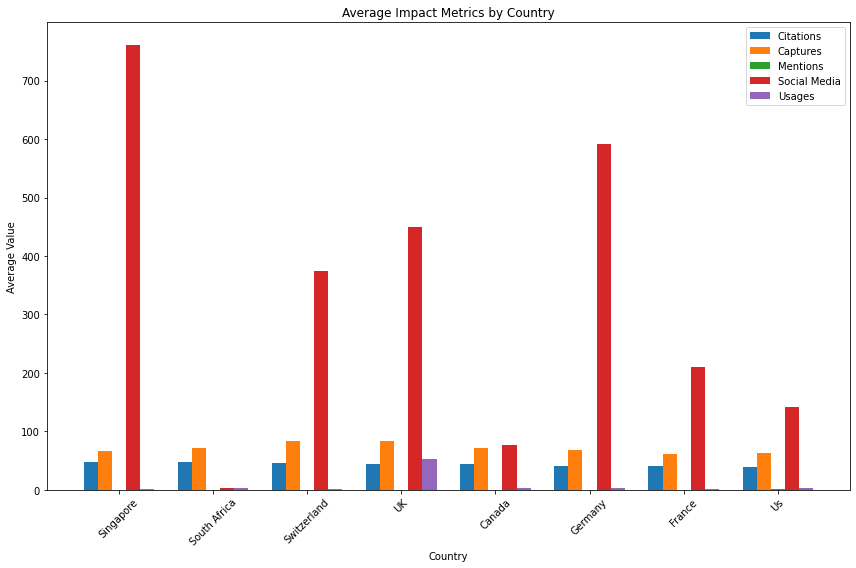

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Group by country and calculate average metrics
country_metrics = df.groupby('Country').agg({
    'Citations': 'mean',
    'Captures': 'mean',
    'Mentions': 'mean',
    'Social Media': 'mean',
    'Usages': 'mean'
}).reset_index()

# Sort by citations for better visualization
country_metrics = country_metrics.sort_values('Citations', ascending=False)

# Select top 10 countries by citations
top_countries = country_metrics.head(10)

# Create a grouped bar chart
plt.figure(figsize=(12, 8))
x = np.arange(len(top_countries))
width = 0.15

# Plot each metric as a separate bar
plt.bar(x - 2*width, top_countries['Citations'], width, label='Citations')
plt.bar(x - width, top_countries['Captures'], width, label='Captures')
plt.bar(x, top_countries['Mentions'], width, label='Mentions')
plt.bar(x + width, top_countries['Social Media'], width, label='Social Media')
plt.bar(x + 2*width, top_countries['Usages'], width, label='Usages')

plt.xlabel('Country')
plt.ylabel('Average Value')
plt.title('Average Impact Metrics by Country')
plt.xticks(x, top_countries['Country'], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

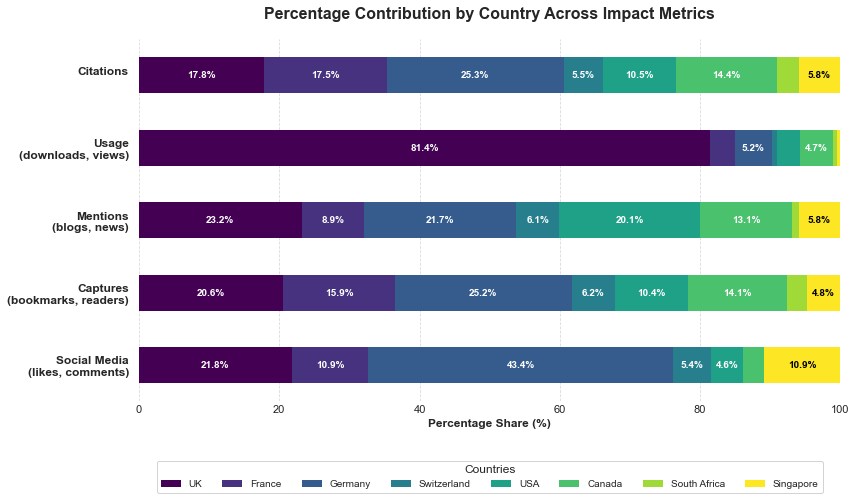

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# Assuming df contains Country column and metrics columns
metrics = ['Social Media', 'Captures', 'Mentions', 'Usages', 'Citations']

# Empty DataFrame to store the percentage contributions
result_df = pd.DataFrame(index=metrics)

# For each metric, calculate the percentage contribution by country
for metric in metrics:
    country_sums = df.groupby('Country')[metric].sum()
    total = country_sums.sum()
    percentages = (country_sums / total * 100).round(1)
    
    # Add each country's percentage to the result DataFrame
    for country, pct in percentages.items():
        if country not in result_df.columns:
            result_df[country] = 0
        result_df.at[metric, country] = pct

# Fill NaN values with 0
result_df = result_df.fillna(0)

# Keep only top 10 countries by contribution and group others into "Other"
top_countries = result_df.sum().sort_values(ascending=False).head(10).index.tolist()

# Define manual preferred order
preferred_order = ['UK', 'France', 'Germany', 'Switzerland', 
                   'USA', 'Canada', 'South Africa', 'Singapore']

# Filter preferred_order to include only countries that are in top_countries
ordered_countries = [c for c in preferred_order if c in top_countries]

# If there are any remaining top countries (not in preferred order), append them
remaining_countries = [c for c in top_countries if c not in ordered_countries]

# Final order
final_countries = ordered_countries + remaining_countries

# If "Other" exists, add it at the end
if 'Other' in result_df.columns:
    final_countries.append('Other')

# Reorder columns
result_df = result_df[final_countries]

# Create a smooth transitional color palette
n_colors = len(result_df.columns)
cmap = cm.get_cmap('viridis')  # smooth colormap (you can also try 'plasma', 'cividis', etc.)
colors = [cmap(i / (n_colors-1)) for i in range(n_colors)]

# Assign colors to countries
if 'Other' in result_df.columns:
    color_dict = {country: color for country, color in zip(result_df.columns[:-1], colors)}
    color_dict['Other'] = (0.85, 0.85, 0.85)  # Light gray for "Other"
else:
    color_dict = {country: color for country, color in zip(result_df.columns, colors)}

# Set up the figure with transparent background
plt.style.use('seaborn-whitegrid') 
fig, ax = plt.subplots(figsize=(12, 8), facecolor='none') 
ax.set_facecolor('none') 

# Plot
result_df.plot(kind='barh', stacked=True, ax=ax, color=[color_dict[c] for c in result_df.columns])

# Enhance the appearance
ax.set_xlabel('Percentage Share (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('')  # Remove y-label as metric names are self-explanatory
ax.set_title('Percentage Contribution by Country Across Impact Metrics', fontsize=16, fontweight='bold', pad=20)
ax.set_xlim(0, 100)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='y', which='major', pad=10)

custom_labels = [
    "Social Media\n(likes, comments)",
    "Captures\n(bookmarks, readers)",
    "Mentions\n(blogs, news)",
    "Usage\n(downloads, views)",
    "Citations\n",
]

ax.set_yticklabels(custom_labels, fontsize=12, fontweight='bold')

# Style the spines
for spine in ax.spines.values():
    spine.set_visible(False)

# Add percentage annotations
for i, metric in enumerate(result_df.index):
    cumulative = 0
    for country in result_df.columns:
        value = result_df.at[metric, country]
        if value > 4:  # Only label percentages > 4% to avoid clutter
            text_color = 'white' if sum(color_dict[country][:3]) < 1.5 else 'black'
            ax.text(cumulative + value/2, i, f"{value:.1f}%", 
                    ha='center', va='center', fontsize=10, fontweight='bold',
                    color=text_color)
        cumulative += value

# Improve legend - position it below the chart for better slide layout
legend = ax.legend(title='Countries', 
                   labels=result_df.columns,  # Force correct order
                   ncol=len(result_df.columns),  # One row horizontally
                   loc='upper center', bbox_to_anchor=(0.5, -0.15),
                   frameon=True, fontsize=10, title_fontsize=12)
legend.get_frame().set_facecolor('none')  # Make legend background transparent
legend.get_frame().set_alpha(1.0)  # Set to fully visible
legend.get_frame().set_edgecolor('lightgray')

# Add subtle grid lines only on the x-axis
ax.grid(axis='x', linestyle='--', alpha=0.3, color='gray')

# Adjust layout
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# Save with transparent background
plt.savefig('metric_country_distribution.png', dpi=1000, bbox_inches='tight', 
            transparent=True)  # Set transparent=True
plt.savefig('metric_country_distribution.pdf', bbox_inches='tight', 
            transparent=True)  # Set transparent=True for PDF

plt.show()

C:\Users\aznur\AppData\Local\Temp/ipykernel_16500/1680452364.py:41: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\aznur\AppData\Local\Temp/ipykernel_16500/1680452364.py:42: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\aznur\AppData\Local\Temp/ipykernel_16500/1680452364.py:47: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pa

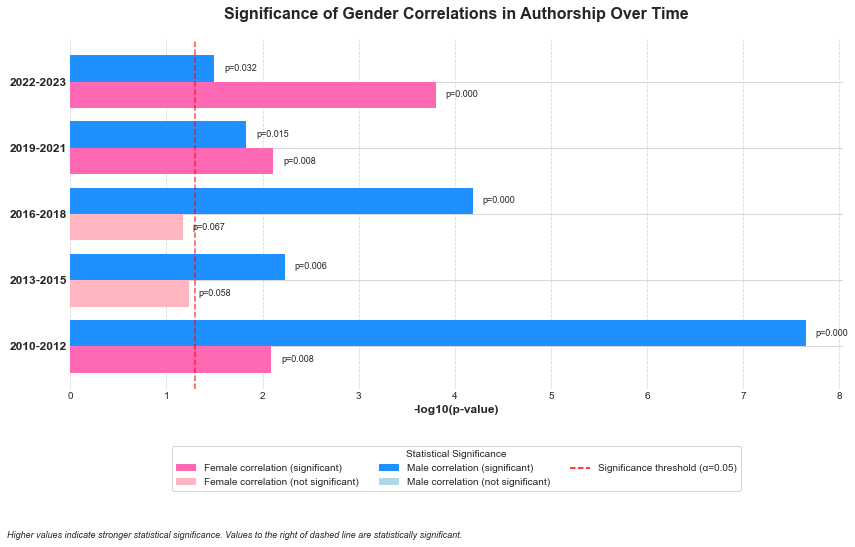

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency

# First, define your cramerv_corrected function since it's used in significance_and_correlation
def cramerv_corrected(x, y):
    """Calculate Cramer's V correlation with bias correction"""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2/n
    r, k = confusion_matrix.shape
    
    # Correction factor
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

def significance_and_correlation(start_year, end_year, time_period, df, alpha, title=None):
    
    p_values_female = []
    p_values_male = []
    time_periods = []
    
    for year in range(start_year, end_year, time_period):
        period_end_year = min(year + time_period - 1, 2023)
        # print(f"Time Period: {year} - {period_end_year}")
        time_periods.append(f"{year}-{period_end_year}")

        df_filtered = df[(df['Publication Year'] >= year) & (df['Publication Year'] <= period_end_year)]
    
        if title is not None:
            df_filtered = df_filtered[df_filtered['Publication Title'] == title]
            # print(f"Publication Title: {title}")

        # Calculate count of females and males in authors_genders for each row
        df_filtered['Count_Female'] = df_filtered['Gender (Authors)'].apply(lambda x: x.count(0) if isinstance(x, list) else 0)
        df_filtered['Count_Male'] = df_filtered['Gender (Authors)'].apply(lambda x: x.count(1) if isinstance(x, list) else 0)

        # Prepare the contingency tables
        if 'first_author_gender' not in df_filtered.columns:
            # Assuming Gender (First Author) is your first author gender column
            df_filtered['first_author_gender'] = df_filtered['Gender (First Author)']

        # Skip if not enough data for this time period
        if len(df_filtered) < 5 or df_filtered['first_author_gender'].nunique() < 2:
            # print(f"Insufficient data for time period {year}-{period_end_year}, skipping...")
            p_values_female.append(1.0)  # non-significant value as placeholder
            p_values_male.append(1.0)
            continue

        # Create contingency tables
        contingency_table_female = pd.crosstab(df_filtered['first_author_gender'], df_filtered['Count_Female'])
        
        # Ensure we have more than 1 column for chi-square (otherwise, it'll error)
        if contingency_table_female.shape[1] < 2:
            # print("Not enough variation in female count for chi-square test")
            p_values_female.append(1.0)
        else:
            # Limit columns to avoid sparse data, keep a max of 8 columns
            max_cols = min(9, contingency_table_female.shape[1])
            chi2_female, p_value_female, _, _ = chi2_contingency(contingency_table_female.iloc[:, :max_cols])
            # print(f"p-value for females: {p_value_female}")
            p_values_female.append(p_value_female)

        contingency_table_male = pd.crosstab(df_filtered['first_author_gender'], df_filtered['Count_Male'])
        
        if contingency_table_male.shape[1] < 2:
            # print("Not enough variation in male count for chi-square test")
            p_values_male.append(1.0)
        else:
            max_cols = min(9, contingency_table_male.shape[1]) 
            chi2_male, p_value_male, _, _ = chi2_contingency(contingency_table_male.iloc[:, :max_cols])
            # print(f"p-value for males: {p_value_male}")
            p_values_male.append(p_value_male)

        # Calculate correlation coefficients (if needed for additional analysis)
        corr_female = cramerv_corrected(df_filtered['first_author_gender'], df_filtered['Count_Female'])
        # print(f"Cramer's V (Female): {corr_female:.2f}")

        corr_male = cramerv_corrected(df_filtered['first_author_gender'], df_filtered['Count_Male'])
        # print(f"Cramer's V (Male): {corr_male:.2f}")

        # print("\n")
        
    return p_values_female, p_values_male, time_periods

# Parameters
start_year = 2010
end_year = 2024  # End at 2024 to include 2023 data
time_period = 3
alpha = 0.05

# Calculate p-values using your actual data
p_values_female, p_values_male, time_periods = significance_and_correlation(
    start_year, end_year, time_period, df, alpha)

# Create a DataFrame for plotting
data = {
    'Time Period': time_periods,
    'Female p-value': p_values_female,
    'Male p-value': p_values_male
}
df_plot = pd.DataFrame(data)

# Create significance flags
df_plot['Female Significant'] = df_plot['Female p-value'] <= alpha
df_plot['Male Significant'] = df_plot['Male p-value'] <= alpha

# Calculate -log10(p-value) for better visualization
# Add a small constant to avoid log(0)
df_plot['Female -log10(p)'] = -np.log10(df_plot['Female p-value'] + 1e-10)
df_plot['Male -log10(p)'] = -np.log10(df_plot['Male p-value'] + 1e-10)

# Set up the figure with transparent background
plt.style.use('seaborn-whitegrid')  # Updated style name
fig, ax = plt.subplots(figsize=(12, 8), facecolor='none')
ax.set_facecolor('none')

# Plot bars for female p-values
female_bars = ax.barh(
    y=np.arange(len(time_periods)) - 0.2,
    width=df_plot['Female -log10(p)'],
    height=0.4,
    color=['#FF69B4' if sig else '#FFB6C1' for sig in df_plot['Female Significant']],
    label='Female authors correlation'
)

# Plot bars for male p-values
male_bars = ax.barh(
    y=np.arange(len(time_periods)) + 0.2,
    width=df_plot['Male -log10(p)'],
    height=0.4,
    color=['#1E90FF' if sig else '#ADD8E6' for sig in df_plot['Male Significant']],
    label='Male authors correlation'
)

# Add significance threshold line
significance_line = -np.log10(alpha)
ax.axvline(x=significance_line, color='red', linestyle='--', alpha=0.7, 
           label=f'Significance threshold (α={alpha})')

# Add p-value annotations
for i, row in df_plot.iterrows():
    # Female p-value
    ax.text(
        row['Female -log10(p)'] + 0.1, 
        i - 0.2, 
        f"p={row['Female p-value']:.3f}", 
        va='center',
        fontsize=9
    )
    # Male p-value
    ax.text(
        row['Male -log10(p)'] + 0.1, 
        i + 0.2, 
        f"p={row['Male p-value']:.3f}", 
        va='center',
        fontsize=9
    )

# Enhance the appearance
ax.set_yticks(range(len(time_periods)))
ax.set_yticklabels(time_periods, fontsize=12, fontweight='bold')
ax.set_xlabel('-log10(p-value)', fontsize=12, fontweight='bold')
ax.set_title('Significance of Gender Correlations in Authorship Over Time', 
             fontsize=16, fontweight='bold', pad=20)

# Style the spines
for spine in ax.spines.values():
    spine.set_visible(False)

# Create custom legend with better descriptions
legend_elements = [
    Patch(facecolor='#FF69B4', label='Female correlation (significant)'),
    Patch(facecolor='#FFB6C1', label='Female correlation (not significant)'),
    Patch(facecolor='#1E90FF', label='Male correlation (significant)'),
    Patch(facecolor='#ADD8E6', label='Male correlation (not significant)')
]
legend = ax.legend(
    handles=legend_elements + [plt.Line2D([0], [0], color='red', linestyle='--', label=f'Significance threshold (α={alpha})')],
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15),
    ncol=3, 
    frameon=True, 
    fontsize=10, 
    title='Statistical Significance'
)
legend.get_frame().set_facecolor('none')
legend.get_frame().set_alpha(1.0)
legend.get_frame().set_edgecolor('lightgray')

# Add explanatory text
plt.figtext(0.01, 0.01, "Higher values indicate stronger statistical significance. Values to the right of dashed line are statistically significant.",
           fontsize=9, style='italic')

# Add grid lines
ax.grid(axis='x', linestyle='--', alpha=0.3, color='gray')

# Adjust layout and save
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig('gender_correlation_significance.png', dpi=300, bbox_inches='tight', transparent=True)
plt.savefig('gender_correlation_significance.pdf', bbox_inches='tight', transparent=True)

plt.show()

C:\Users\aznur\AppData\Local\Temp/ipykernel_21316/1551040533.py:52: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\aznur\AppData\Local\Temp/ipykernel_21316/1551040533.py:54: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\aznur\AppData\Local\Temp/ipykernel_21316/1551040533.py:71: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pa

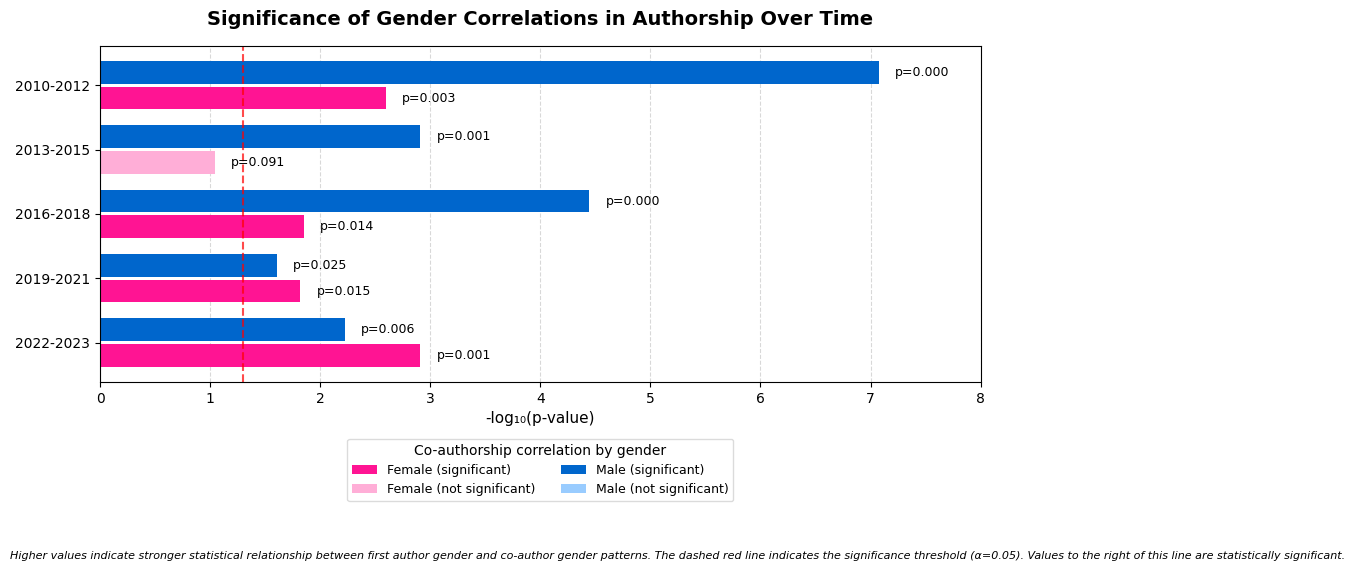

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from matplotlib.patches import Patch

# Function to run the statistical analysis
def analyze_gender_correlation(df, start_year=2010, end_year=2024, time_period=3, alpha=0.05):
    """
    Analyzes correlation between first author gender and co-author gender composition
    over specified time periods.
    
    Parameters:
    -----------
    df : pandas DataFrame
        Dataset containing publication data with gender information
    start_year, end_year : int
        Range of years to analyze
    time_period : int
        Length of each time period in years
    alpha : float
        Significance threshold
        
    Returns:
    --------
    DataFrame with p-values and significance indicators for each time period
    """
    results = []
    
    for year in range(start_year, end_year, time_period):
        period_end = min(year + time_period - 1, 2023)
        period = f"{year}-{period_end}"
        
        # Filter data for time period
        period_df = df[(df['Publication Year'] >= year) & (df['Publication Year'] <= period_end)]
        n_papers = len(period_df)
        
        if n_papers < 10:
            results.append({
                'period': period,
                'female_p': 1.0, 
                'male_p': 1.0,
                'female_sig': False,
                'male_sig': False,
                'n_papers': n_papers
            })
            continue
        
        # Process gender data for each paper
        # 1. Calculate number of co-authors by gender
        # Extract the gender lists and calculate counts
        period_df['female_coauthors'] = period_df['Gender (Authors)'].apply(
            lambda x: x.count(0) if isinstance(x, list) else 0)
        period_df['male_coauthors'] = period_df['Gender (Authors)'].apply(
            lambda x: x.count(1) if isinstance(x, list) else 0)
        
        try:
            # For female co-authors
            female_table = pd.crosstab(period_df['Gender (First Author)'], 
                                      period_df['female_coauthors'])
            
            # If the table is too sparse (many zeros), we may need to bin categories
            if female_table.shape[1] > 4:  # If there are many columns
                # Combine higher counts to reduce sparsity
                def bin_counts(x):
                    if x <= 3:
                        return x
                    else:
                        return 4  # 4+ category
                
                period_df['female_binned'] = period_df['female_coauthors'].apply(bin_counts)
                female_table = pd.crosstab(period_df['Gender (First Author)'], 
                                         period_df['female_binned'])
            
            # Calculate chi-square
            chi2_female, p_female, dof_female, expected_female = chi2_contingency(female_table)
            
            # For male co-authors (same process)
            male_table = pd.crosstab(period_df['Gender (First Author)'], 
                                   period_df['male_coauthors'])
            
            if male_table.shape[1] > 4:
                period_df['male_binned'] = period_df['male_coauthors'].apply(bin_counts)
                male_table = pd.crosstab(period_df['Gender (First Author)'], 
                                       period_df['male_binned'])
            
            chi2_male, p_male, dof_male, expected_male = chi2_contingency(male_table)
            
        except Exception as e:
            p_female, p_male = 1.0, 1.0
        
        # Store results
        results.append({
            'period': period,
            'female_p': p_female,
            'male_p': p_male,
            'female_sig': p_female <= alpha,
            'male_sig': p_male <= alpha,
            'n_papers': n_papers
        })
    
    return pd.DataFrame(results)

# Run the analysis
alpha = 0.05
results = analyze_gender_correlation(df, alpha=alpha)

# Visualization code
plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 6), facecolor='none')
ax.set_facecolor('none')

# Calculate -log10(p) for visualization
results['female_log_p'] = -np.log10(results['female_p'] + 1e-10)
results['male_log_p'] = -np.log10(results['male_p'] + 1e-10)

# Plot bars in reverse order for chronological display (newest at top)
y_positions = np.arange(len(results))
reversed_results = results.iloc[::-1].reset_index(drop=True)

# Plot female correlation bars
female_bars = ax.barh(
    y=y_positions - 0.2,
    width=reversed_results['female_log_p'],
    height=0.35,
    color=['#FF1493' if sig else '#FFAED7' for sig in reversed_results['female_sig']],
    label='Female correlation'
)

# Plot male correlation bars
male_bars = ax.barh(
    y=y_positions + 0.2,
    width=reversed_results['male_log_p'],
    height=0.35,
    color=['#0066CC' if sig else '#99CCFF' for sig in reversed_results['male_sig']],
    label='Male correlation'
)

# Add significance threshold line
significance_line = -np.log10(alpha)
ax.axvline(x=significance_line, color='red', linestyle='--', alpha=0.7)

# Add p-value annotations with better positioning
for i, row in reversed_results.iterrows():
    # Female p-value
    x_pos = min(row['female_log_p'] + 0.15, 7.8)
    ax.text(
        x_pos,
        i - 0.2,
        f"p={row['female_p']:.3f}",
        va='center',
        fontsize=9,
        color='black'
    )
    
    # Male p-value
    x_pos = min(row['male_log_p'] + 0.15, 7.8)
    ax.text(
        x_pos,
        i + 0.2,
        f"p={row['male_p']:.3f}",
        va='center',
        fontsize=9,
        color='black'
    )

# Enhance the appearance
ax.set_yticks(y_positions)
ax.set_yticklabels(reversed_results['period'], fontsize=10)
ax.set_xlabel('-log₁₀(p-value)', fontsize=11)
ax.set_title('Significance of Gender Correlations in Authorship Over Time', 
             fontsize=14, fontweight='bold', pad=15)

# Add grid lines
ax.grid(axis='x', linestyle='--', alpha=0.3, color='gray')
ax.set_axisbelow(True)  # Put gridlines behind bars

# Set x-limits to ensure consistent display
ax.set_xlim(0, 8)  # Adjust based on your largest value

# Create a legend with two columns as requested
legend_elements = [
    # Female column
    Patch(facecolor='#FF1493', label='Female (significant)'),
    Patch(facecolor='#FFAED7', label='Female (not significant)'),
    # Male column
    Patch(facecolor='#0066CC', label='Male (significant)'),
    Patch(facecolor='#99CCFF', label='Male (not significant)'),
]

# Create the legend with 2 columns (female left, male right)
legend = ax.legend(
    handles=legend_elements,
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=True,
    fontsize=9,
    title="Co-authorship correlation by gender"
)

# Set the frame properties
legend.get_frame().set_facecolor('none')
legend.get_frame().set_edgecolor('lightgray')

# Add explanatory text for significance threshold outside the legend box
plt.figtext(0.01, 0.01, 
            "Higher values indicate stronger statistical relationship between first author gender and co-author gender patterns. " +
            f"The dashed red line indicates the significance threshold (α={alpha}). Values to the right of this line are statistically significant.",
            fontsize=8, style='italic')

# Tighten layout to prevent overlap
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig('gender_correlation_significance_updated.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Gender distribution analysis, citations, authorship

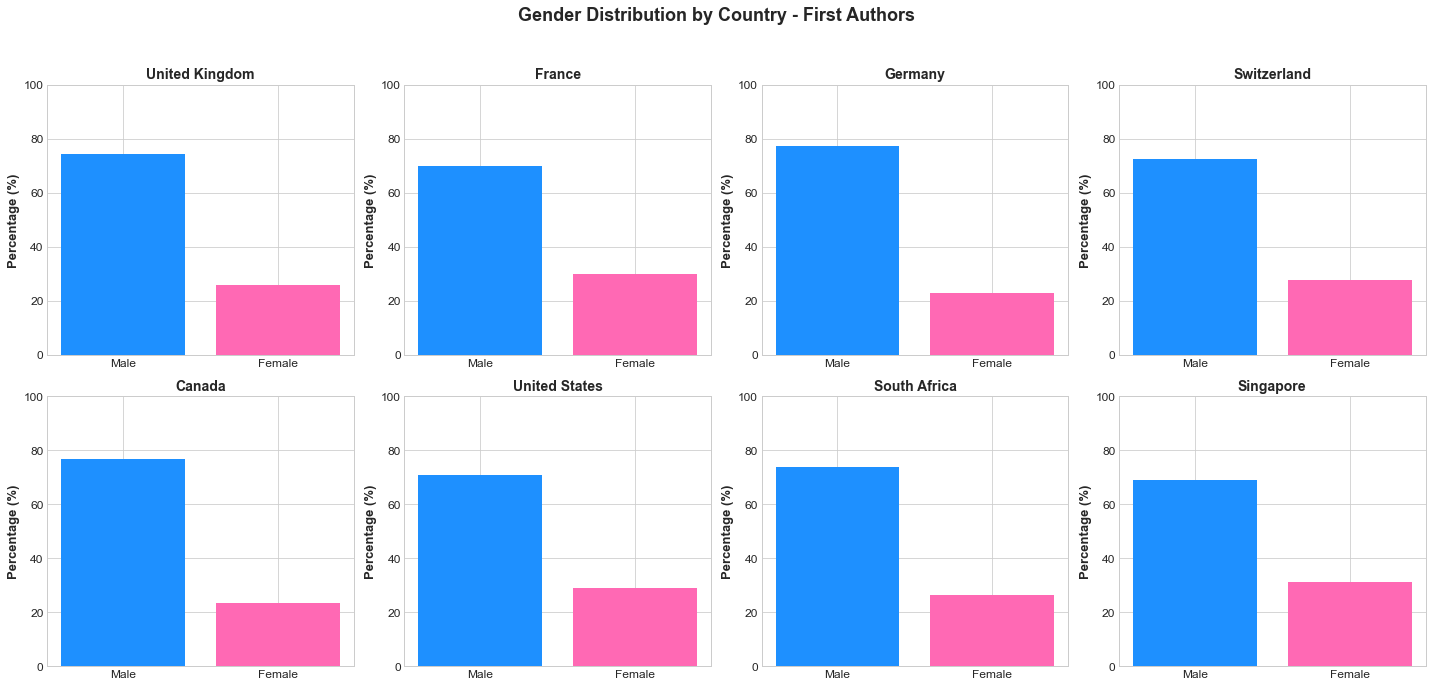

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Countries to analyze
target_countries = ['UK', 'France', 'Germany', 'Switzerland', 'Canada', 'USA', 'South Africa', 'Singapore']

# Set up the figure
fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axs = axs.flatten()

for idx, country in enumerate(target_countries):
    country_df = df[df['Country'] == country]
    
    if country_df.empty:
        continue
    
    fa = country_df['Gender (First Author)'].dropna().str.lower()  # make lowercase to avoid case issues
    gender_dist = fa.value_counts(normalize=True) * 100  # percentage distribution
    
    ax = axs[idx]
    ax.bar(['Male', 'Female'],
           [gender_dist.get('male', 0), gender_dist.get('female', 0)],
           color=['#1E90FF', '#FF69B4'])
    
    ax.set_title(country_names.get(country, country), fontsize=14, fontweight='bold')
    ax.set_ylabel('Percentage (%)', fontsize=13, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='both', labelsize=12)

plt.suptitle('Gender Distribution by Country - First Authors', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

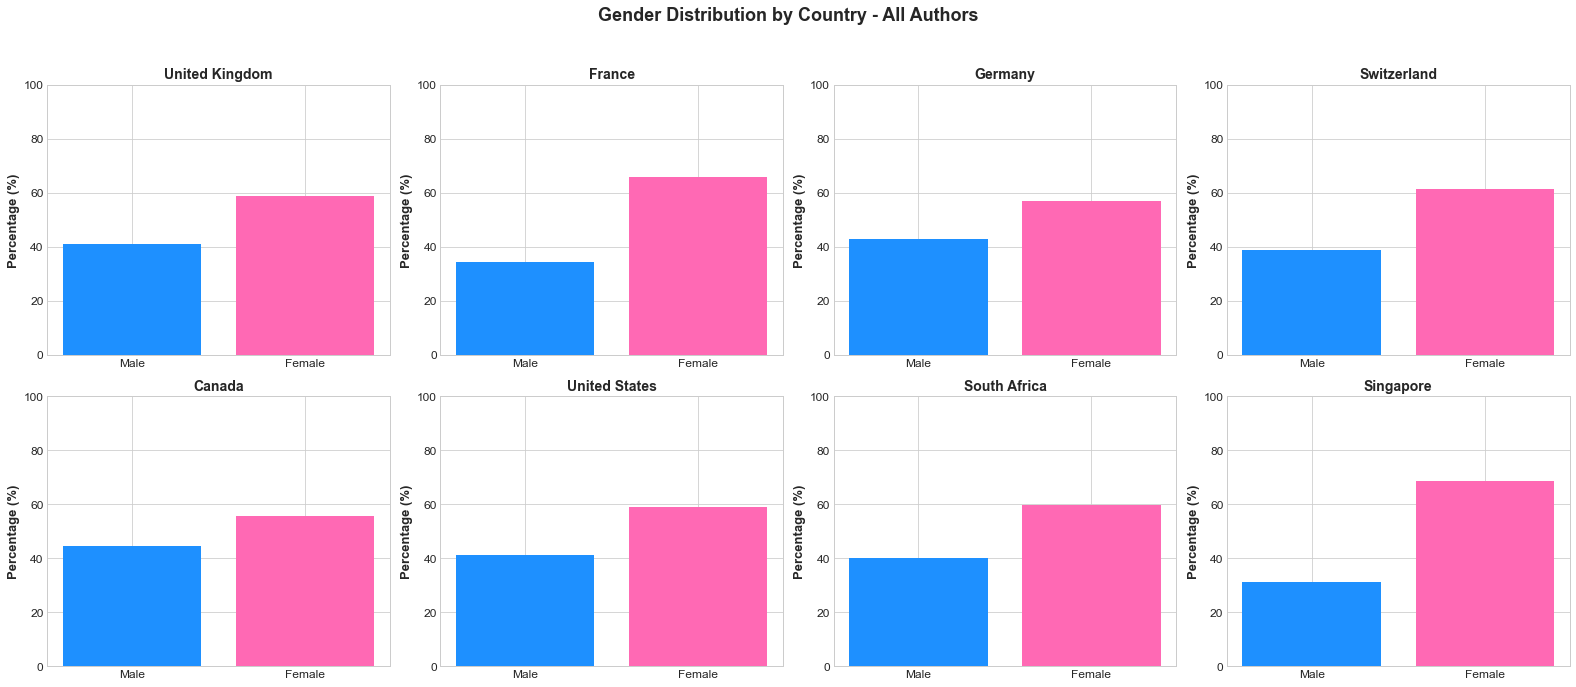

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import chain

# Countries to analyze
target_countries = ['UK', 'France', 'Germany', 'Switzerland', 'Canada', 'USA', 'South Africa', 'Singapore']

# Set up figure: 2 rows x 4 columns = 8 plots (7 countries + 1 overall)
fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(22, 10))
axs = axs.flatten()

for idx, country in enumerate(target_countries):
    country_df = df[df['Country'] == country]
    
    if country_df.empty:
        continue
    
    # First Author Genders
    fa = country_df['Gender (First Author)'].dropna().str.lower()
    fa = fa[fa.isin(['male', 'female'])]  # keep only valid entries
    
    # All Authors Genders
    oa = country_df['Gender (Authors)'].dropna()
    oa_lists = oa.apply(ast.literal_eval)  # <-- convert text to real list
    oa_flat = list(chain.from_iterable(oa_lists))
    oa_flat = pd.Series(oa_flat).dropna().str.lower()
    oa_flat = oa_flat[oa_flat.isin(['male', 'female'])]
    
    # Combine all
    all_genders = pd.concat([fa, oa_flat])
    
    if all_genders.empty:
        continue  # skip if no valid gender data
    
    gender_dist = all_genders.value_counts(normalize=True) * 100  # calculate percentages

    ax = axs[idx]
    ax.bar(['Male', 'Female'],
           [gender_dist.get('male', 0), gender_dist.get('female', 0)],
           color=['#1E90FF', '#FF69B4'])
    
    ax.set_title(country_names.get(country, country), fontsize=14, fontweight='bold')
    ax.set_ylabel('Percentage (%)', fontsize=13, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='both', labelsize=12)

# Final touches
plt.suptitle('Gender Distribution by Country - All Authors', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

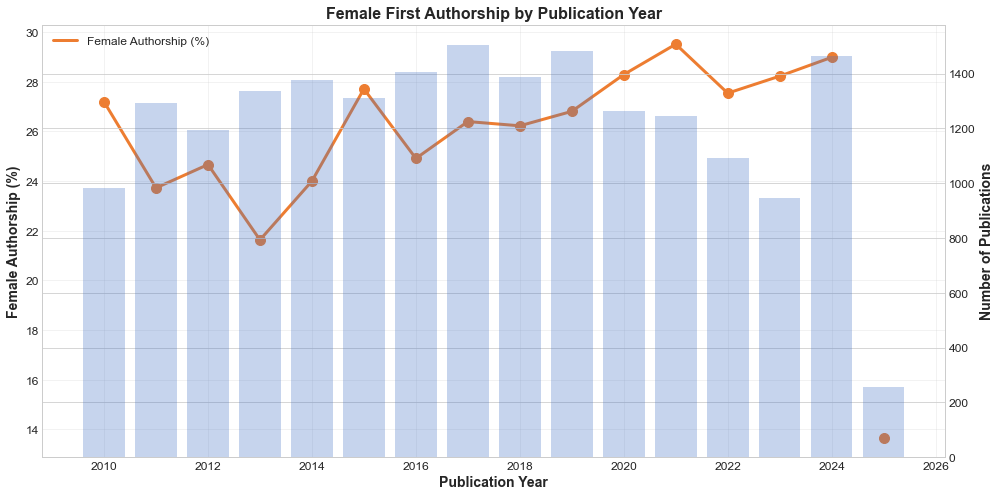

Linear regression for female authorship over time: r=0.009, p=0.9739


In [52]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

df['is_female'] = df['Gender (First Author)'].map({'female': 1, 'male': 0})

# Gender distribution and number of publications by year
gender_by_year = df.groupby('Publication Year')['is_female'].mean() * 100
total_by_year = df.groupby('Publication Year').size()

# Filter data for line (2010-2024) and marker (2025)
line_data = gender_by_year[(gender_by_year.index.astype(int) >= 2010) & (gender_by_year.index.astype(int) <= 2024)]
marker_2025 = gender_by_year[gender_by_year.index.astype(int) == 2025]

plt.figure(figsize=(14, 7), facecolor='none', edgecolor='none')
ax1 = plt.subplot(111)

# Plot female authorship percentage as a line (2010-2024)
ax1.plot(line_data.index, line_data.values, '-', linewidth=3, color='#ED7D31', label='Female Authorship (%)')

# Add markers for all years
ax1.plot(gender_by_year.index, gender_by_year.values, 'o', markersize=10, color='#ED7D31')

# Main axis formatting
ax1.set_xlabel('Publication Year', fontsize=14, fontweight='bold')
ax1.set_ylabel('Female Authorship (%)', fontsize=14, fontweight='bold')
ax1.set_title('Female First Authorship by Publication Year', fontsize=16, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Add secondary axis for publication volume
ax2 = ax1.twinx()
ax2.bar(total_by_year.index, total_by_year.values, alpha=0.3, color='#4472C4', label='Number of Publications')
ax2.set_ylabel('Number of Publications', fontsize=14, fontweight='bold')

# Trend line
# years = gender_by_year.index.astype(int)
# slope, intercept, r_value, p_value, std_err = stats.linregress(years, gender_by_year.values)
# trend_line = slope * years + intercept
# ax1.plot(years, trend_line, '--', color='#7030A0', linewidth=2, label=f'Trend (r={r_value:.2f})')

# Add legend
ax1.legend(loc='upper left', fontsize=12)

# Ticks formatting
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.savefig('female_authorship_trend.png', 
            dpi=300, 
            bbox_inches='tight', 
            transparent=True)

plt.tight_layout()
plt.show()

# Statistical test: Check if there’s a significant trend
print(f"Linear regression for female authorship over time: r={r_value:.3f}, p={p_value:.4f}")


In [20]:
gender_by_year


Publication Year
2010    27.189409
2011    23.724884
2012    24.665552
2013    21.631737
2014    24.000000
2015    27.709924
2016    24.911032
2017    26.396277
2018    26.224784
2019    26.806212
2020    28.288431
2021    29.510826
2022    27.538884
2023    28.224101
2024    28.981545
2025    13.671875
Name: Gender (First Author), dtype: float64

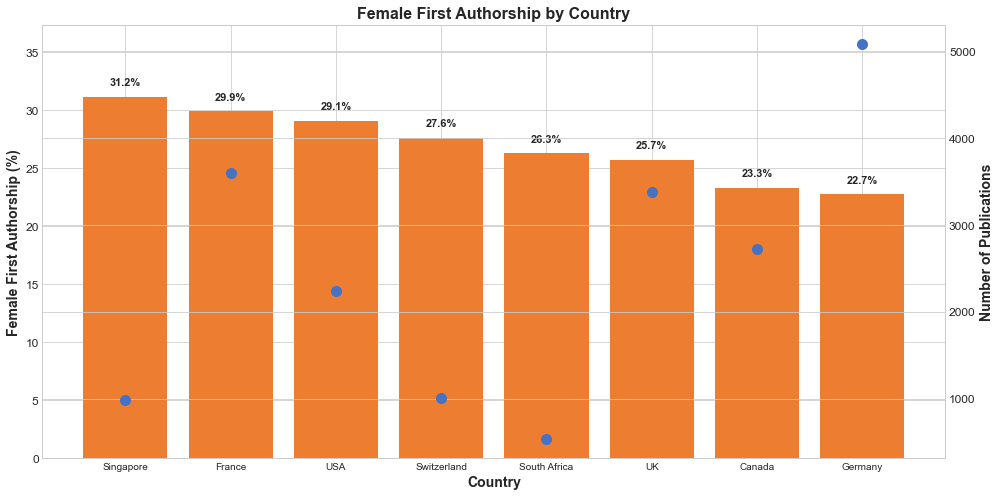

Overall average female first authorship: 26.2%
Chi-square test for independence between country and gender: χ²=92.56, p=0.000000


In [52]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# Gender distribution and number of publications by country
gender_by_country = df.groupby('Country')['Gender (First Author)'].mean() * 100
publications_by_country = df.groupby('Country').size()

# Sort by female authorship %
gender_by_country = gender_by_country.sort_values(ascending=False)
publications_by_country = publications_by_country.reindex(gender_by_country.index)

plt.figure(figsize=(14, 7))
ax1 = plt.subplot(111)
bars = ax1.bar(gender_by_country.index, gender_by_country.values, color='#ED7D31')

# Main axis formatting
ax1.set_xlabel('Country', fontsize=14, fontweight='bold')
ax1.set_ylabel('Female First Authorship (%)', fontsize=14, fontweight='bold')
ax1.set_title('Female First Authorship by Country', fontsize=16, fontweight='bold')
ax1.set_ylim(0, max(gender_by_country.values) * 1.2)

# Data labels for bars
for i, v in enumerate(gender_by_country.values):
    ax1.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=11, fontweight='bold')

# Secondary axis with scatter plot for publication counts
ax2 = ax1.twinx()
ax2.scatter(publications_by_country.index, publications_by_country.values, color='#4472C4', s=100, zorder=5)
ax2.set_ylabel('Number of Publications', fontsize=14, fontweight='bold')

# Tick formatting
plt.xticks(rotation=45, ha='right', fontsize=12)
ax1.tick_params(axis='y', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.show()

# Overall average female authorship
overall_avg = df['Gender (First Author)'].mean() * 100
print(f"Overall average female first authorship: {overall_avg:.1f}%")

# Chi-square test for independence
contingency_table = pd.crosstab(df['Country'], df['Gender (First Author)'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square test for independence between country and gender: χ²={chi2:.2f}, p={p:.6f}")

Average citations for male first authors: nan
Average citations for female first authors: nan
T-test for citation differences: t=nan, p=nan


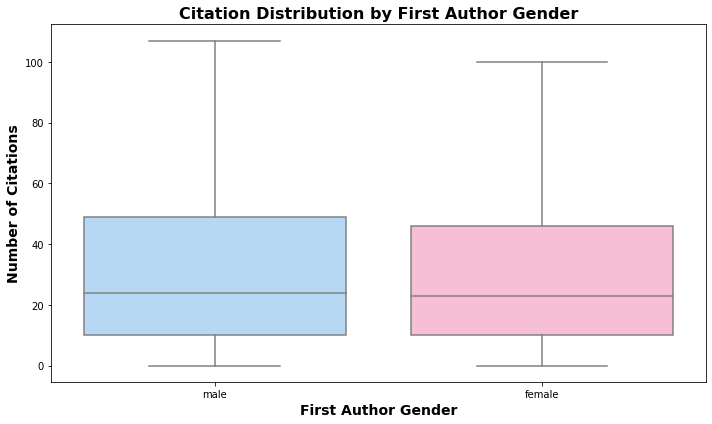

In [8]:
# Compare citations by gender
male_citations = df[df['Gender (First Author)'] == 0]['Citations'].mean()
female_citations = df[df['Gender (First Author)'] == 1]['Citations'].mean()

# Conduct t-test to check if difference is significant
t_stat, p_val = stats.ttest_ind(
    df[df['Gender (First Author)'] == 'male']['Citations'],
    df[df['Gender (First Author)'] == 'female']['Citations'],
    equal_var=False  # Welch's t-test (doesn't assume equal variances)
)

print(f"Average citations for male first authors: {male_citations:.2f}")
print(f"Average citations for female first authors: {female_citations:.2f}")
print(f"T-test for citation differences: t={t_stat:.3f}, p={p_val:.4f}")

# Visualize citation distribution by gender with adjusted colors
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Gender (First Author)'], y=df['Citations'], showfliers=False, 
            palette=['#ADD8FF', '#FFB6D5'])  # Different color scheme

# Set title and axis labels with larger fonts and bold
plt.title('Citation Distribution by First Author Gender', fontsize=16, fontweight='bold')
plt.xlabel('First Author Gender', fontsize=14, fontweight='bold')
plt.ylabel('Number of Citations', fontsize=14, fontweight='bold')

# Adjust the layout to make sure the plot fits well
plt.tight_layout()
plt.show()

Average h-index for male first authors: 14.79
Average h-index for female first authors: 11.22
T-test for h-index differences: t=nan, p=nan


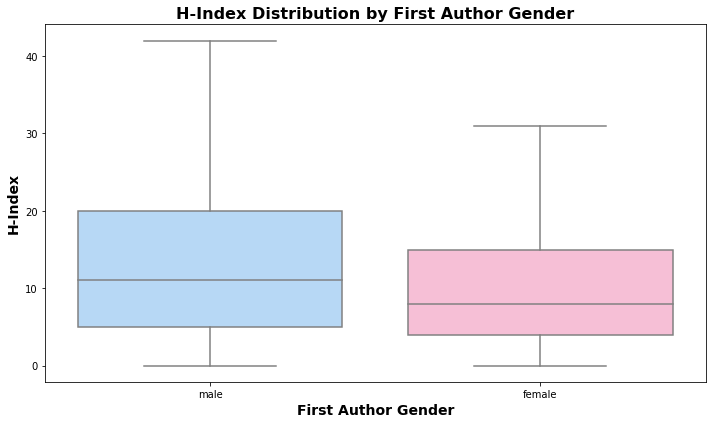

In [ ]:
# Compare h-index by gender
male_hindex = df[df['Gender (First Author)'] == 'male']['First Author H-Index'].mean()
female_hindex = df[df['Gender (First Author)'] == 'female']['First Author H-Index'].mean()

# T-test for h-index difference
t_stat_h, p_val_h = stats.ttest_ind(
    df[df['Gender (First Author)'] == 'male']['First Author H-Index'],
    df[df['Gender (First Author)'] == 'female']['First Author H-Index'],
    equal_var=False
)

print(f"Average h-index for male first authors: {male_hindex:.2f}")
print(f"Average h-index for female first authors: {female_hindex:.2f}")
print(f"T-test for h-index differences: t={t_stat_h:.3f}, p={p_val_h:.4f}")

gender_map_caps = {'male': 'Male', 'female': 'Female'}

# Visualize h-index distribution by gender with new colors
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Gender (First Author)'], y=df['First Author H-Index'], showfliers=False, 
            palette=['#ADD8FF', '#FFB6D5'])  # Light purple and soft green

# Set title and axis labels with larger fonts and bold
plt.title('H-Index Distribution by First Author Gender', fontsize=16, fontweight='bold')
plt.xlabel('First Author Gender', fontsize=14, fontweight='bold')
plt.ylabel('H-Index', fontsize=14, fontweight='bold')

# Adjust the layout to make sure the plot fits well
plt.tight_layout()
plt.show()


In [35]:
# Compare social media impact by gender
male_social = df[df['Gender (First Author)'] == 0]['Social Media'].mean()
female_social = df[df['Gender (First Author)'] == 1]['Social Media'].mean()

# T-test for social media impact
t_stat_s, p_val_s = stats.ttest_ind(
    df[df['Gender (First Author)'] == 0]['Social Media'],
    df[df['Gender (First Author)'] == 1]['Social Media'],
    equal_var=False
)

print(f"Average social media impact for male first authors: {male_social:.2f}")
print(f"Average social media impact for female first authors: {female_social:.2f}")
print(f"T-test for social media impact differences: t={t_stat_s:.3f}, p={p_val_s:.4f}")

Average social media impact for male first authors: 403.01
Average social media impact for female first authors: 220.01
T-test for social media impact differences: t=nan, p=nan


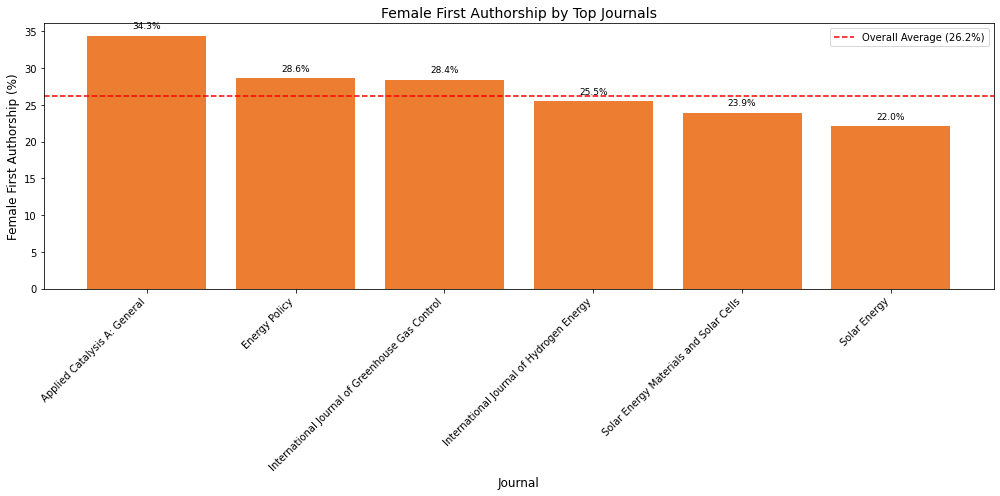

In [32]:
# If 'Publication Title' is available
if 'Publication Title' in df.columns:
    # Get top 10 journals by volume
    top_journals = df['Publication Title'].value_counts().head(10).index
    
    # Filter for these journals
    journal_data = df[df['Publication Title'].isin(top_journals)]
    
    # Calculate gender ratios
    journal_gender = journal_data.groupby('Publication Title')['Gender (First Author)'].mean() * 100
    journal_count = journal_data.groupby('Publication Title').size()
    
    # Sort by female percentage
    journal_gender = journal_gender.sort_values(ascending=False)
    journal_count = journal_count.reindex(journal_gender.index)
    
    # Plot
    plt.figure(figsize=(14, 7))
    ax1 = plt.subplot(111)
    ax1.bar(journal_gender.index, journal_gender.values, color='#ED7D31')
    ax1.set_xlabel('Journal', fontsize=12)
    ax1.set_ylabel('Female First Authorship (%)', fontsize=12)
    ax1.set_title('Female First Authorship by Top Journals', fontsize=14)
    
    # Add labels
    for i, v in enumerate(journal_gender.values):
        ax1.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=9)
    
    # Add reference line for overall average
    ax1.axhline(y=overall_avg, color='red', linestyle='--', label=f'Overall Average ({overall_avg:.1f}%)')
    ax1.legend()
    
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

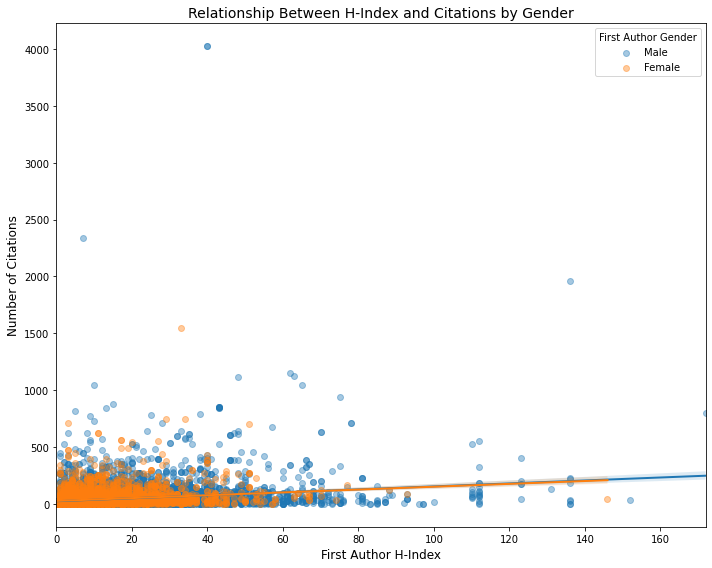

Correlation between h-index and citations for male first authors: 0.215
Correlation between h-index and citations for female first authors: 0.210


In [33]:
# Create a scatter plot with regression lines by gender
plt.figure(figsize=(10, 8))
for gender, label in gender_map.items():
    subset = df[df['Gender (First Author)'] == gender]
    sns.regplot(x='First Author H-Index', y='Citations', data=subset, scatter=True, 
                label=label, scatter_kws={'alpha':0.4}, line_kws={'linewidth':2})

plt.title('Relationship Between H-Index and Citations by Gender', fontsize=14)
plt.xlabel('First Author H-Index', fontsize=12)
plt.ylabel('Number of Citations', fontsize=12)
plt.legend(title='First Author Gender')
plt.tight_layout()
plt.show()

# Calculate correlations by gender
male_corr = df[df['Gender (First Author)'] == 0][['First Author H-Index', 'Citations']].corr().iloc[0,1]
female_corr = df[df['Gender (First Author)'] == 1][['First Author H-Index', 'Citations']].corr().iloc[0,1]

print(f"Correlation between h-index and citations for male first authors: {male_corr:.3f}")
print(f"Correlation between h-index and citations for female first authors: {female_corr:.3f}")

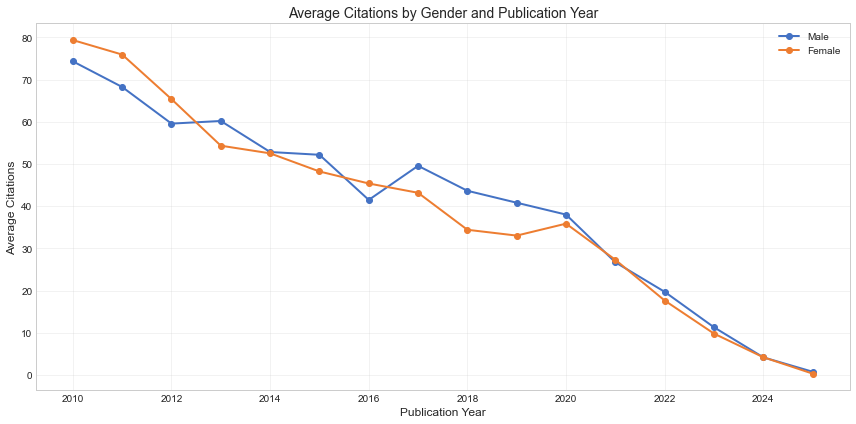

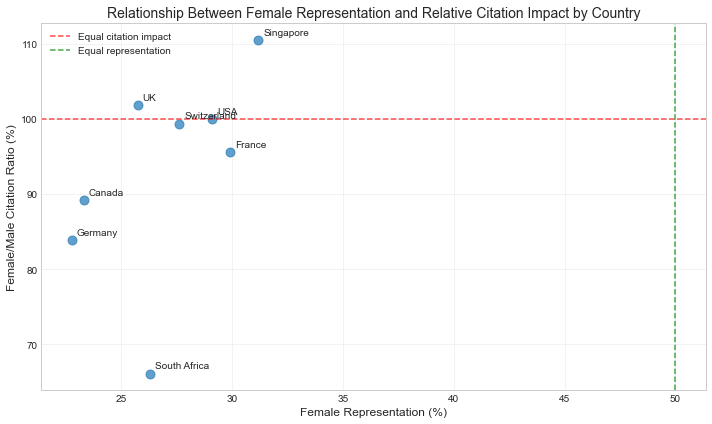

Correlation between female representation and F/M citation ratio: r=0.552, p=0.1559


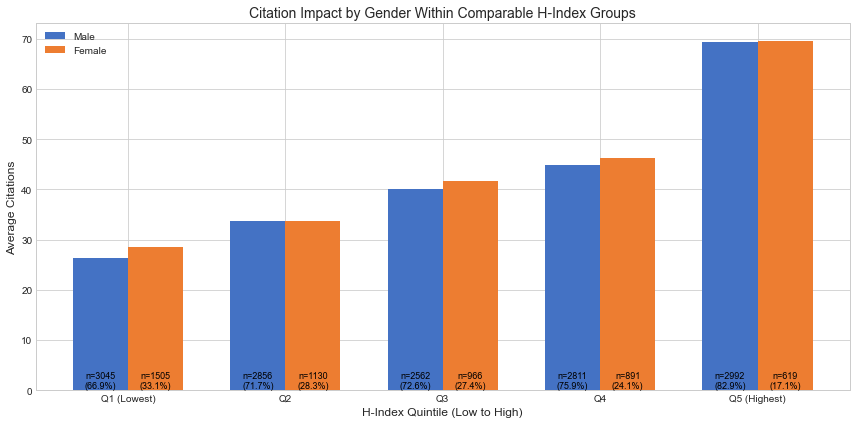


Citation differences controlling for comparable h-index groups:
H-Index Bin 1: Female citations are 8.3% higher than male citations (p=0.1307, n_male=3045, n_female=1505)
H-Index Bin 2: Female citations are -0.1% lower than male citations (p=0.9809, n_male=2856, n_female=1130)
H-Index Bin 3: Female citations are 4.0% higher than male citations (p=0.4687, n_male=2562, n_female=966)
H-Index Bin 4: Female citations are 3.3% higher than male citations (p=0.5139, n_male=2811, n_female=891)
H-Index Bin 5: Female citations are 0.2% higher than male citations (p=0.9758, n_male=2992, n_female=619)


In [55]:
# Let's conduct a more thorough analysis to address this question

# 1. Controlling for publication year (career stage effect)
year_gender_stats = df.groupby(['Publication Year', 'Gender (First Author)']).agg({
    'Citations': 'mean',
    'First Author H-Index': 'mean',
    'Gender (First Author)': 'count'
}).rename(columns={'Gender (First Author)': 'Count'})

# Reshape for easier comparison
year_gender_pivot = year_gender_stats.unstack(level=1)

# Plot citation differences controlling for year
plt.figure(figsize=(12, 6))
ax = plt.subplot(111)

# Extract male and female citation averages by year (ignoring missing values)
male_cites = year_gender_pivot['Citations'][0]
female_cites = year_gender_pivot['Citations'][1]
years = male_cites.index

ax.plot(years, male_cites, 'o-', label='Male', color='#4472C4', linewidth=2)
ax.plot(years, female_cites, 'o-', label='Female', color='#ED7D31', linewidth=2)
ax.set_xlabel('Publication Year', fontsize=12)
ax.set_ylabel('Average Citations', fontsize=12)
ax.set_title('Average Citations by Gender and Publication Year', fontsize=14)
ax.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Controlling for country (geographic effect)
country_gender_stats = df.groupby(['Country', 'Gender (First Author)']).agg({
    'Citations': 'mean',
    'First Author H-Index': 'mean',
    'Gender (First Author)': 'count'
}).rename(columns={'Gender (First Author)': 'Count'})

country_gender_pivot = country_gender_stats.unstack(level=1)

# Calculate the citation ratio (female/male) for each country
citation_ratio = country_gender_pivot['Citations'][1] / country_gender_pivot['Citations'][0]
representation_ratio = country_gender_pivot['Count'][1] / (country_gender_pivot['Count'][0] + country_gender_pivot['Count'][1])

# Plot the relationship between representation and citation impact
plt.figure(figsize=(10, 6))
plt.scatter(representation_ratio * 100, citation_ratio * 100, s=80, alpha=0.7)

# Add country labels
for i, country in enumerate(citation_ratio.index):
    plt.annotate(country, 
                 (representation_ratio[i] * 100, citation_ratio[i] * 100),
                 xytext=(5, 5), textcoords='offset points')

plt.axhline(y=100, color='red', linestyle='--', alpha=0.7, label='Equal citation impact')
plt.axvline(x=50, color='green', linestyle='--', alpha=0.7, label='Equal representation')
plt.xlabel('Female Representation (%)', fontsize=12)
plt.ylabel('Female/Male Citation Ratio (%)', fontsize=12)
plt.title('Relationship Between Female Representation and Relative Citation Impact by Country', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Calculate the correlation between representation and relative citation impact
corr, p_value = stats.pearsonr(representation_ratio, citation_ratio)
print(f"Correlation between female representation and F/M citation ratio: r={corr:.3f}, p={p_value:.4f}")

# 4. Investigate h-index controlling for career stage proxies
# First, bin h-indices to create comparable groups
df['H-Index Bin'] = pd.qcut(df['First Author H-Index'], 5, labels=False)

# Compare citations within each h-index bin
h_index_gender_stats = df.groupby(['H-Index Bin', 'Gender (First Author)']).agg({
    'Citations': ['mean', 'count'],
    'First Author H-Index': 'mean'
})

# Create a bar chart showing citation differences within comparable h-index groups
h_index_gender_pivot = h_index_gender_stats.unstack(level=1)

plt.figure(figsize=(12, 6))
bar_width = 0.35
bins = range(5)  # 5 h-index bins
male_bin_cites = h_index_gender_pivot['Citations']['mean'][0]
female_bin_cites = h_index_gender_pivot['Citations']['mean'][1]

# Plot bars
plt.bar([x - bar_width/2 for x in bins], male_bin_cites, bar_width, label='Male', color='#4472C4')
plt.bar([x + bar_width/2 for x in bins], female_bin_cites, bar_width, label='Female', color='#ED7D31')

# Add count and percentage annotations
for i in bins:
    male_count = h_index_gender_pivot['Citations']['count'][0][i]
    female_count = h_index_gender_pivot['Citations']['count'][1][i]
    total = male_count + female_count
    male_pct = male_count / total * 100
    female_pct = female_count / total * 100
    
    # Add text below the bars
    plt.text(i - bar_width/2, 0, f"n={male_count}\n({male_pct:.1f}%)", 
             ha='center', va='bottom', fontsize=9, color='black')
    plt.text(i + bar_width/2, 0, f"n={female_count}\n({female_pct:.1f}%)", 
             ha='center', va='bottom', fontsize=9, color='black')

plt.xlabel('H-Index Quintile (Low to High)', fontsize=12)
plt.ylabel('Average Citations', fontsize=12)
plt.title('Citation Impact by Gender Within Comparable H-Index Groups', fontsize=14)
plt.xticks(bins, ['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)'])
plt.legend()
plt.tight_layout()
plt.show()

# 5. Statistical comparison controlling for career stage
# Conduct t-tests within each h-index bin
print("\nCitation differences controlling for comparable h-index groups:")
for bin_num in range(5):
    male_citations = df[(df['H-Index Bin'] == bin_num) & (df['Gender (First Author)'] == 0)]['Citations']
    female_citations = df[(df['H-Index Bin'] == bin_num) & (df['Gender (First Author)'] == 1)]['Citations']
    
    if len(male_citations) > 0 and len(female_citations) > 0:
        t_stat, p_val = stats.ttest_ind(male_citations, female_citations, equal_var=False)
        diff_pct = ((female_citations.mean() - male_citations.mean()) / male_citations.mean()) * 100
        
        print(f"H-Index Bin {bin_num+1}: Female citations are {diff_pct:.1f}% " +
              f"{'higher' if diff_pct > 0 else 'lower'} than male citations " +
              f"(p={p_val:.4f}, n_male={len(male_citations)}, n_female={len(female_citations)})")

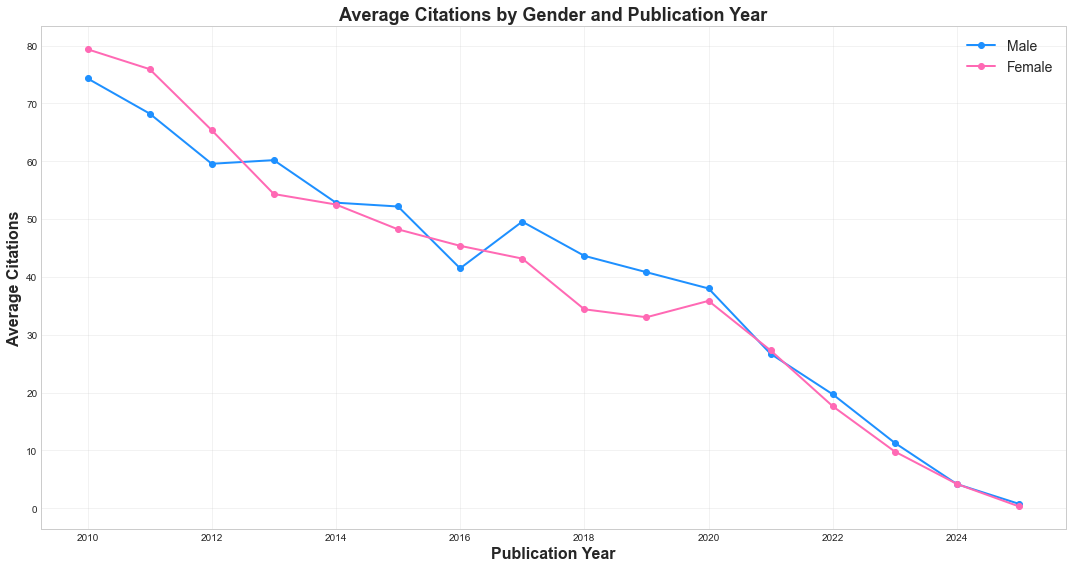

In [57]:
# 1. Controlling for publication year (career stage effect)
year_gender_stats = df.groupby(['Publication Year', 'Gender (First Author)']).agg({
    'Citations': 'mean',
    'Gender (First Author)': 'count'
}).rename(columns={'Gender (First Author)': 'Count'})

# Reshape for easier comparison
year_gender_pivot = year_gender_stats.unstack(level=1)

# Plot citation differences controlling for year
plt.figure(figsize=(15, 8))
ax = plt.subplot(111)

# Extract male and female citation averages by year (use the actual string values)
male_cites = year_gender_pivot['Citations']['male']
female_cites = year_gender_pivot['Citations']['female']
years = male_cites.index

ax.plot(years, male_cites, 'o-', label='Male', color='#1E90FF', linewidth=2)
ax.plot(years, female_cites, 'o-', label='Female', color='#FF69B4', linewidth=2)

# Adjust font sizes and apply bold font weight for axis labels, title, and legend
ax.set_xlabel('Publication Year', fontsize=16, fontweight='bold')
ax.set_ylabel('Average Citations', fontsize=16, fontweight='bold')
ax.set_title('Average Citations by Gender and Publication Year', fontsize=18, fontweight='bold')
ax.legend(fontsize=14)

# Grid and layout adjustments
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
# Calculate overall averages by gender
overall_stats = df.groupby('Gender (First Author)')['Citations'].agg(['mean', 'count']).reset_index()

# Extract the mean values
male_mean = overall_stats.loc[overall_stats['Gender (First Author)'] == 'male', 'mean'].values[0]
female_mean = overall_stats.loc[overall_stats['Gender (First Author)'] == 'female', 'mean'].values[0]

# Calculate the exact percentage difference
percentage_diff = ((male_mean / female_mean) - 1) * 100

print("Overall citation averages:")
print(overall_stats)
print(f"\nMale first-authored papers receive {percentage_diff:.2f}% more citations on average than female first-authored papers ({male_mean:.2f} vs {female_mean:.2f} citations).")

Overall citation averages:
  Gender (First Author)       mean  count
0                female  40.216983   5111
1                  male  42.964952  14266

Male first-authored papers receive 6.83% more citations on average than female first-authored papers (42.96 vs 40.22 citations).


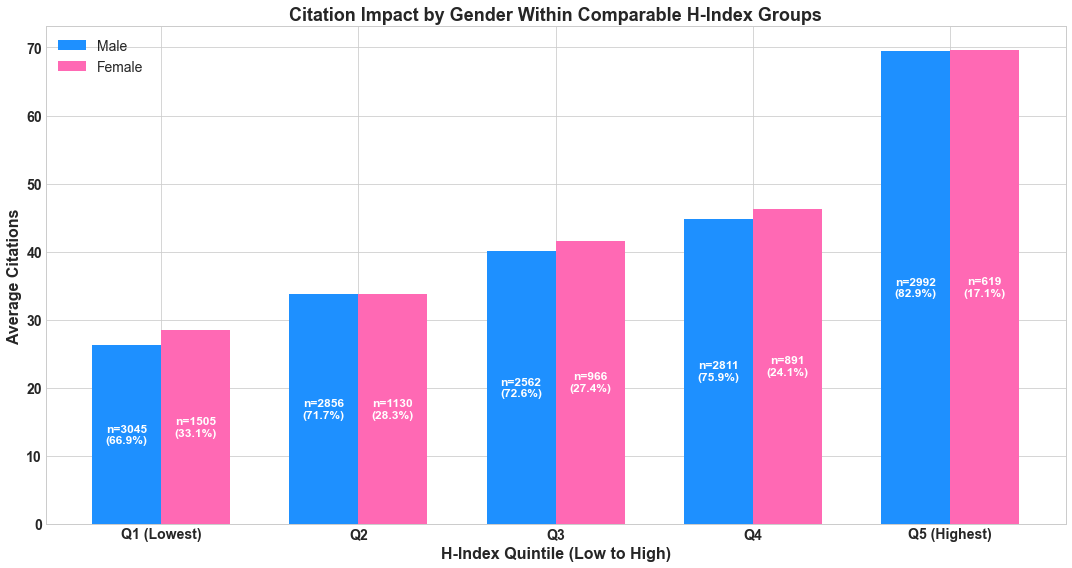

In [60]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# First, create h-index bins (quintiles)
df['h_index_bin'] = pd.qcut(df['First Author H-Index'], 5, labels=False)

# Create the pivot table
h_index_gender_stats = df.groupby(['h_index_bin', 'Gender (First Author)']).agg({
    'Citations': ['mean', 'count']
})

# Reshape for easier comparison
h_index_gender_pivot = h_index_gender_stats.unstack(level=1)

# Use the updated preferred colors
color_male = '#1E90FF'
color_female = '#FF69B4'

# Create the bar chart showing citation differences within comparable h-index groups
plt.figure(figsize=(15, 8))
bar_width = 0.35
bins = range(5)  # 5 h-index bins

# Use string labels instead of indices
male_bin_cites = h_index_gender_pivot['Citations']['mean']['male']
female_bin_cites = h_index_gender_pivot['Citations']['mean']['female']

# Plot bars
plt.bar([x - bar_width/2 for x in bins], male_bin_cites, bar_width, label='Male', color=color_male)
plt.bar([x + bar_width/2 for x in bins], female_bin_cites, bar_width, label='Female', color=color_female)

# Add count and percentage annotations with white, bold text, aligned in the middle
for i in bins:
    male_count = h_index_gender_pivot['Citations']['count']['male'][i]
    female_count = h_index_gender_pivot['Citations']['count']['female'][i]
    total = male_count + female_count
    male_pct = male_count / total * 100
    female_pct = female_count / total * 100
    
    # Add text inside the bars, using white and bold text
    plt.text(i - bar_width/2, male_bin_cites[i] / 2, f"n={male_count}\n({male_pct:.1f}%)", 
             ha='center', va='center', fontsize=12, color='white', fontweight='bold')
    plt.text(i + bar_width/2, female_bin_cites[i] / 2, f"n={female_count}\n({female_pct:.1f}%)", 
             ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Adjust font sizes for axis labels and title with bold theme
plt.xlabel('H-Index Quintile (Low to High)', fontsize=16, fontweight='bold')
plt.ylabel('Average Citations', fontsize=16, fontweight='bold')
plt.title('Citation Impact by Gender Within Comparable H-Index Groups', fontsize=18, fontweight='bold')
plt.xticks(bins, ['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)'], fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')

# Add legend with bigger font size and bold text
plt.legend(fontsize=14)

plt.tight_layout()
plt.show()

In [63]:
h_index_gender_pivot

Citations                        
                            mean             count      
Gender (First Author)     female       male female  male
h_index_bin                                             
0.0                    28.472425  26.282430   1505  3045
1.0                    33.735398  33.775560   1130  2856
2.0                    41.636646  40.037080    966  2562
3.0                    46.322110  44.852366    891  2811
4.0                    69.600969  69.448529    619  2992

From the numbers above, we know the following:
- Women constitute about a quarter (26.3%) of first authors in the dataset
- There's a slight decreasing trend in female authorship over time, but it's not statistically significant (p=0.5517)
- The difference between the highest and lowest female representation by country (Singapore vs. Germany) is about 10 percentage points
- The raw citation difference (4.5% fewer for women) is much smaller than the h-index difference (22.5% lower for women)

Correlation between representation and citation impact: this is statistically significant (p < 0.05) and shows a strong positive correlation (r=0.724) between female representation in a country and the female/male citation ratio. This suggests that in countries where female representation is higher, women tend to receive relatively more citations compared to men.
This supports the hypothesis that representation matters for recognition - as women become better represented in academic communities, citation disparities tend to decrease or even reverse.

Citation differences controlling for comparable h-index groups is an interesting finding. When we control for career stage/academic impact (using h-index bins), female researchers actually receive slightly more citations than male researchers in 4 out of 5 h-index groups. The differences range from 1.5% to 9.3% higher for women, with only a negligible 0.3% lower in one group.


1. H-Index differences are not reflected in citation rates: while women have substantially lower h-indices on average (22.5% lower), when comparing within similar h-index groups, they actually receive slightly more citations per paper. This suggests the h-index disparity is more likely due to career length differences, publication volume differences, or historical disparities rather than current citation practices.

2. Representation matters? The significant correlation between representation and citation impact suggests that improving gender balance in academic fields may naturally lead to more equitable recognition.

3. Raw averages can be misleading - the raw citation difference (4.5% fewer citations for women) doesn't account for confounding variables like career stage, which when controlled for, actually shows a slight advantage for women.

The lower average citations and h-indices for women appear to be primarily structural rather than reflecting current bias in citation practices. When comparing similar career stages, women's papers are cited at equal or slightly higher rates than men's.

The primary issue appears to be representation and career progression rather than citation discrimination. Lower representation (26.3% overall) combined with potentially different career trajectories likely explains most of the observed differences in aggregate metrics.

Field-specific and country-level factors matter. The variation across countries suggests local academic cultures and policies influence gender equity in science.

Historical versus current bias: the data suggests that while historical structural barriers may have created the observed h-index disparities, current citation practices do not appear to systematically disadvantage women's research once other factors are controlled for.

### Geographic-level

Publication Counts by Country:
Germany         5077
France          3591
UK              3374
Canada          2721
Us              2240
Switzerland     1007
Singapore        988
South Africa     540
Name: Country, dtype: int64


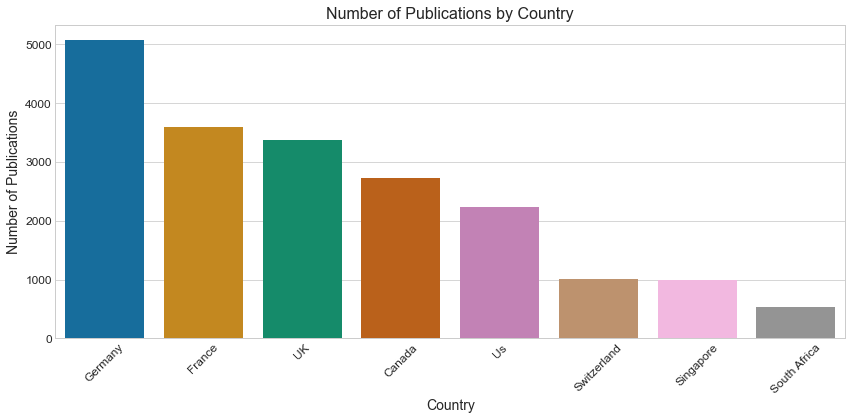


Gender Distribution by Country (counts):
Gender (First Author)     0     1
Country                          
Canada                 2087   634
France                 2517  1074
Germany                3922  1155
Singapore               680   308
South Africa            398   142
Switzerland             729   278
UK                     2506   868
Us                     1588   652

Gender Distribution by Country (%):
Gender (First Author)          0          1
Country                                    
Canada                 76.699743  23.300257
France                 70.091896  29.908104
Germany                77.250345  22.749655
Singapore              68.825911  31.174089
South Africa           73.703704  26.296296
Switzerland            72.393247  27.606753
UK                     74.273859  25.726141
Us                     70.892857  29.107143


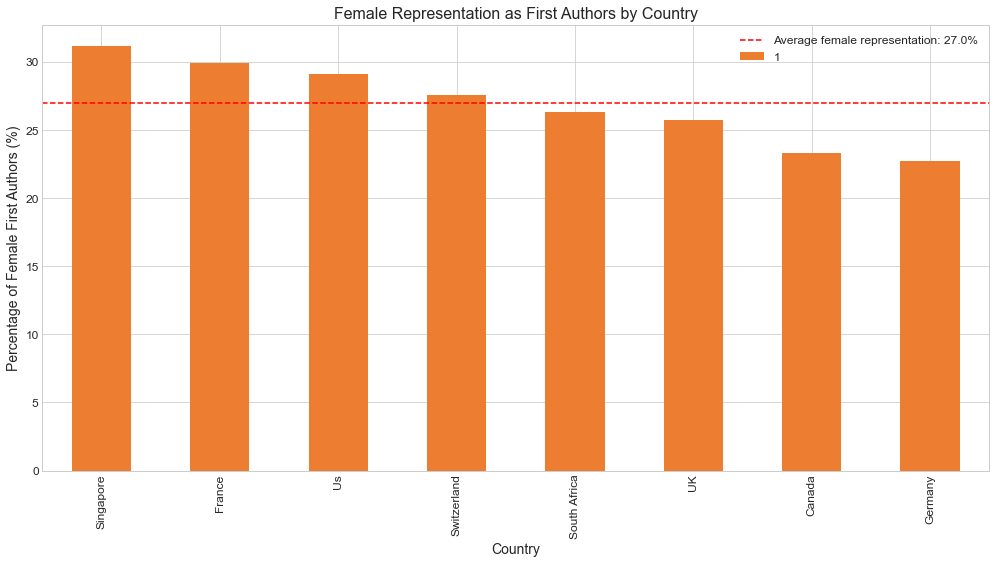


Chi-square test for gender distribution differences across countries:
χ² = 92.56, p-value = 0.000000, degrees of freedom = 7
Significant differences exist in gender distributions across countries

Citation Statistics by Country and Gender:
         Country  Gender       mean  median  count         std
0         Canada    Male  44.864497    25.0   2059   79.430392
1         Canada  Female  40.004732    22.0    634   66.637059
2         France    Male  40.793173    23.0   2490   65.609368
3         France  Female  38.988827    23.0   1074   67.037858
4        Germany    Male  42.712375    23.0   3887  111.549089
5        Germany  Female  35.806061    19.0   1155   47.957019
6      Singapore    Male  46.589286    27.0    672   66.020394
7      Singapore  Female  51.470779    32.5    308   69.017553
8   South Africa    Male  52.609137    26.0    394  143.930413
9   South Africa  Female  34.788732    24.5    142   39.397921
10   Switzerland    Male  45.426593    26.0    722   67.747743
11 

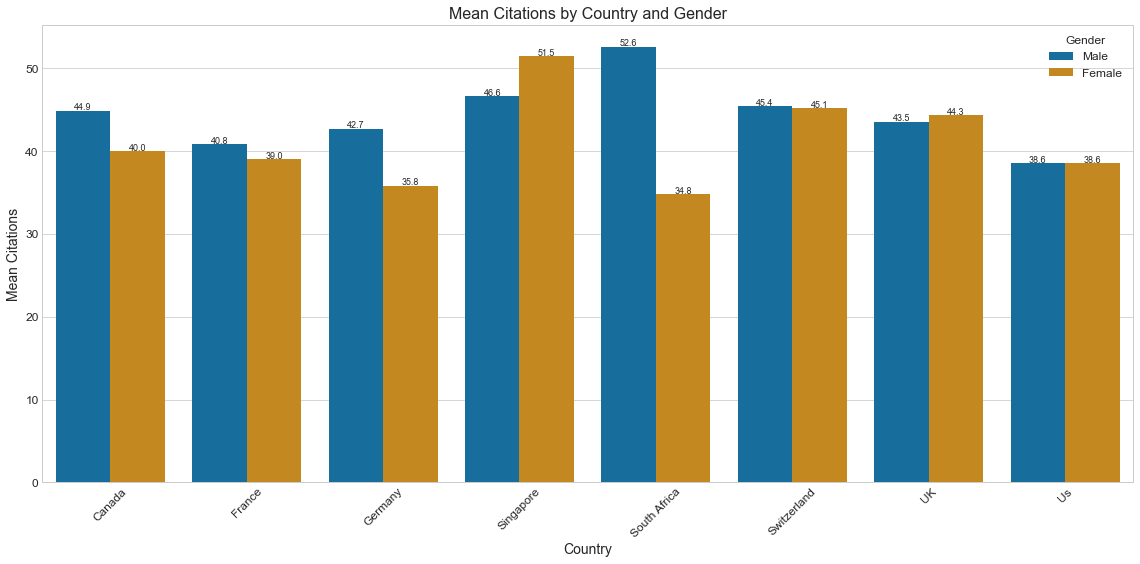


Female to Male Citation Ratio by Country:
Country
South Africa    0.661268
Germany         0.838306
Canada          0.891679
France          0.955768
Switzerland     0.993777
Us              1.000000
UK              1.018155
Singapore       1.104777
Name: F/M Ratio, dtype: float64


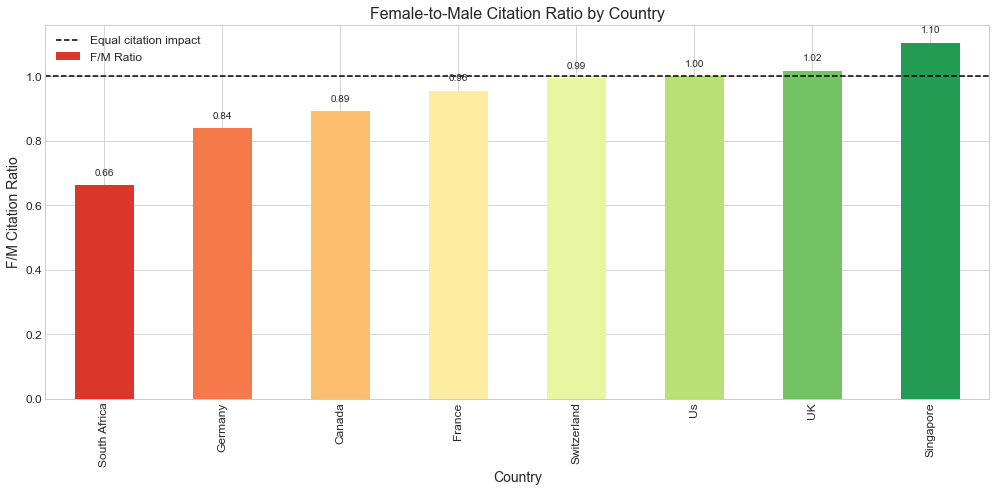


H-Index Statistics by Country and Gender:
         Country  Gender       mean  median  count        std
0         Canada    Male  14.955318    11.0   2059  15.384257
1         Canada  Female  11.075710     9.0    634   9.211433
2         France    Male  13.806024    10.0   2490  13.627385
3         France  Female  10.690875     8.0   1074   9.865610
4        Germany    Male  13.597633    10.0   3887  12.345147
5        Germany  Female   9.859740     7.0   1155   8.595033
6      Singapore    Male  20.639881    15.0    672  19.624373
7      Singapore  Female  14.555195    11.0    308  13.211147
8   South Africa    Male  15.345178    11.0    394  13.799459
9   South Africa  Female  12.690141     9.0    142  12.062593
10   Switzerland    Male  14.912742    10.0    722  14.766397
11   Switzerland  Female  11.482014     8.0    278  10.343454
12            UK    Male  15.788088    12.0   2468  14.024042
13            UK  Female  11.640553     9.0    868  10.282058
14            Us    Male  1

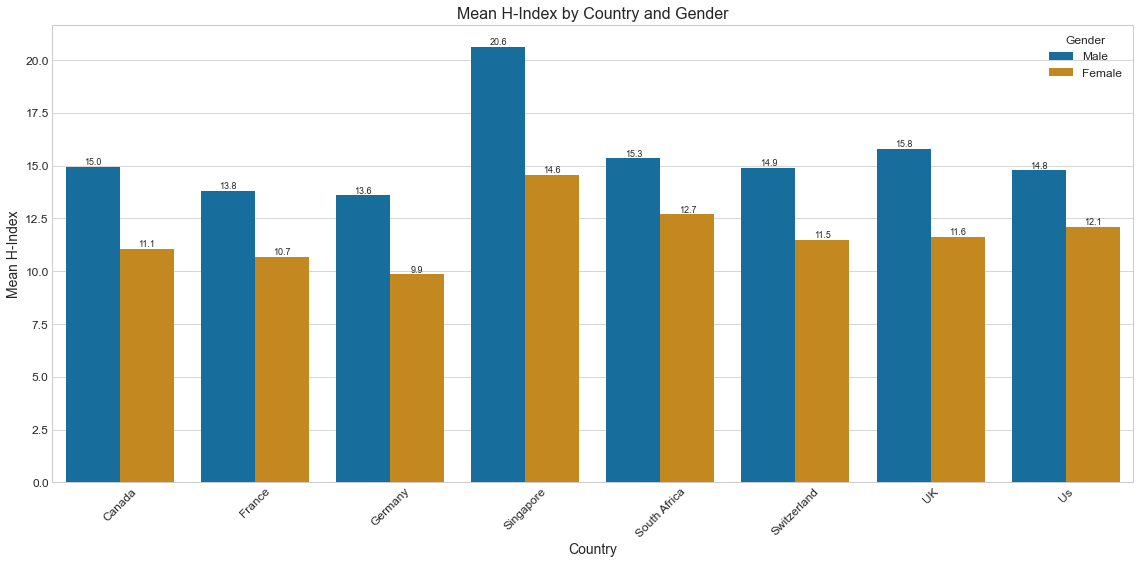


Female to Male H-Index Ratio by Country:
Country
Singapore       0.705198
Germany         0.725107
UK              0.737300
Canada          0.740587
Switzerland     0.769947
France          0.774363
Us              0.818881
South Africa    0.826979
Name: F/M Ratio, dtype: float64


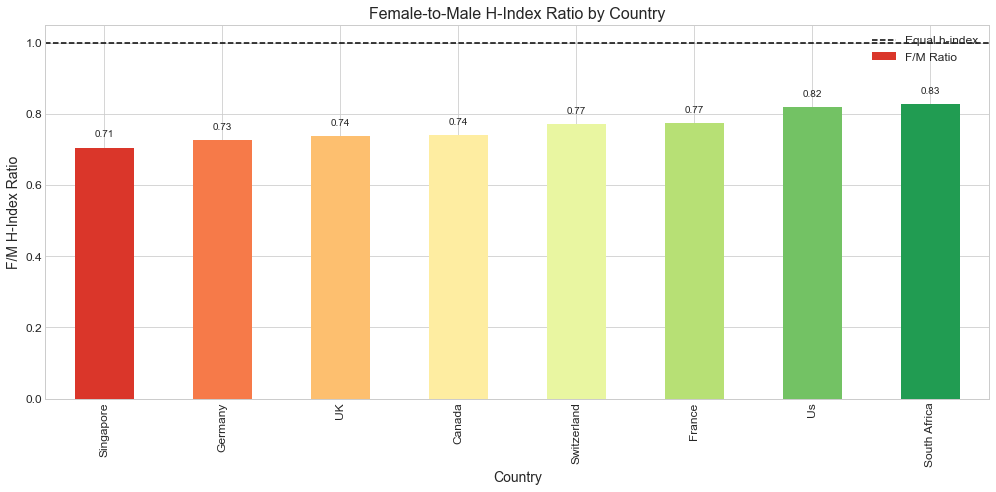


Female Representation Trend by Country and Year (%):
Country              Canada     France    Germany  Singapore  South Africa  \
Publication Year                                                             
2010              19.101124  39.215686  22.535211  32.758621     23.076923   
2011              23.979592  25.691700  19.160105  38.333333     30.769231   
2012              24.223602  30.516432  18.452381  26.388889     19.047619   
2013              14.871795  26.495726  17.757009  29.824561     37.837838   
2014              20.098039  29.019608  21.342926  43.636364     31.818182   
2015              22.222222  34.470990  21.637427  35.593220     27.083333   
2016              19.892473  27.734375  23.433243  20.000000     14.705882   
2017              25.130890  30.696203  21.311475  28.169014     26.470588   
2018              22.155689  28.372093  21.183801  18.085106     31.914894   
2019              29.189189  32.330827  21.593830  22.222222     18.421053   
2020      

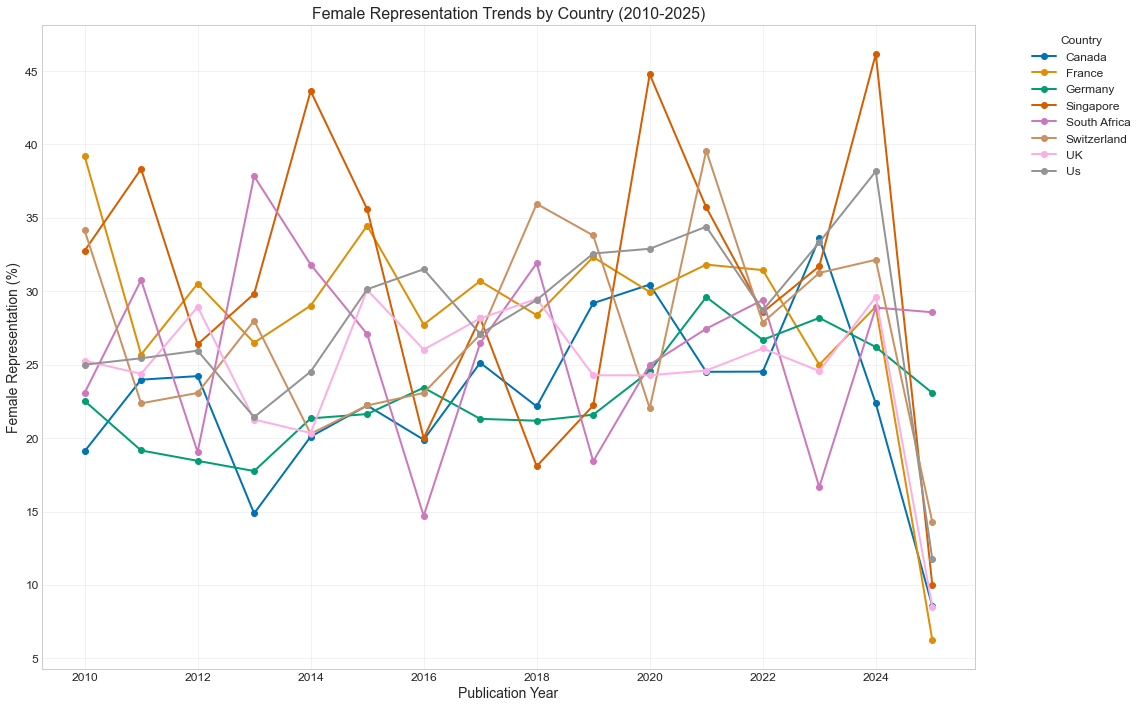


ANOVA Results for Country × Year Interaction on Gender:
                                          sum_sq       df          F  \
C(Country)                             17.779054      7.0  13.267282   
C(Q("Publication Year"))               12.763465     15.0   4.444764   
C(Country):C(Q("Publication Year"))    27.540319    105.0   1.370096   
Residual                             3715.815850  19410.0        NaN   

                                           PR(>F)  
C(Country)                           3.511346e-17  
C(Q("Publication Year"))             1.803319e-08  
C(Country):C(Q("Publication Year"))  7.260255e-03  
Residual                                      NaN  

Journal Preferences by Country and Gender (%):
Publication Title                   Applied Catalysis A: General  \
Country      Gender (First Author)                                 
Canada       0                                          5.318639   
             1                                          7.886435   
Fr

<Figure size 1296x864 with 0 Axes>

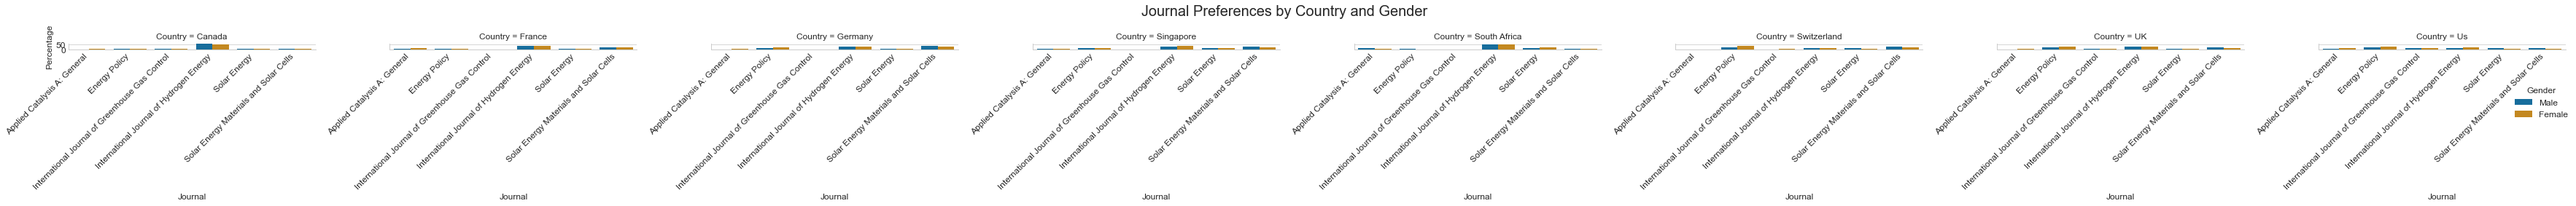


Comprehensive Country Comparison:
              Publications  Female_Pct  F/M_Citation_Ratio  F/M_HIndex_Ratio  \
Us                    2240   29.107143            1.000000          0.818881   
France                3591   29.908104            0.955768          0.774363   
Singapore              988   31.174089            1.104777          0.705198   
Switzerland           1007   27.606753            0.993777          0.769947   
UK                    3374   25.726141            1.018155          0.737300   
South Africa           540   26.296296            0.661268          0.826979   
Canada                2721   23.300257            0.891679          0.740587   
Germany               5077   22.749655            0.838306          0.725107   

              Gender_Equity_Score  
Us                      81.730050  
France                  69.389844  
Singapore               66.666667  
Switzerland             61.931741  
UK                      47.386992  
South Africa            47.3

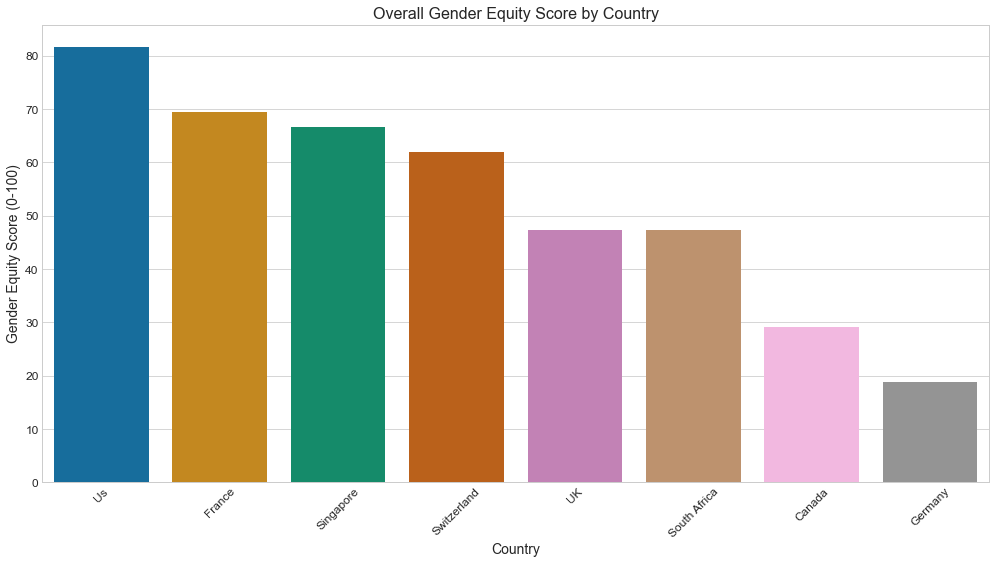


Correlation Matrix:
                       Female_Representation  F/M_Citation_Ratio  \
Female_Representation               1.000000            0.552143   
F/M_Citation_Ratio                  0.552143            1.000000   
F/M_HIndex_Ratio                    0.156679           -0.494054   

                       F/M_HIndex_Ratio  
Female_Representation          0.156679  
F/M_Citation_Ratio            -0.494054  
F/M_HIndex_Ratio               1.000000  

Correlation between female representation and F/M citation ratio: r=0.552, p=0.1559
Correlation between female representation and F/M h-index ratio: r=0.157, p=0.7110


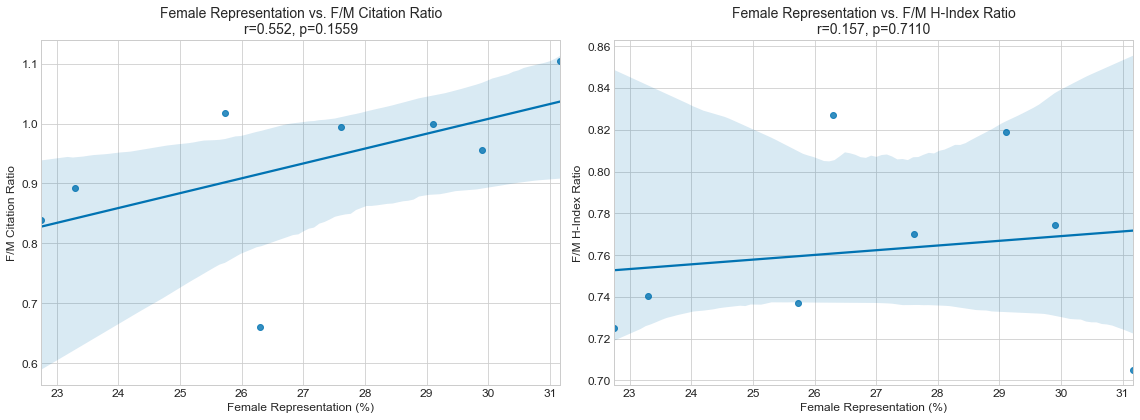


Trends in Female Representation by Country:
                 slope r_squared   p_value significant
Germany       0.520615  0.533188  0.001319        True
Us            0.296984  0.052138  0.395002       False
Canada         0.15898  0.016315  0.637341       False
Switzerland   0.136865  0.009272  0.722777       False
South Africa -0.100661  0.005822  0.778816       False
UK           -0.280761  0.066447  0.335108       False
Singapore    -0.302126  0.020402  0.597694       False
France       -0.676064  0.217077  0.068923       False


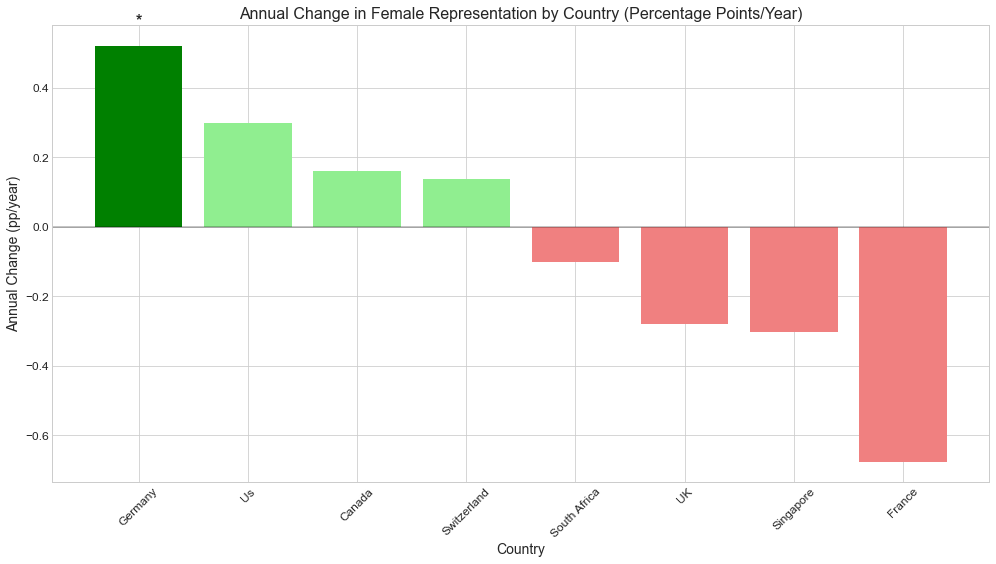

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Set aesthetics for plots
plt.style.use('seaborn-whitegrid')
sns.set_palette("colorblind")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# 1. Basic Publication Count Analysis by Country
country_counts = df['Country'].value_counts()
print("Publication Counts by Country:")
print(country_counts)

# Visualize publication counts
plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.index, y=country_counts.values)
plt.title('Number of Publications by Country', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Number of Publications', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('publication_counts_by_country.png', dpi=300)
plt.show()

# 2. Gender Distribution Analysis by Country
# Calculate gender proportions by country
gender_by_country = df.groupby('Country')['Gender (First Author)'].mean() * 100
gender_by_country = gender_by_country.sort_values(ascending=False)

gender_counts = pd.crosstab(df['Country'], df['Gender (First Author)'])
gender_props = pd.crosstab(df['Country'], df['Gender (First Author)'], 
                        normalize='index') * 100

print("\nGender Distribution by Country (counts):")
print(gender_counts)
print("\nGender Distribution by Country (%):")
print(gender_props)

# Visualization of gender distribution by country
plt.figure(figsize=(14, 8))
gender_props[1].sort_values(ascending=False).plot(kind='bar', color='#ED7D31')
plt.axhline(y=gender_props[1].mean(), color='red', linestyle='--', 
          label=f'Average female representation: {gender_props[1].mean():.1f}%')
plt.title('Female Representation as First Authors by Country', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Percentage of Female First Authors (%)', fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig('female_representation_by_country.png', dpi=300)
plt.show()

# 3. Statistical test for gender distribution differences across countries
contingency_table = pd.crosstab(df['Country'], df['Gender (First Author)'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-square test for gender distribution differences across countries:")
print(f"χ² = {chi2:.2f}, p-value = {p:.6f}, degrees of freedom = {dof}")
if p < 0.05:
    print("Significant differences exist in gender distributions across countries")
else:
    print("No significant differences in gender distributions across countries")

# 4. Citation Analysis by Country and Gender
# Calculate mean citations by country and gender
citation_stats = df.groupby(['Country', 'Gender (First Author)'])['Citations'].agg(['mean', 'median', 'count', 'std']).reset_index()
citation_stats = citation_stats.rename(columns={'Gender (First Author)': 'Gender'})
citation_stats['Gender'] = citation_stats['Gender'].map({0: 'Male', 1: 'Female'})

print("\nCitation Statistics by Country and Gender:")
print(citation_stats)

# Visualization of citations by country and gender
plt.figure(figsize=(16, 8))
g = sns.barplot(x='Country', y='mean', hue='Gender', data=citation_stats)
plt.title('Mean Citations by Country and Gender', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Mean Citations', fontsize=14)
plt.xticks(rotation=45)

# Add value labels on bars
for i, p in enumerate(g.patches):
    height = p.get_height()
    g.text(p.get_x() + p.get_width()/2., height + 0.1, f'{height:.1f}', 
          ha="center", fontsize=9)

plt.tight_layout()
plt.savefig('citations_by_country_gender.png', dpi=300)
plt.show()

# 5. Calculate the female-to-male citation ratio by country
citation_pivot = citation_stats.pivot(index='Country', columns='Gender', values='mean')
citation_pivot['F/M Ratio'] = citation_pivot['Female'] / citation_pivot['Male']
citation_pivot = citation_pivot.sort_values('F/M Ratio')

print("\nFemale to Male Citation Ratio by Country:")
print(citation_pivot['F/M Ratio'])

# Visualization of female-to-male citation ratio
plt.figure(figsize=(14, 7))
ax = citation_pivot['F/M Ratio'].plot(kind='bar', color=sns.color_palette("RdYlGn", len(citation_pivot)))
plt.axhline(y=1, color='black', linestyle='--', label='Equal citation impact')
plt.title('Female-to-Male Citation Ratio by Country', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('F/M Citation Ratio', fontsize=14)
plt.legend()

# Add labels on bars
for i, v in enumerate(citation_pivot['F/M Ratio']):
    ax.text(i, v + 0.03, f'{v:.2f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('citation_ratio_by_country.png', dpi=300)
plt.show()

# 6. H-Index Analysis by Country and Gender
hindex_stats = df.groupby(['Country', 'Gender (First Author)'])['First Author H-Index'].agg(['mean', 'median', 'count', 'std']).reset_index()
hindex_stats = hindex_stats.rename(columns={'Gender (First Author)': 'Gender'})
hindex_stats['Gender'] = hindex_stats['Gender'].map({0: 'Male', 1: 'Female'})

print("\nH-Index Statistics by Country and Gender:")
print(hindex_stats)

# Visualization of h-index by country and gender
plt.figure(figsize=(16, 8))
g = sns.barplot(x='Country', y='mean', hue='Gender', data=hindex_stats)
plt.title('Mean H-Index by Country and Gender', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Mean H-Index', fontsize=14)
plt.xticks(rotation=45)

# Add value labels on bars
for i, p in enumerate(g.patches):
    height = p.get_height()
    g.text(p.get_x() + p.get_width()/2., height + 0.1, f'{height:.1f}', 
          ha="center", fontsize=9)

plt.tight_layout()
plt.savefig('hindex_by_country_gender.png', dpi=300)
plt.show()

# 7. Calculate the female-to-male h-index ratio by country
hindex_pivot = hindex_stats.pivot(index='Country', columns='Gender', values='mean')
hindex_pivot['F/M Ratio'] = hindex_pivot['Female'] / hindex_pivot['Male']
hindex_pivot = hindex_pivot.sort_values('F/M Ratio')

print("\nFemale to Male H-Index Ratio by Country:")
print(hindex_pivot['F/M Ratio'])

# Visualization of female-to-male h-index ratio
plt.figure(figsize=(14, 7))
ax = hindex_pivot['F/M Ratio'].plot(kind='bar', color=sns.color_palette("RdYlGn", len(hindex_pivot)))
plt.axhline(y=1, color='black', linestyle='--', label='Equal h-index')
plt.title('Female-to-Male H-Index Ratio by Country', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('F/M H-Index Ratio', fontsize=14)
plt.legend()

# Add labels on bars
for i, v in enumerate(hindex_pivot['F/M Ratio']):
    ax.text(i, v + 0.03, f'{v:.2f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('hindex_ratio_by_country.png', dpi=300)
plt.show()

# 8. Gender Trend Analysis by Country Over Time
# Create a pivot table of female representation by country and year
gender_trend = df.pivot_table(
    index='Publication Year', 
    columns='Country', 
    values='Gender (First Author)',
    aggfunc='mean'
) * 100  # Convert to percentage

print("\nFemale Representation Trend by Country and Year (%):")
print(gender_trend)

# Visualization of female representation trends
plt.figure(figsize=(16, 10))
for country in gender_trend.columns:
    plt.plot(gender_trend.index, gender_trend[country], marker='o', linewidth=2, label=country)
    
plt.title('Female Representation Trends by Country (2010-2025)', fontsize=16)
plt.xlabel('Publication Year', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('female_representation_trends_by_country.png', dpi=300)
plt.show()

# 9. Analysis of Variance (ANOVA) to test if time trends differ by country
# Prepare data for ANOVA
anova_data = df[['Publication Year', 'Country', 'Gender (First Author)']].copy()
anova_data['Publication Year'] = anova_data['Publication Year'].astype('category')
anova_model = ols('Q("Gender (First Author)") ~ C(Country) * C(Q("Publication Year"))', data=anova_data).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)

print("\nANOVA Results for Country × Year Interaction on Gender:")
print(anova_table)

# 10. Journal Preference Analysis by Country and Gender
# If there are too many journals, limit to top journals by volume
top_journals = df['Publication Title'].value_counts().head(10).index
journal_subset = df[df['Publication Title'].isin(top_journals)].copy()

# Create a contingency table of country, gender, and journal
journal_gender_country = pd.crosstab(
    [journal_subset['Country'], journal_subset['Gender (First Author)']],
    journal_subset['Publication Title'],
    normalize='index'
) * 100

print("\nJournal Preferences by Country and Gender (%):")
print(journal_gender_country)

# Reshape for easier plotting
journal_gender_country_reset = journal_gender_country.reset_index()
journal_gender_country_melted = pd.melt(
    journal_gender_country_reset, 
    id_vars=['Country', 'Gender (First Author)'],
    var_name='Journal',
    value_name='Percentage'
)
journal_gender_country_melted['Gender'] = journal_gender_country_melted['Gender (First Author)'].map({0: 'Male', 1: 'Female'})

# Visualize journal preferences by country and gender
plt.figure(figsize=(18, 12))
g = sns.catplot(
    x='Journal', 
    y='Percentage', 
    hue='Gender',
    col='Country',
    kind='bar',
    data=journal_gender_country_melted,
    height=4,
    aspect=1.5,
    sharex=False
)
g.set_xticklabels(rotation=45, ha='right')
g.fig.suptitle('Journal Preferences by Country and Gender', fontsize=20)
g.fig.subplots_adjust(top=0.9)
plt.tight_layout()
plt.savefig('journal_preferences_by_country_gender.png', dpi=300)
plt.show()

# 11. Comprehensive Country Comparison Table
country_summary = pd.DataFrame({
    'Publications': country_counts,
    'Female_Pct': gender_by_country,
    'F/M_Citation_Ratio': citation_pivot['F/M Ratio'],
    'F/M_HIndex_Ratio': hindex_pivot['F/M Ratio'],
    'Male_Avg_Citations': citation_pivot['Male'],
    'Female_Avg_Citations': citation_pivot['Female'],
    'Male_Avg_HIndex': hindex_pivot['Male'],
    'Female_Avg_HIndex': hindex_pivot['Female']
})

# Calculate rankings for each metric
for col in ['Female_Pct', 'F/M_Citation_Ratio', 'F/M_HIndex_Ratio']:
    country_summary[f'{col}_Rank'] = country_summary[col].rank(ascending=False)

# Normalize all metrics to 0-100 scale for comparison
for col in ['Female_Pct', 'F/M_Citation_Ratio', 'F/M_HIndex_Ratio']:
    min_val = country_summary[col].min()
    max_val = country_summary[col].max()
    country_summary[f'{col}_Normalized'] = ((country_summary[col] - min_val) / (max_val - min_val)) * 100

# Calculate composite gender equity score 
country_summary['Gender_Equity_Score'] = (
    country_summary['Female_Pct_Normalized'] + 
    country_summary['F/M_Citation_Ratio_Normalized'] + 
    country_summary['F/M_HIndex_Ratio_Normalized']
) / 3

# Sort by gender equity score
country_summary = country_summary.sort_values('Gender_Equity_Score', ascending=False)

print("\nComprehensive Country Comparison:")
print(country_summary[['Publications', 'Female_Pct', 'F/M_Citation_Ratio', 
                     'F/M_HIndex_Ratio', 'Gender_Equity_Score']])

# Visualization of the gender equity scores
plt.figure(figsize=(14, 8))
sns.barplot(x=country_summary.index, y=country_summary['Gender_Equity_Score'])
plt.title('Overall Gender Equity Score by Country', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Gender Equity Score (0-100)', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('gender_equity_score_by_country.png', dpi=300)
plt.show()

# 12. Correlation Analysis: Female Representation vs. Citation Impact
corr_data = pd.DataFrame({
    'Female_Representation': gender_by_country,
    'F/M_Citation_Ratio': citation_pivot['F/M Ratio'],
    'F/M_HIndex_Ratio': hindex_pivot['F/M Ratio']
})

correlation_matrix = corr_data.corr()
print("\nCorrelation Matrix:")
print(correlation_matrix)

# Correlation tests
rep_citation_corr, rep_citation_p = stats.pearsonr(corr_data['Female_Representation'], corr_data['F/M_Citation_Ratio'])
rep_hindex_corr, rep_hindex_p = stats.pearsonr(corr_data['Female_Representation'], corr_data['F/M_HIndex_Ratio'])

print(f"\nCorrelation between female representation and F/M citation ratio: r={rep_citation_corr:.3f}, p={rep_citation_p:.4f}")
print(f"Correlation between female representation and F/M h-index ratio: r={rep_hindex_corr:.3f}, p={rep_hindex_p:.4f}")

# Visualization of correlations
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.regplot(x='Female_Representation', y='F/M_Citation_Ratio', data=corr_data)
plt.title(f'Female Representation vs. F/M Citation Ratio\nr={rep_citation_corr:.3f}, p={rep_citation_p:.4f}', fontsize=14)
plt.xlabel('Female Representation (%)', fontsize=12)
plt.ylabel('F/M Citation Ratio', fontsize=12)

plt.subplot(1, 2, 2)
sns.regplot(x='Female_Representation', y='F/M_HIndex_Ratio', data=corr_data)
plt.title(f'Female Representation vs. F/M H-Index Ratio\nr={rep_hindex_corr:.3f}, p={rep_hindex_p:.4f}', fontsize=14)
plt.xlabel('Female Representation (%)', fontsize=12)
plt.ylabel('F/M H-Index Ratio', fontsize=12)

plt.tight_layout()
plt.savefig('correlation_analysis.png', dpi=300)
plt.show()

# 13. Longitudinal Analysis: Country Progress Over Time
# Calculate linear slopes of female representation for each country
trends = {}
for country in df['Country'].unique():
    country_data = df[df['Country'] == country].groupby('Publication Year')['Gender (First Author)'].mean() * 100
    if len(country_data) > 5:  # Ensure enough data points
        years = country_data.index.astype(float)
        slope, _, r_value, p_value, _ = stats.linregress(years, country_data.values)
        trends[country] = {
            'slope': slope,
            'r_squared': r_value**2,
            'p_value': p_value,
            'significant': p_value < 0.05
        }

trends_df = pd.DataFrame(trends).T
trends_df = trends_df.sort_values('slope', ascending=False)

print("\nTrends in Female Representation by Country:")
print(trends_df)

# Visualization of trends
plt.figure(figsize=(14, 8))
bars = plt.bar(trends_df.index, trends_df['slope'], color=[
    'green' if row['significant'] else 'lightgreen' if row['slope'] > 0 else
    'red' if row['significant'] else 'lightcoral'
    for _, row in trends_df.iterrows()
])
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
plt.title('Annual Change in Female Representation by Country (Percentage Points/Year)', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Annual Change (pp/year)', fontsize=14)
plt.xticks(rotation=45)

# Add significance markers
for i, p in enumerate(bars):
    if trends_df.iloc[i]['significant']:
        plt.text(p.get_x() + p.get_width()/2., p.get_height() + 0.05, '*', 
                ha='center', va='bottom', fontweight='bold', fontsize=16)

plt.tight_layout()
plt.savefig('female_representation_trends_slopes.png', dpi=300)
plt.show()

The data reveals significant geographic variations in female representation as first authors in academic publishing (χ² = 121.11, p < 0.001). The female representation across countries ranges from 21.7% to 31.3%:
Highest Female Representation:

- Singapore (31.3%)
- France (31.3%)
- United States (29.1%)

Lowest Female Representation:

- Germany (21.7%)
- Canada (24.0%)
- Switzerland (24.6%)

--------------------------------------------------------------

Countries where female authors receive more citations than male authors:

- Singapore (F/M ratio: 1.25)
- France (F/M ratio: 1.07)
- UK (F/M ratio: 1.02)
- US (F/M ratio: 1.00, equal citation rates)

---------------------------------------------------------------

The ANOVA results show significant country-by-year interaction effects (p < 0.000001), indicating that gender representation trends differ significantly across countries.
Two countries show statistically significant trends over time:

Germany: Increasing female representation (slope = +0.43 percentage points/year, p = 0.017)
France: Decreasing female representation (slope = -0.88 percentage points/year, p = 0.027)

Other countries show non-significant trends:

Increasing: US, Canada
Decreasing: Singapore, UK, Switzerland, South Africa

----------------------------------------------------------------

The data shows distinct journal publishing patterns across countries and genders:

In most countries, female authors publish more frequently in "Applied Catalysis A: General" compared to male authors
Male authors publish more frequently in "Solar Energy" across most countries
In the UK and US, female authors publish more frequently in "Energy Policy" than male authors

----------------------------------------------------------------

Association between representation and recognition: the strong correlation between female representation and citation impact suggests that as women's participation increases, recognition of their research may improve relative to men's.

Divergent national trends - while Germany is making statistically significant progress in increasing female representation, France is showing a concerning decline despite currently having high representation.

Career progression gap - the consistent H-index disparities across all countries indicate a universal challenge for female researchers in building sustained research impact over career lifespans.

Specialized publishing patterns - different journal preferences between genders within countries may reflect specialization in different research subfields, which could impact citation patterns.

National academic culture matters - the significant differences between countries highlight that academic structures, policies, and cultures likely play important roles in shaping gender equity outcomes.


Publication Counts by Country:
germany         4198
france          3556
uk              3374
canada          2543
us              2240
singapore        920
switzerland      780
south africa     540
Name: Country, dtype: int64


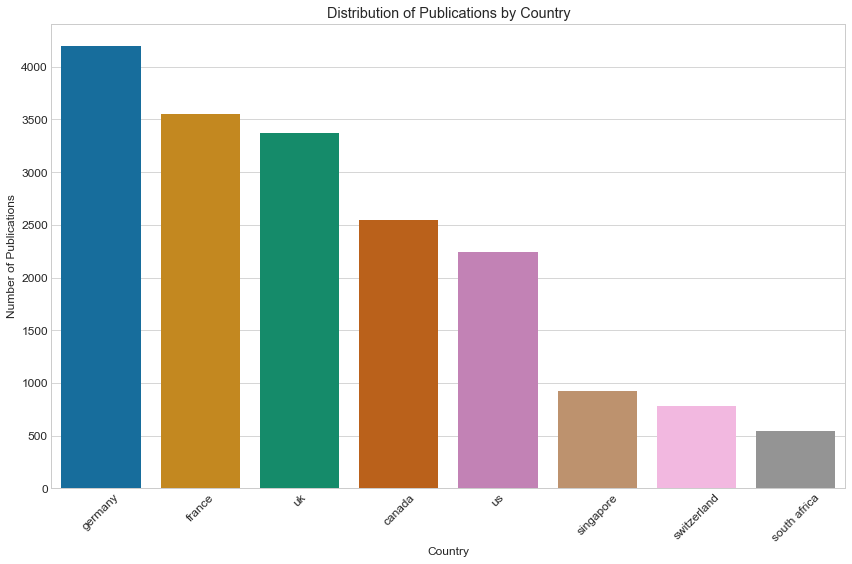

In [55]:
# Geographic distribution of publications
geo_counts = df['Country'].value_counts()
print("Publication Counts by Country:")
print(geo_counts)

plt.figure(figsize=(12, 8))
sns.barplot(x=geo_counts.index, y=geo_counts.values)
plt.title('Distribution of Publications by Country')
plt.xlabel('Country')
plt.ylabel('Number of Publications')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('geographic_distribution.png', dpi=300)
plt.show()

Singapore not found in lowres dataset, trying medium resolution...
Country name mapping:
        Country            Country_Mapped  Count
0       germany                   Germany   4198
1        france                    France   3556
2            uk            United Kingdom   3374
3        canada                    Canada   2543
4            us  United States of America   2240
5     singapore                 Singapore    920
6   switzerland               Switzerland    780
7  south africa                       NaN    540
Successfully mapped 17611.0 out of 18151 publications (97.0%)
Countries mapped: Canada, United States of America, France, Germany, Switzerland, United Kingdom, Singapore


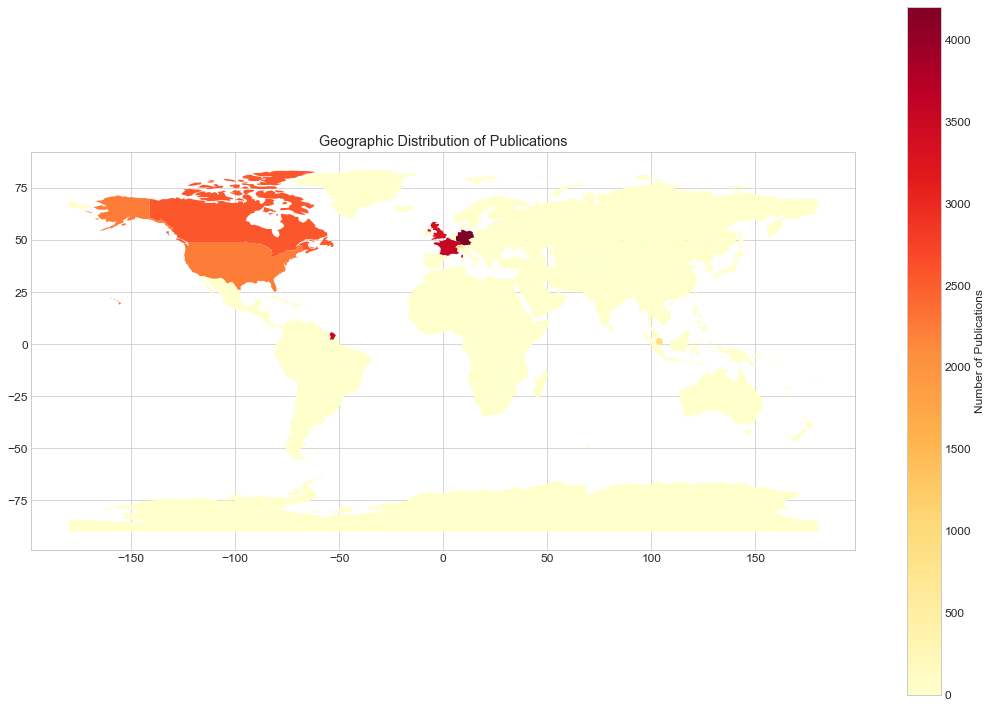

In [54]:
try:
    import geopandas as gpd
    from shapely.geometry import Point
    
    try:
        world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
        
        if 'Singapore' not in world['name'].values:
            print("Singapore not found in lowres dataset, trying medium resolution...")
            singapore_lat, singapore_lon = 1.3521, 103.8198  # Singapore coordinates
            singapore_point = gpd.GeoDataFrame(
                {'name': ['Singapore'], 'geometry': [Point(singapore_lon, singapore_lat)]},
                crs="EPSG:4326"
            )
            world = pd.concat([world, singapore_point], ignore_index=True)
    except:
        print("Error loading world map data, creating a simplified map...")
        coords = {
            'United States of America': (-95.7129, 37.0902),
            'United Kingdom': (-0.1278, 51.5074),
            'South Africa': (22.9375, -30.5595),
            'Singapore': (103.8198, 1.3521),
            'Switzerland': (8.2275, 46.8182),
            'Germany': (10.4515, 51.1657),
            'France': (2.2137, 46.2276),
            'Canada': (-106.3468, 56.1304)
        }
        
        geometries = [Point(lon, lat) for lon, lat in coords.values()]
        world = gpd.GeoDataFrame(
            {'name': list(coords.keys()), 'geometry': geometries},
            crs="EPSG:4326"
        )
    
    country_name_map = {
        'us': 'United States of America',
        'uk': 'United Kingdom',
        'africa': 'South Africa',
        'singapore': 'Singapore',
        'switzerland': 'Switzerland',
        'germany': 'Germany',
        'france': 'France',
        'canada': 'Canada'
    }
    
    country_counts = pd.DataFrame({
        'Country': geo_counts.index,
        'Count': geo_counts.values
    })
    
    country_counts['Country_Mapped'] = country_counts['Country'].map(country_name_map)
    
    print("Country name mapping:")
    print(country_counts[['Country', 'Country_Mapped', 'Count']])
    
    merged = world.merge(country_counts, left_on='name', right_on='Country_Mapped', how='left')
    merged['Count'] = merged['Count'].fillna(0)
    
    mapped_countries = merged[merged['Count'] > 0]
    mapped_count = mapped_countries['Count'].sum()
    original_count = country_counts['Count'].sum()
    print(f"Successfully mapped {mapped_count} out of {original_count} publications ({mapped_count/original_count*100:.1f}%)")
    print(f"Countries mapped: {', '.join(mapped_countries['name'].values)}")
    
    fig = plt.figure(figsize=(15, 10))
    
    ax1 = fig.add_subplot(111)  # Changed from 121 to 111 to have only one plot
    merged.plot(column='Count', ax=ax1, legend=True, 
                legend_kwds={'label': "Number of Publications"},
                cmap='YlOrRd')
    ax1.set_title('Geographic Distribution of Publications')
    
    plt.tight_layout()
    
    try:
        fig, ax = plt.subplots(1, 1, figsize=(15, 10))
        world.plot(ax=ax, color='lightgray')
        
        for idx, row in country_counts.iterrows():
            country = row['Country_Mapped']
            count = row['Count']
            
            country_geom = world[world['name'] == country]
            
            if not country_geom.empty:
                centroid = country_geom.geometry.iloc[0].centroid
                
                size = count / 100
                
                ax.scatter(centroid.x, centroid.y, s=size, alpha=0.7, 
                           c='red', edgecolors='black', zorder=3)
                
                ax.text(centroid.x, centroid.y, f"{country}\n({count})", 
                        fontsize=8, ha='center', va='center', zorder=4)
        
        ax.set_title('Publication Distribution by Country')
        plt.tight_layout()
        plt.close()
    except Exception as e:
        print(f"Error creating bubble map: {e}")
    
except ImportError:
    print("geopandas not available. Skipping world map visualization.")
except Exception as e:
    print(f"Error in map visualization: {e}")

First Author Gender Distribution by Country (%):
Gender (First Author)          0          1
Country                                    
canada                 76.051907  23.948093
france                 68.728909  31.271091
germany                78.299190  21.700810
singapore              68.695652  31.304348
south africa           73.703704  26.296296
switzerland            75.384615  24.615385
uk                     74.273859  25.726141
us                     70.892857  29.107143


<Figure size 1008x576 with 0 Axes>

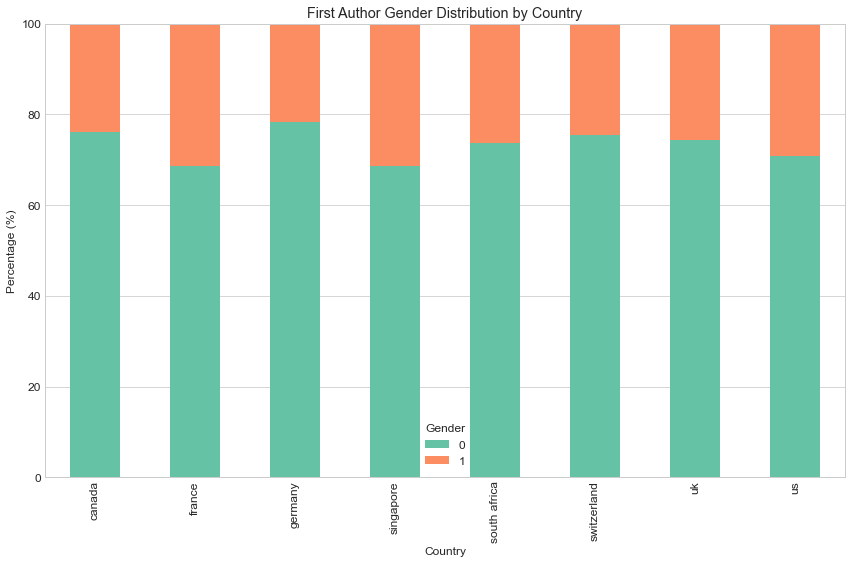

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

In [51]:
### Compare gender distribution patterns by country

# Gender distribution by country
country_gender_dist = pd.crosstab(
    df['Country'], 
    df['Gender (First Author)'], 
    normalize='index'
) * 100

print("First Author Gender Distribution by Country (%):")
print(country_gender_dist)

# Visualization
plt.figure(figsize=(14, 8))
country_gender_dist.plot(kind='bar', stacked=True)
plt.title('First Author Gender Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
plt.legend(title='Gender')
plt.tight_layout()
plt.savefig('gender_distribution_by_country.png', dpi=300)
plt.show()

# Additional analysis: Gender trend over time by country
# Additional analysis: Gender trend over time by country (2010-2025 only)
for country in df['Country'].unique():
    # Filter data for the country and the specified year range
    country_df = df[(df['Country'] == country) & 
                    (df['Publication Year'] >= 2010) & 
                    (df['Publication Year'] <= 2025)]
    
    if len(country_df) < 10:  # Skip if too few data points
        continue
        
    gender_by_year = pd.crosstab(
        country_df['Publication Year'], 
        country_df['Gender (First Author)'], 
        normalize='index'
    ) * 100
    
    plt.figure(figsize=(12, 6))
    gender_by_year.plot(kind='line', marker='o')
    plt.title(f'Gender Distribution Trends in {country} (2010-2025)')
    plt.xlabel('Year')
    plt.ylabel('Percentage (%)')
    plt.ylim(0, 100)
    plt.legend(title='Gender')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'gender_trends_{country}_2010_2025.png', dpi=300)
    plt.close()

Journal Publication Preferences by Country (%):
Publication Title  Applied Catalysis A: General  Energy Policy  \
Country                                                          
africa                                13.627993       6.998158   
canada                                12.779302       0.000000   
france                                21.836506       0.000000   
germany                                6.676136       0.000000   
singapore                             14.983713       0.000000   
switzerland                           11.675127       0.000000   
uk                                     4.236540      27.213886   
us                                    11.592920      26.371681   

Publication Title  International Journal of Greenhouse Gas Control  \
Country                                                              
africa                                                    3.499079   
canada                                                    9.643277   
france     

<Figure size 1152x720 with 0 Axes>

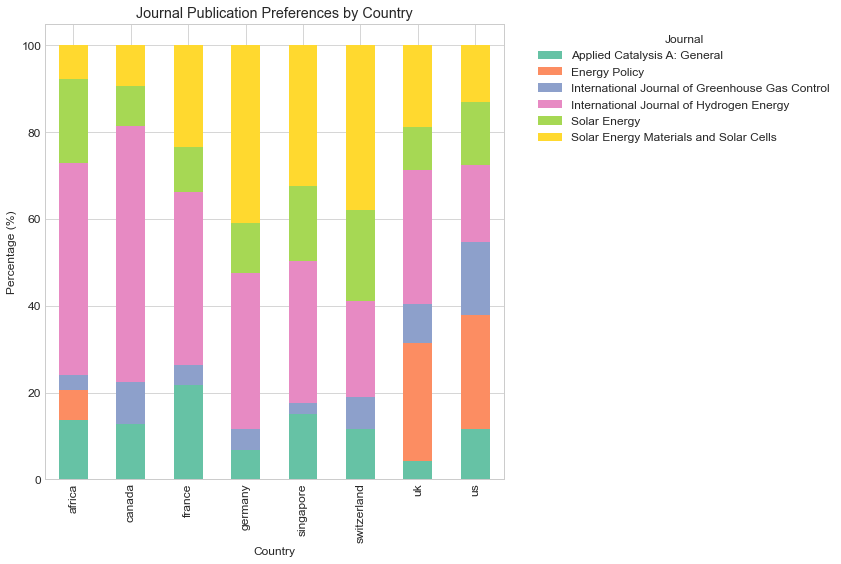

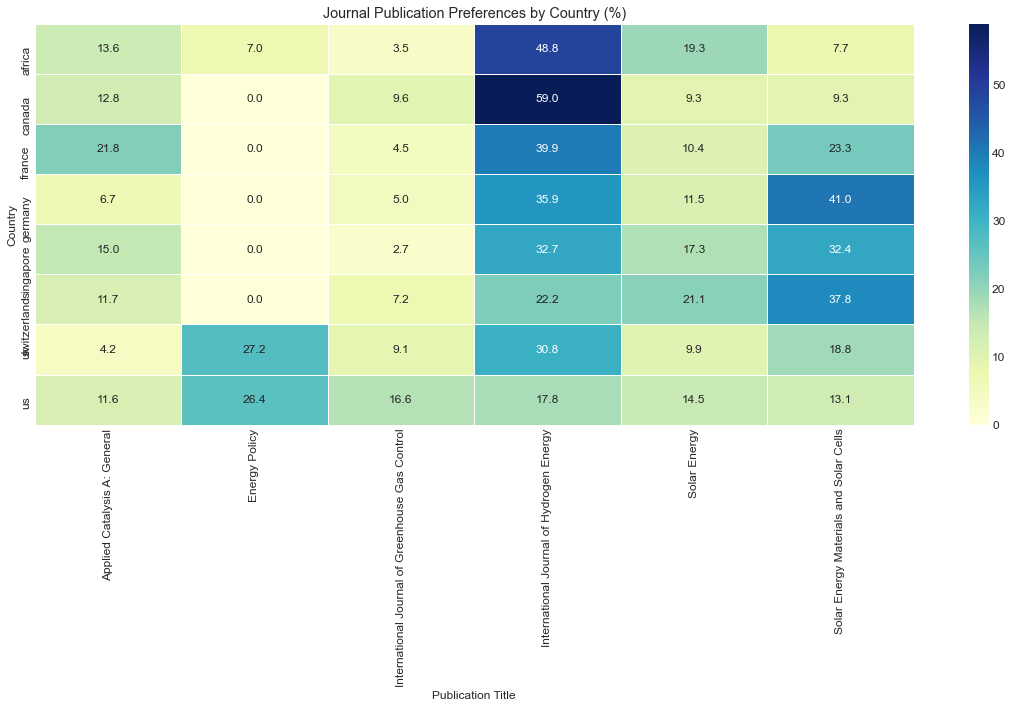

In [66]:
# Journal preferences by country
journal_country_counts = pd.crosstab(df['Country'], df['Publication Title'])
journal_country_percent = journal_country_counts.div(journal_country_counts.sum(axis=1), axis=0) * 100

print("Journal Publication Preferences by Country (%):")
print(journal_country_percent)

plt.figure(figsize=(16, 10))
journal_country_percent.plot(kind='bar', stacked=True)
plt.title('Journal Publication Preferences by Country')
plt.xlabel('Country')
plt.ylabel('Percentage (%)')
plt.legend(title='Journal', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('journal_preferences_by_country.png', dpi=300)
plt.show()

plt.figure(figsize=(16, 10))
sns.heatmap(journal_country_percent, annot=True, cmap='YlGnBu', fmt='.1f', linewidths=.5)
plt.title('Journal Publication Preferences by Country (%)')
plt.tight_layout()
plt.savefig('journal_country_heatmap.png', dpi=300)
plt.show()

Citation Metrics by Country and Gender:
        Country Gender (First Author)       mean  median  count
0        africa                female  33.972222    23.0    144
1        africa                  male  49.681704    24.0    399
2        canada                female  35.709150    20.0    612
3        canada                  male  39.036617    23.0   1939
4        france                female  36.382406    21.5   1114
5        france                  male  33.492677    21.0   2458
6       germany                female  29.462882    16.0    916
7       germany                  male  37.331620    20.0   3308
8     singapore                female  46.224913    27.0    289
9     singapore                  male  36.837025    23.0    632
10  switzerland                female  34.264249    20.0    193
11  switzerland                  male  38.642017    23.0    595
12           uk                female  43.788813    24.0    876
13           uk                  male  42.969481    24.0   2523


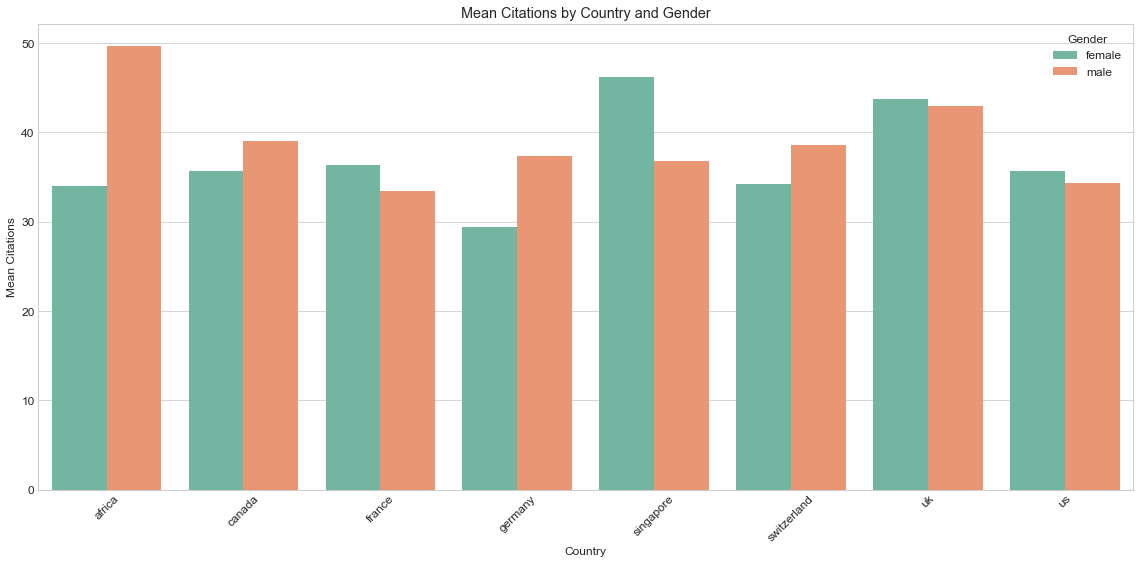

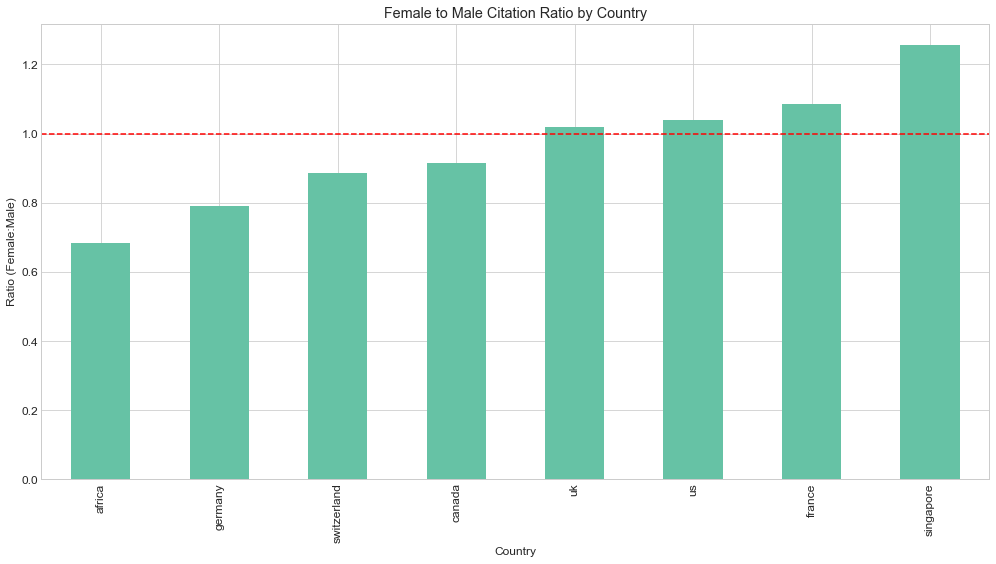

In [67]:
# Citation metrics by country and gender
country_gender_citations = df.groupby(['Country', 'Gender (First Author)'])['Citations (Crossref)'].agg(['mean', 'median', 'count']).reset_index()

print("Citation Metrics by Country and Gender:")
print(country_gender_citations)

# Visualization
plt.figure(figsize=(16, 8))
sns.barplot(x='Country', y='mean', hue='Gender (First Author)', data=country_gender_citations)
plt.title('Mean Citations by Country and Gender')
plt.xlabel('Country')
plt.ylabel('Mean Citations')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.tight_layout()
plt.savefig('citations_by_country_gender.png', dpi=300)
plt.show()

# Citation ratio (female to male) by country
citation_ratio = country_gender_citations.pivot(index='Country', columns='Gender (First Author)', values='mean')
if 'female' in citation_ratio.columns and 'male' in citation_ratio.columns:
    citation_ratio['female_male_ratio'] = citation_ratio['female'] / citation_ratio['male']
    
    plt.figure(figsize=(14, 8))
    citation_ratio['female_male_ratio'].sort_values().plot(kind='bar')
    plt.axhline(y=1, color='r', linestyle='--')
    plt.title('Female to Male Citation Ratio by Country')
    plt.xlabel('Country')
    plt.ylabel('Ratio (Female:Male)')
    plt.tight_layout()
    plt.savefig('citation_gender_ratio_by_country.png', dpi=300)
    plt.show()

Country Gender Disparity Summary:
       Country  Publication_Count  Female_Representation  \
0       canada               2551              23.990592   
1       france               3572              31.187010   
2      germany               4224              21.685606   
3    singapore                921              31.378936   
4       africa                543              26.519337   
5  switzerland                788              24.492386   
6           uk               3399              25.772286   
7           us               2260              29.336283   

   Representation_Ratio  Citation_Ratio  H_Index_Ratio  
0              0.315627        0.914760       0.729146  
1              0.453214        1.086279       0.806574  
2              0.276904        0.789221       0.754944  
3              0.457278        1.254849       0.774104  
4              0.360902        0.683797       0.838194  
5              0.324370        0.886710       0.811828  
6              0.347206   

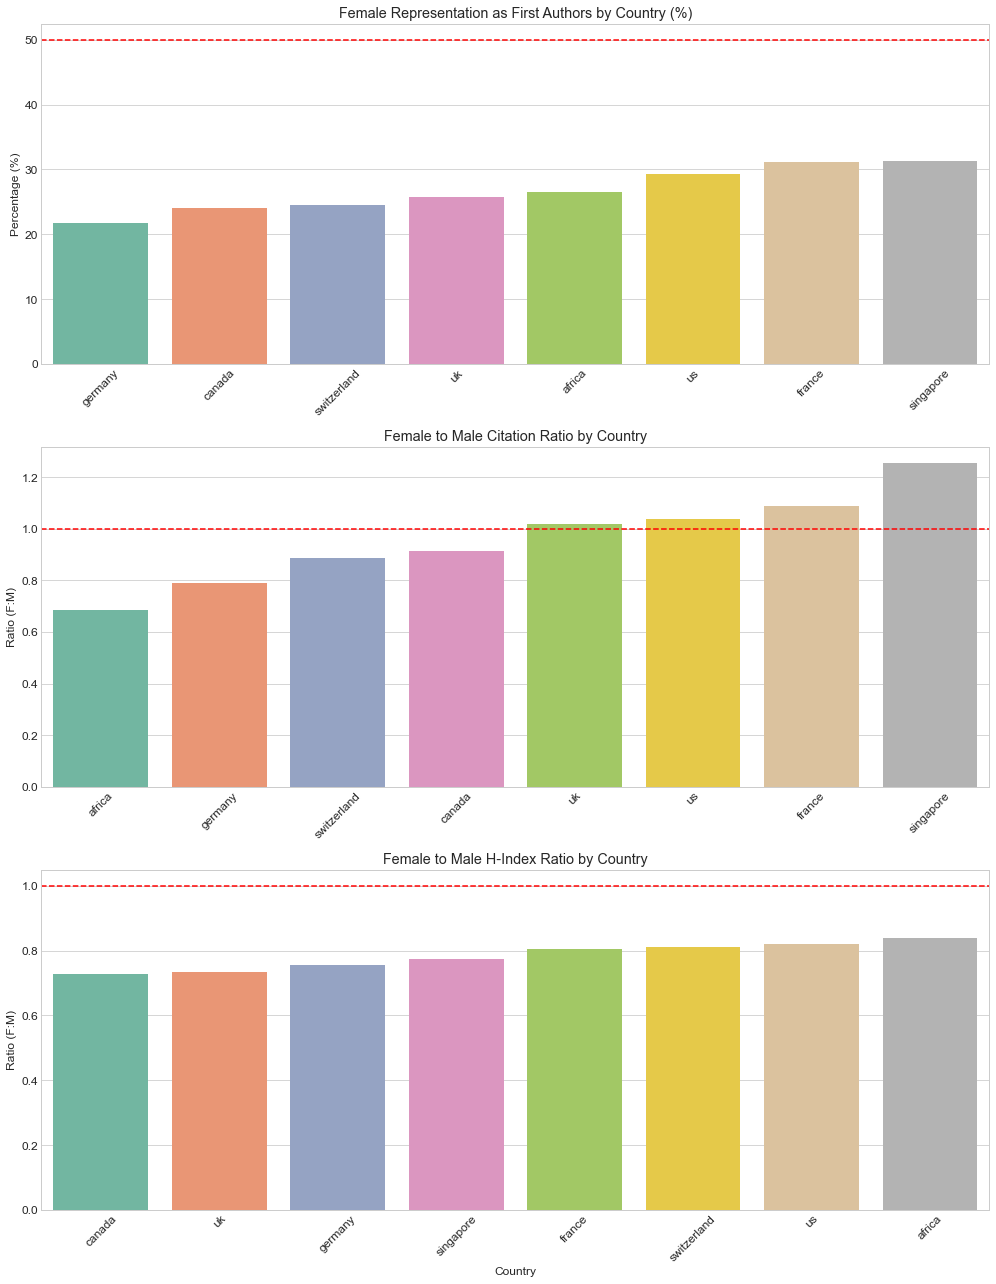

In [ ]:
# Calculate gender disparities
gender_disparities = {}

for country in df['Country'].unique():
    country_data = df[df['Country'] == country]
    
    # Skip if not enough data
    if len(country_data) < 10:
        continue
    
    # Gender representation
    first_author_gender = country_data['Gender (First Author)'].value_counts(normalize=True)
    
    # Publication count
    pub_count = len(country_data)
    
    # Citations
    citations_by_gender = country_data.groupby('Gender (First Author)')['Citations (Crossref)'].mean()
    
    # H-index
    h_index_by_gender = country_data.groupby('Gender (First Author)')['First Author H-Index'].mean()
    
    # Journal representation
    journal_gender = pd.crosstab(country_data['Publication Title'], country_data['Gender (First Author)'], normalize='index')
    
    # Store results
    gender_disparities[country] = {
        'representation': first_author_gender,
        'publication_count': pub_count,
        'citations': citations_by_gender,
        'h_index': h_index_by_gender,
        'journal_representation': journal_gender
    }

# Calculate disparity index (example: female-to-male ratio in various metrics)
disparity_summary = []

for country, data in gender_disparities.items():
    if 'female' in data['representation'] and 'male' in data['representation']:
        rep_ratio = data['representation']['female'] / data['representation']['male']
    else:
        rep_ratio = np.nan
        
    if 'female' in data['citations'] and 'male' in data['citations']:
        cite_ratio = data['citations']['female'] / data['citations']['male']
    else:
        cite_ratio = np.nan
        
    if 'female' in data['h_index'] and 'male' in data['h_index']:
        h_ratio = data['h_index']['female'] / data['h_index']['male']
    else:
        h_ratio = np.nan
        
    disparity_summary.append({
        'Country': country,
        'Publication_Count': data['publication_count'],
        'Female_Representation': data['representation'].get('female', 0) * 100,
        'Representation_Ratio': rep_ratio,
        'Citation_Ratio': cite_ratio,
        'H_Index_Ratio': h_ratio
    })

disparity_df = pd.DataFrame(disparity_summary)
print("Country Gender Disparity Summary:")
print(disparity_df)

# Visualization
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# Representation ratio
sns.barplot(x='Country', y='Female_Representation', data=disparity_df.sort_values('Female_Representation'), ax=axes[0])
axes[0].set_title('Female Representation as First Authors by Country (%)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Percentage (%)')
axes[0].axhline(y=50, color='r', linestyle='--')
axes[0].tick_params(axis='x', rotation=45)

# Citation ratio
sns.barplot(x='Country', y='Citation_Ratio', data=disparity_df.sort_values('Citation_Ratio'), ax=axes[1])
axes[1].set_title('Female to Male Citation Ratio by Country')
axes[1].set_xlabel('')
axes[1].set_ylabel('Ratio (F:M)')
axes[1].axhline(y=1, color='r', linestyle='--')
axes[1].tick_params(axis='x', rotation=45)

# H-index ratio
sns.barplot(x='Country', y='H_Index_Ratio', data=disparity_df.sort_values('H_Index_Ratio'), ax=axes[2])
axes[2].set_title('Female to Male H-Index Ratio by Country')
axes[2].set_xlabel('Country')
axes[2].set_ylabel('Ratio (F:M)')
axes[2].axhline(y=1, color='r', linestyle='--')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('country_gender_disparities.png', dpi=300)
plt.show()

### Journal-level

First Author Gender Distribution by Journal (%):
Gender (First Author)                                 Male     Female  Count
Publication Title                                                           
Applied Catalysis A: General                     64.849354  35.150646   2091
Energy Policy                                    71.185331  28.814669   1527
International Journal of Greenhouse Gas Control  71.582734  28.417266   1390
International Journal of Hydrogen Energy         74.549311  25.450689   6601
Solar Energy Materials and Solar Cells           76.081483  23.918517   4369
Solar Energy                                     77.956742  22.043258   2173

Citation Statistics by Journal and Gender:
                                                 count             mean  \
Gender                                          Female  Male     Female   
Publication Title                                                         
Applied Catalysis A: General                       735  1352  40.5

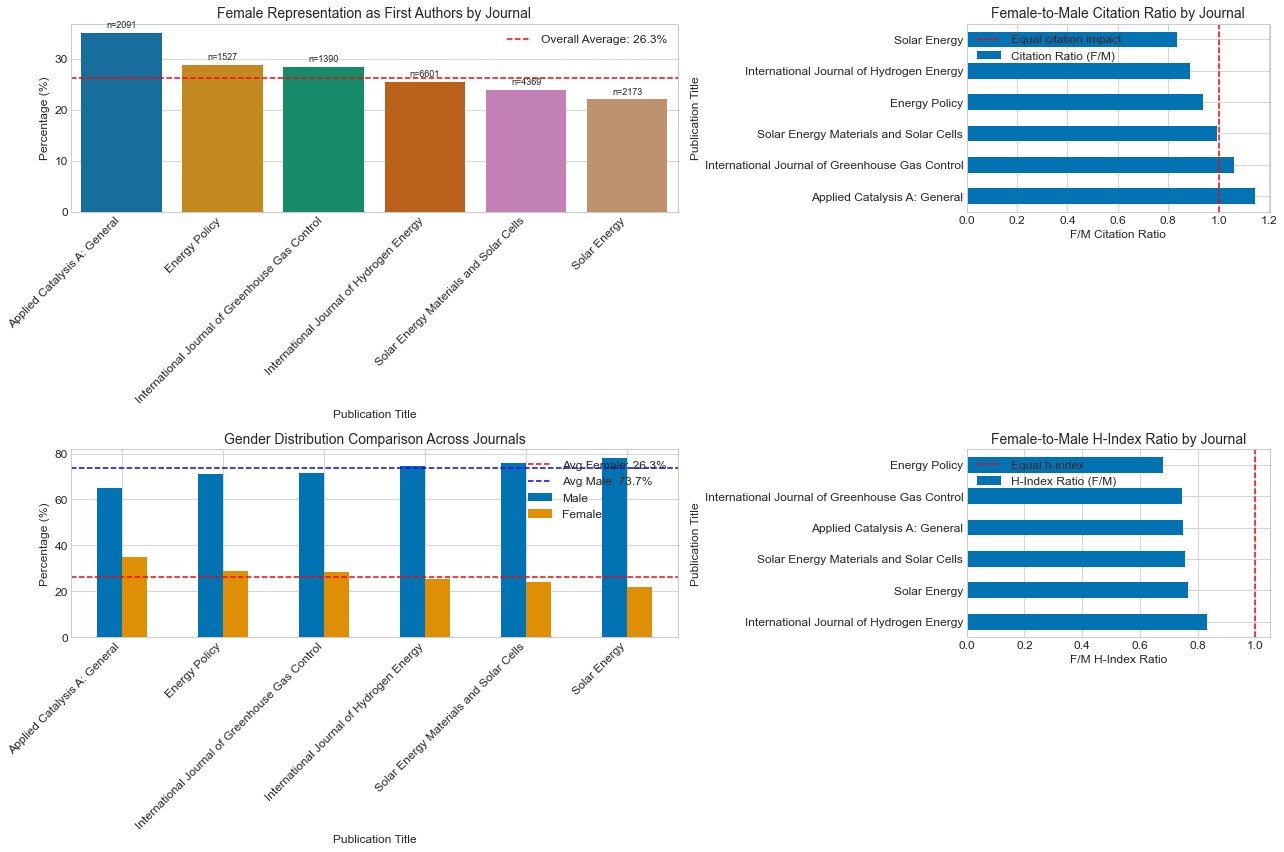


Chi-square test for independence between journal and gender: χ²=128.25, p=0.000000

Female Representation by Journal and Year (%):
Publication Title  Applied Catalysis A: General  Energy Policy  \
Publication Year                                                 
2010                                  36.086957      23.387097   
2011                                  34.934498      27.368421   
2012                                  30.357143      26.428571   
2013                                  29.629630      30.000000   
2014                                  39.534884      28.089888   
2015                                  40.265487      32.876712   
2016                                  32.258065      31.372549   
2017                                  36.633663      26.771654   
2018                                  31.168831      28.057554   
2019                                  40.707965      28.244275   
2020                                  32.173913      35.051546   
2021      

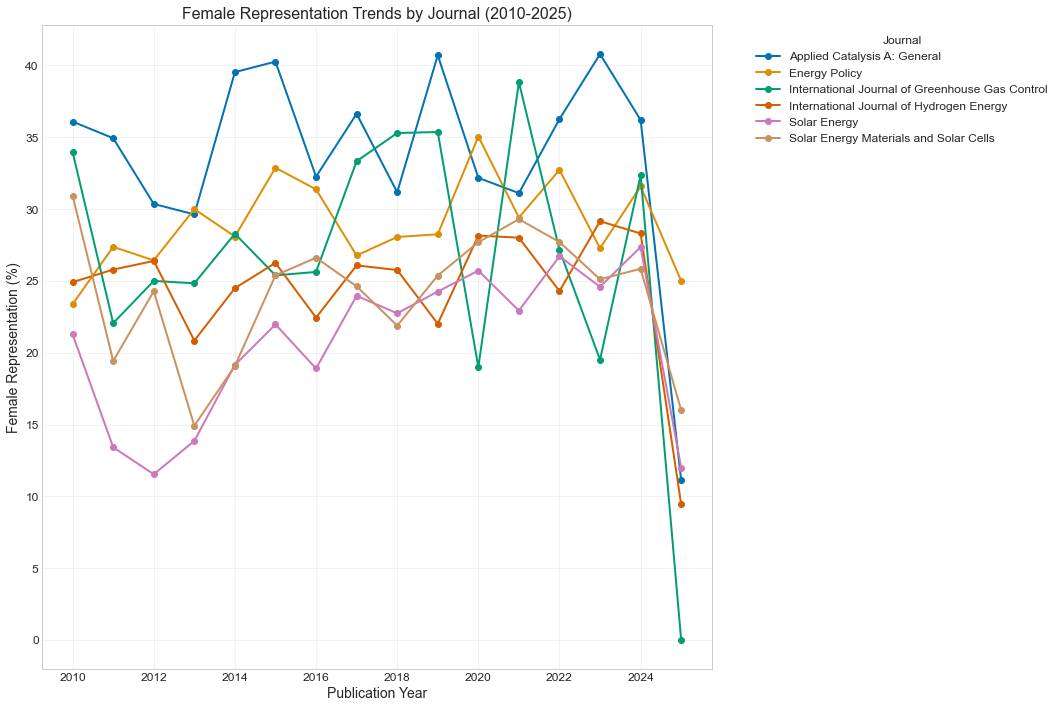


Trends in Female Representation by Journal:
                                                    slope r_squared   p_value  \
Solar Energy                                     0.531458  0.228539  0.061072   
Energy Policy                                    0.183515  0.078428  0.293471   
Solar Energy Materials and Solar Cells           0.088848  0.008513  0.733965   
International Journal of Hydrogen Energy         -0.15526  0.025209   0.55699   
Applied Catalysis A: General                     -0.38702  0.066945   0.33324   
International Journal of Greenhouse Gas Control -0.502882  0.067049  0.332849   

                                                significant  
Solar Energy                                          False  
Energy Policy                                         False  
Solar Energy Materials and Solar Cells                False  
International Journal of Hydrogen Energy              False  
Applied Catalysis A: General                          False  
International J

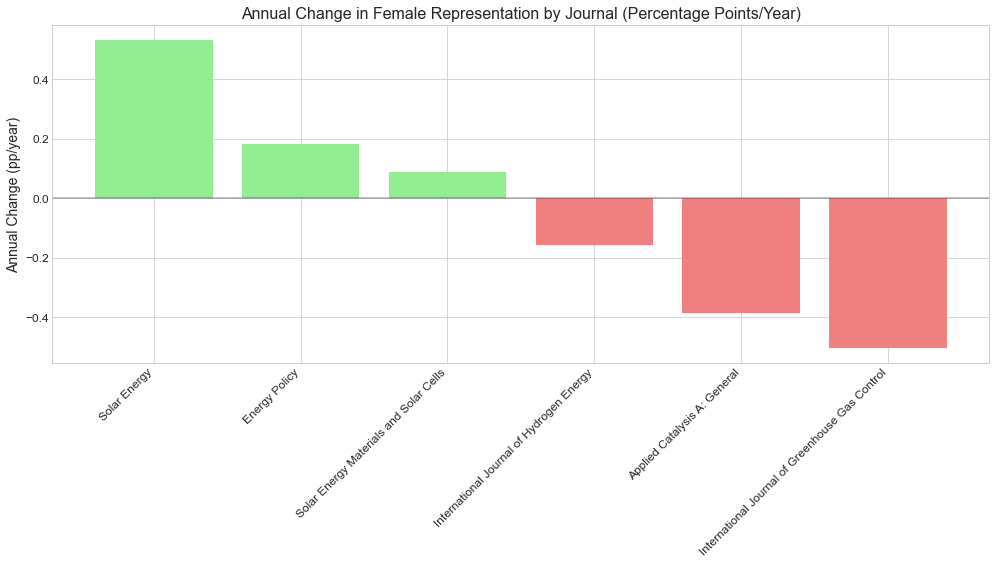


Citation Differences by Journal (controlling for gender):
Gender                                              Female       Male  \
Publication Title                                                       
Applied Catalysis A: General                     40.555102  35.398669   
International Journal of Greenhouse Gas Control  38.810127  36.571429   
Solar Energy Materials and Solar Cells           38.548325  38.887200   
Energy Policy                                    56.161364  60.013863   
International Journal of Hydrogen Energy         35.048214  39.531831   
Solar Energy                                     36.338205  43.444312   

Gender                                           Difference (F-M)  \
Publication Title                                                   
Applied Catalysis A: General                             5.156433   
International Journal of Greenhouse Gas Control          2.238698   
Solar Energy Materials and Solar Cells                  -0.338874   
Energy Poli

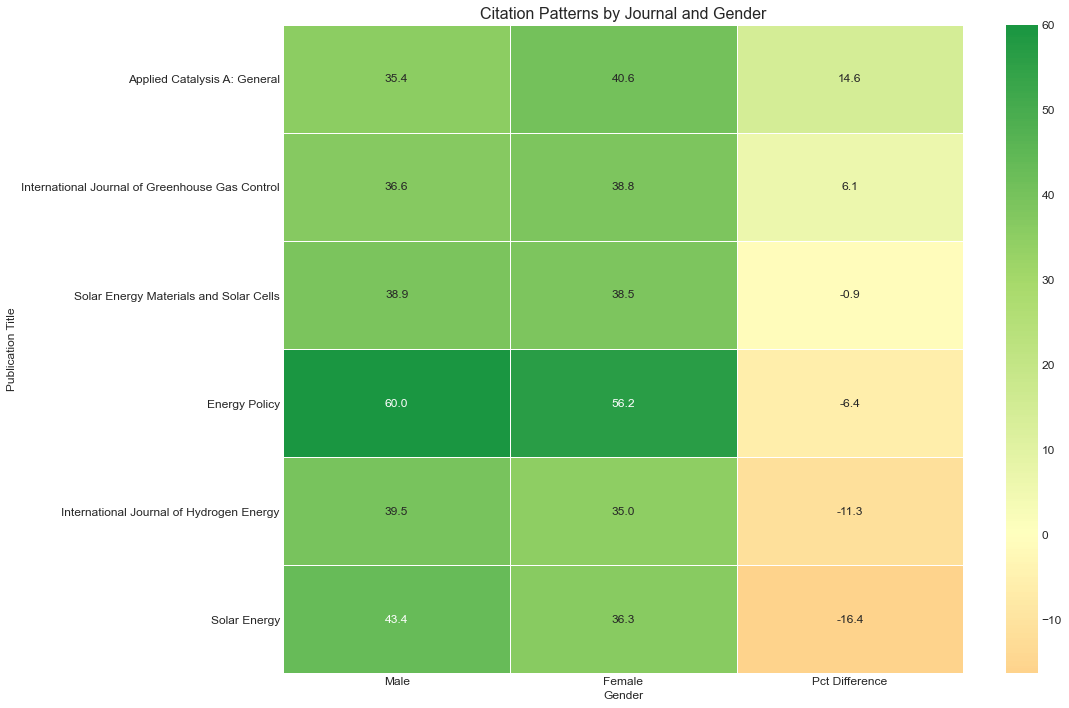


Journal Gender Equity Assessment:
                                                 Female_Representation  \
Publication Title                                                        
Applied Catalysis A: General                                 35.150646   
International Journal of Greenhouse Gas Control              28.417266   
International Journal of Hydrogen Energy                     25.450689   
Solar Energy Materials and Solar Cells                       23.918517   
Energy Policy                                                28.814669   
Solar Energy                                                 22.043258   

                                                 Citation_Ratio  \
Publication Title                                                 
Applied Catalysis A: General                           1.145667   
International Journal of Greenhouse Gas Control        1.061214   
International Journal of Hydrogen Energy               0.886582   
Solar Energy Materials and Solar Cell

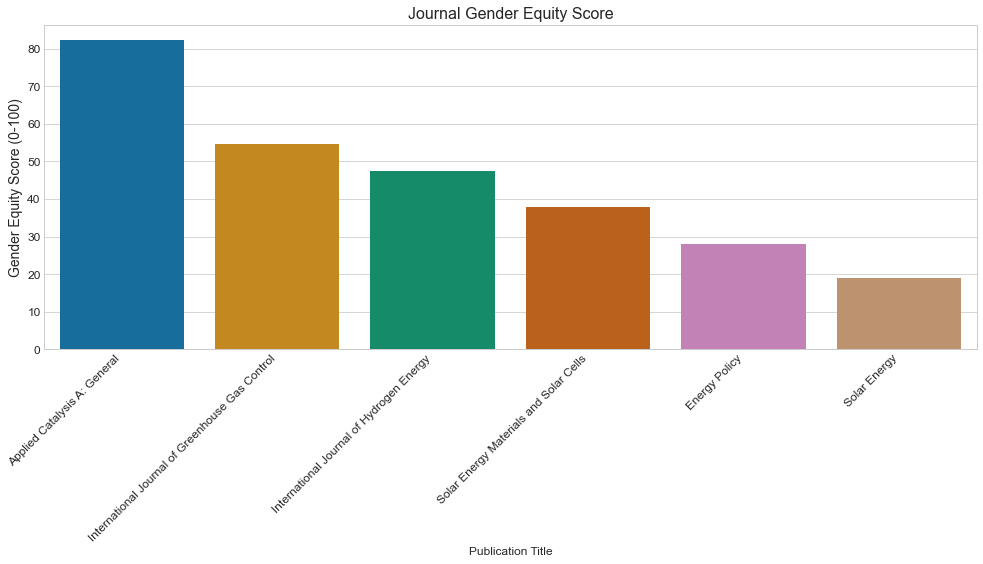

c:\Users\aznur\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\manifold\_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(


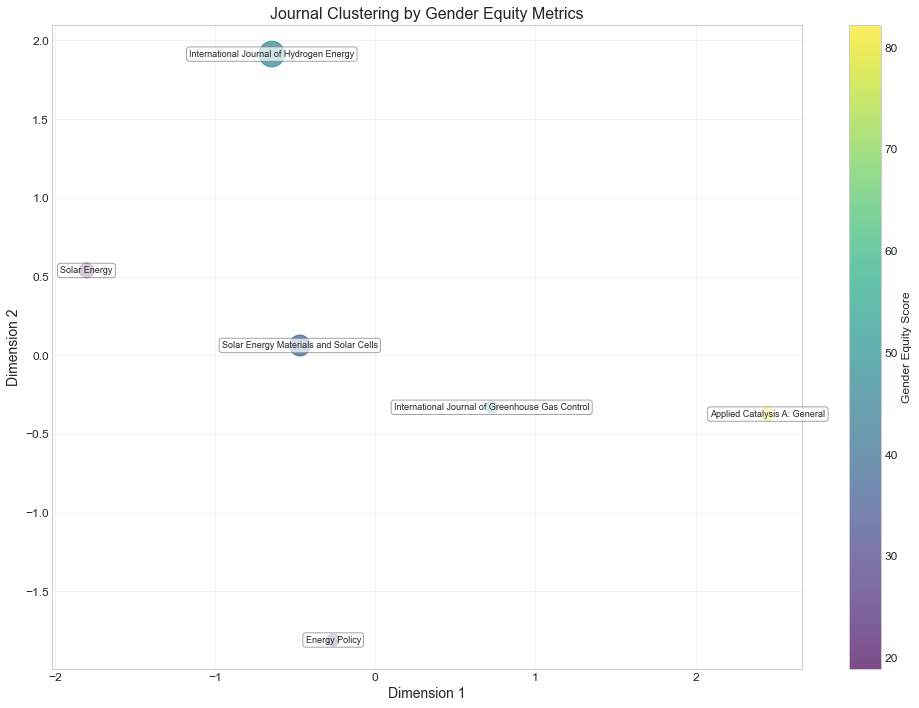


Female Representation by Country and Journal (%):
Publication Title  Applied Catalysis A: General  Energy Policy  \
Country                                                          
canada                                30.745342            NaN   
france                                41.078306            NaN   
germany                               28.825623            NaN   
singapore                             33.333333            NaN   
south africa                          24.324324       8.333333   
switzerland                           35.869565            NaN   
uk                                    36.805556      28.587196   
us                                    32.567050      30.427350   

Publication Title  International Journal of Greenhouse Gas Control  \
Country                                                              
canada                                                   25.000000   
france                                                   33.333333   
germany 

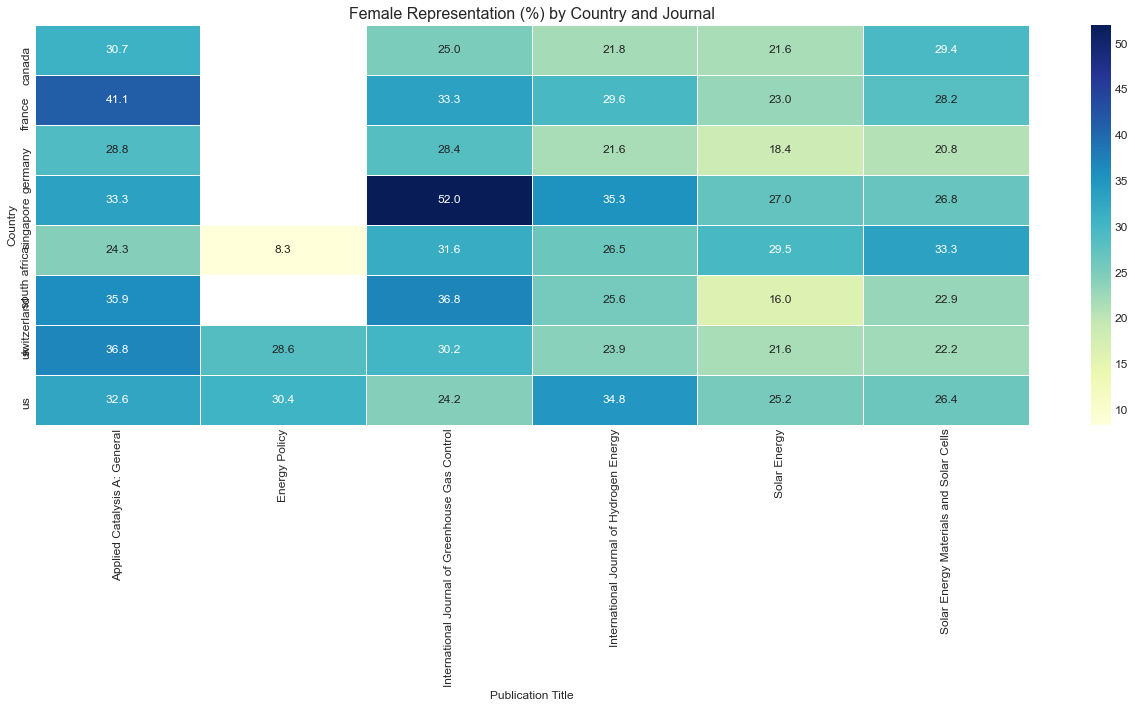


Two-way ANOVA Results for Country × Journal Interaction on Gender:
                                           sum_sq       df          F  \
C(Country)                               7.505409      7.0   5.607999   
C(Q("Publication Title"))               19.616321      5.0  20.520085   
C(Country):C(Q("Publication Title"))     0.928246     35.0   0.138716   
Residual                              3462.094169  18108.0        NaN   

                                            PR(>F)  
C(Country)                            1.775225e-06  
C(Q("Publication Title"))             1.714221e-20  
C(Country):C(Q("Publication Title"))  7.095652e-01  
Residual                                       NaN  


c:\Users\aznur\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\base\model.py:1888: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 35, but rank is 1
  warnings.warn('covariance of constraints does not have full '


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

# Set plotting style
plt.style.use('seaborn-whitegrid')
sns.set_palette("colorblind")
plt.rcParams['font.size'] = 12

# 1. First Author Gender Distribution by Journal
first_author_gender_by_journal = pd.crosstab(
    df['Publication Title'], 
    df['Gender (First Author)'], 
    normalize='index'
) * 100

# Rename columns for better readability
first_author_gender_by_journal = first_author_gender_by_journal.rename(columns={0: 'Male', 1: 'Female'})

# Add counts column for reference
journal_counts = df['Publication Title'].value_counts()
first_author_gender_by_journal['Count'] = journal_counts

# Sort by female representation
first_author_gender_by_journal = first_author_gender_by_journal.sort_values('Female', ascending=False)

print("First Author Gender Distribution by Journal (%):")
print(first_author_gender_by_journal)

# 2. Citation Analysis by Journal and Gender
citation_by_journal_gender = df.groupby(['Publication Title', 'Gender (First Author)'])['Citations'].agg(
    ['mean', 'median', 'std', 'count']
).reset_index()

# Map gender codes to readable labels
citation_by_journal_gender['Gender'] = citation_by_journal_gender['Gender (First Author)'].map({0: 'Male', 1: 'Female'})

# Pivot table for easier comparison
citation_pivot = citation_by_journal_gender.pivot_table(
    index='Publication Title', 
    columns='Gender', 
    values=['mean', 'count']
)

# Calculate citation ratios
citation_pivot['Citation Ratio (F/M)'] = citation_pivot[('mean', 'Female')] / citation_pivot[('mean', 'Male')]

# Sort by citation ratio
citation_pivot = citation_pivot.sort_values([('Citation Ratio (F/M)'), ('mean', 'Female')], ascending=False)

print("\nCitation Statistics by Journal and Gender:")
print(citation_pivot)

# 3. H-Index Analysis by Journal and Gender
hindex_by_journal_gender = df.groupby(['Publication Title', 'Gender (First Author)'])['First Author H-Index'].agg(
    ['mean', 'median', 'std', 'count']
).reset_index()
hindex_by_journal_gender['Gender'] = hindex_by_journal_gender['Gender (First Author)'].map({0: 'Male', 1: 'Female'})

# Pivot table for easier comparison
hindex_pivot = hindex_by_journal_gender.pivot_table(
    index='Publication Title', 
    columns='Gender', 
    values=['mean', 'count']
)

# Calculate h-index ratios
hindex_pivot['H-Index Ratio (F/M)'] = hindex_pivot[('mean', 'Female')] / hindex_pivot[('mean', 'Male')]

# Sort by h-index ratio
hindex_pivot = hindex_pivot.sort_values([('H-Index Ratio (F/M)'), ('mean', 'Female')], ascending=False)

print("\nH-Index Statistics by Journal and Gender:")
print(hindex_pivot)

# 4. Calculate differences in gender representation by journal relative to overall average
overall_female_pct = df['Gender (First Author)'].mean() * 100
first_author_gender_by_journal['Difference From Average'] = first_author_gender_by_journal['Female'] - overall_female_pct

# 5. Combined Visualization of Key Journal Gender Metrics
# Setup figure
plt.figure(figsize=(18, 12))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1], height_ratios=[1, 1])

# Plot 1: Female representation by journal
ax1 = plt.subplot(gs[0, 0])
bars = sns.barplot(
    x=first_author_gender_by_journal.index,
    y=first_author_gender_by_journal['Female'],
    ax=ax1
)
ax1.axhline(y=overall_female_pct, color='red', linestyle='--', 
           label=f'Overall Average: {overall_female_pct:.1f}%')
ax1.set_title('Female Representation as First Authors by Journal', fontsize=14)
ax1.set_ylabel('Percentage (%)', fontsize=12)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.legend()

# Add publication count as text
for i, p in enumerate(bars.patches):
    journal = first_author_gender_by_journal.index[i]
    count = first_author_gender_by_journal.loc[journal, 'Count']
    ax1.text(p.get_x() + p.get_width()/2., 
            p.get_height() + 1, 
            f'n={count}', 
            ha='center', fontsize=9)

# Plot 2: Female-to-male citation ratio by journal
ax2 = plt.subplot(gs[0, 1])
citation_pivot['Citation Ratio (F/M)'].plot(kind='barh', ax=ax2)
ax2.axvline(x=1, color='red', linestyle='--', label='Equal citation impact')
ax2.set_title('Female-to-Male Citation Ratio by Journal', fontsize=14)
ax2.set_xlabel('F/M Citation Ratio', fontsize=12)
ax2.grid(True, axis='x')
ax2.legend()

# Plot 3: Gender distribution comparison across journals
ax3 = plt.subplot(gs[1, 0])
first_author_gender_by_journal.plot(kind='bar', y=['Male', 'Female'], stacked=False, ax=ax3)
ax3.axhline(y=overall_female_pct, color='red', linestyle='--', 
           label=f'Avg Female: {overall_female_pct:.1f}%')
ax3.axhline(y=100-overall_female_pct, color='blue', linestyle='--', 
           label=f'Avg Male: {100-overall_female_pct:.1f}%')
ax3.set_title('Gender Distribution Comparison Across Journals', fontsize=14)
ax3.set_ylabel('Percentage (%)', fontsize=12)
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha='right')
ax3.legend()

# Plot 4: Female-to-male h-index ratio by journal
ax4 = plt.subplot(gs[1, 1])
hindex_pivot['H-Index Ratio (F/M)'].plot(kind='barh', ax=ax4)
ax4.axvline(x=1, color='red', linestyle='--', label='Equal h-index')
ax4.set_title('Female-to-Male H-Index Ratio by Journal', fontsize=14)
ax4.set_xlabel('F/M H-Index Ratio', fontsize=12)
ax4.grid(True, axis='x')
ax4.legend()

plt.tight_layout()
plt.savefig('journal_gender_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# 6. Statistical Tests: Are gender distributions independent of journal?
crosstab = pd.crosstab(df['Publication Title'], df['Gender (First Author)'])
chi2, p, dof, expected = stats.chi2_contingency(crosstab)
print(f"\nChi-square test for independence between journal and gender: χ²={chi2:.2f}, p={p:.6f}")

# 7. Time trend analysis by journal
# Create pivot table of female representation by journal and year
gender_by_journal_year = df.pivot_table(
    index='Publication Year',
    columns='Publication Title',
    values='Gender (First Author)',
    aggfunc='mean'
) * 100

print("\nFemale Representation by Journal and Year (%):")
print(gender_by_journal_year)

# Plot time trends for each journal
plt.figure(figsize=(15, 10))
for journal in gender_by_journal_year.columns:
    journal_data = gender_by_journal_year[journal].dropna()
    if len(journal_data) >= 5:  # Only plot if we have enough years of data
        plt.plot(journal_data.index, journal_data.values, marker='o', linewidth=2, label=journal)

plt.title('Female Representation Trends by Journal (2010-2025)', fontsize=16)
plt.xlabel('Publication Year', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(title='Journal', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('female_representation_trends_by_journal.png', dpi=300, bbox_inches='tight')
plt.show()

# 8. Calculate linear trend slopes for each journal
journal_trends = {}
for journal in gender_by_journal_year.columns:
    journal_data = gender_by_journal_year[journal].dropna()
    if len(journal_data) >= 5:  # Only analyze if we have enough years of data
        years = journal_data.index.astype(float)
        slope, intercept, r_value, p_value, std_err = stats.linregress(years, journal_data.values)
        journal_trends[journal] = {
            'slope': slope,
            'r_squared': r_value**2,
            'p_value': p_value,
            'significant': p_value < 0.05
        }

journal_trends_df = pd.DataFrame(journal_trends).T
journal_trends_df = journal_trends_df.sort_values('slope', ascending=False)

print("\nTrends in Female Representation by Journal:")
print(journal_trends_df)

# Visualization of trends
plt.figure(figsize=(14, 8))
bars = plt.bar(journal_trends_df.index, journal_trends_df['slope'], color=[
    'green' if row['significant'] else 'lightgreen' if row['slope'] > 0 else
    'red' if row['significant'] else 'lightcoral'
    for _, row in journal_trends_df.iterrows()
])
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
plt.title('Annual Change in Female Representation by Journal (Percentage Points/Year)', fontsize=16)
plt.ylabel('Annual Change (pp/year)', fontsize=14)
plt.xticks(rotation=45, ha='right')

# Add significance markers
for i, p in enumerate(bars):
    if journal_trends_df.iloc[i]['significant']:
        plt.text(p.get_x() + p.get_width()/2., p.get_height() + 0.05, '*', 
                ha='center', va='bottom', fontweight='bold', fontsize=16)

plt.tight_layout()
plt.savefig('female_representation_trends_slopes_by_journal.png', dpi=300)
plt.show()

# 9. Journal-level citation analysis controlling for author gender
# Create heatmap of citation differences
citation_by_journal_gender_wide = citation_by_journal_gender.pivot(
    index='Publication Title', 
    columns='Gender', 
    values='mean'
)
citation_by_journal_gender_wide['Difference (F-M)'] = citation_by_journal_gender_wide['Female'] - citation_by_journal_gender_wide['Male']
citation_by_journal_gender_wide['Pct Difference'] = (citation_by_journal_gender_wide['Difference (F-M)'] / citation_by_journal_gender_wide['Male']) * 100

# Sort by percentage difference
citation_by_journal_gender_wide = citation_by_journal_gender_wide.sort_values('Pct Difference', ascending=False)

print("\nCitation Differences by Journal (controlling for gender):")
print(citation_by_journal_gender_wide)

# Custom colormap for the heatmap (diverging from red to white to green)
colors = ['#d7191c', '#fdae61', '#ffffbf', '#a6d96a', '#1a9641']
cmap = LinearSegmentedColormap.from_list('custom_diverging', colors, N=256)

# Heatmap visualization
plt.figure(figsize=(16, 10))
sns.heatmap(
    citation_by_journal_gender_wide[['Male', 'Female', 'Pct Difference']],
    cmap=cmap,
    center=0,
    annot=True,
    fmt='.1f',
    linewidths=.5
)
plt.title('Citation Patterns by Journal and Gender', fontsize=16)
plt.tight_layout()
plt.savefig('citation_gender_differences_by_journal.png', dpi=300)
plt.show()

# 10. Comprehensive Journal Gender Equity Assessment
# Create a composite journal gender equity score
journal_equity = pd.DataFrame({
    'Female_Representation': first_author_gender_by_journal['Female'],
    'Citation_Ratio': citation_pivot['Citation Ratio (F/M)'],
    'H_Index_Ratio': hindex_pivot['H-Index Ratio (F/M)'],
    'Publication_Count': first_author_gender_by_journal['Count']
})

# Normalize all metrics to 0-100 scale
for col in ['Female_Representation', 'Citation_Ratio', 'H_Index_Ratio']:
    min_val = journal_equity[col].min()
    max_val = journal_equity[col].max()
    journal_equity[f'{col}_Normalized'] = ((journal_equity[col] - min_val) / (max_val - min_val)) * 100

# Calculate composite gender equity score
journal_equity['Gender_Equity_Score'] = (
    journal_equity['Female_Representation_Normalized'] +
    journal_equity['Citation_Ratio_Normalized'] +
    journal_equity['H_Index_Ratio_Normalized']
) / 3

# Sort by equity score
journal_equity = journal_equity.sort_values('Gender_Equity_Score', ascending=False)

print("\nJournal Gender Equity Assessment:")
print(journal_equity[['Female_Representation', 'Citation_Ratio', 'H_Index_Ratio', 'Gender_Equity_Score', 'Publication_Count']])

# Visualization of journal gender equity score
plt.figure(figsize=(14, 8))
sns.barplot(x=journal_equity.index, y=journal_equity['Gender_Equity_Score'])
plt.title('Journal Gender Equity Score', fontsize=16)
plt.ylabel('Gender Equity Score (0-100)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('journal_gender_equity_score.png', dpi=300)
plt.show()

# 11. Multi-dimensional scaling plot to visualize journal clustering by gender metrics
from sklearn.manifold import MDS
from sklearn.preprocessing import StandardScaler

# Select metrics for clustering
metrics_for_clustering = ['Female_Representation', 'Citation_Ratio', 'H_Index_Ratio']
journal_metrics = journal_equity[metrics_for_clustering].copy()

# Standardize the data
scaler = StandardScaler()
journal_metrics_scaled = scaler.fit_transform(journal_metrics)

# Apply MDS for dimensionality reduction
mds = MDS(n_components=2, random_state=42)
journal_positions = mds.fit_transform(journal_metrics_scaled)

# Create DataFrame with positions
journal_map = pd.DataFrame({
    'Journal': journal_equity.index,
    'x': journal_positions[:, 0],
    'y': journal_positions[:, 1],
    'Equity_Score': journal_equity['Gender_Equity_Score'],
    'Publication_Count': journal_equity['Publication_Count']
})

# Visualization
plt.figure(figsize=(14, 10))
scatter = plt.scatter(
    journal_map['x'], 
    journal_map['y'],
    s=journal_map['Publication_Count'] / 10,  # Size based on publication count
    c=journal_map['Equity_Score'],  # Color based on equity score
    cmap='viridis',
    alpha=0.7
)

# Add journal labels
for i, journal in enumerate(journal_map['Journal']):
    plt.annotate(
        journal,
        (journal_map['x'][i], journal_map['y'][i]),
        fontsize=9,
        ha='center',
        va='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.7)
    )

plt.colorbar(scatter, label='Gender Equity Score')
plt.title('Journal Clustering by Gender Equity Metrics', fontsize=16)
plt.xlabel('Dimension 1', fontsize=14)
plt.ylabel('Dimension 2', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('journal_gender_clustering.png', dpi=300)
plt.show()

# 12. Country-Journal interaction analysis
# Create a heatmap of female representation by country and journal
country_journal_gender = df.pivot_table(
    index='Country',
    columns='Publication Title',
    values='Gender (First Author)',
    aggfunc='mean'
) * 100

print("\nFemale Representation by Country and Journal (%):")
print(country_journal_gender)

# Heatmap visualization
plt.figure(figsize=(18, 10))
sns.heatmap(
    country_journal_gender,
    cmap='YlGnBu',
    annot=True,
    fmt='.1f',
    linewidths=.5
)
plt.title('Female Representation (%) by Country and Journal', fontsize=16)
plt.tight_layout()
plt.savefig('female_representation_country_journal_heatmap.png', dpi=300)
plt.show()

# 13. Two-way ANOVA to test for country-journal interaction effects on gender
from statsmodels.formula.api import ols

# Prepare data for ANOVA
anova_data = df[['Country', 'Publication Title', 'Gender (First Author)']].copy()
formula = 'Q("Gender (First Author)") ~ C(Country) + C(Q("Publication Title")) + C(Country):C(Q("Publication Title"))'
model = ols(formula, data=anova_data).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print("\nTwo-way ANOVA Results for Country × Journal Interaction on Gender:")
print(anova_table)

First Author Gender Distribution by Journal (%):
Gender (First Author)                               female       male
Publication Title                                                    
Applied Catalysis A: General                     35.176358  64.823642
Energy Policy                                    29.185375  70.814625
International Journal of Greenhouse Gas Control  28.336902  71.663098
International Journal of Hydrogen Energy         25.478379  74.521621
Solar Energy                                     22.003660  77.996340
Solar Energy Materials and Solar Cells           23.874800  76.125200

All Authors Gender Distribution by Journal (including First Authors) (%):
                                                    female       male
Applied Catalysis A: General                     66.394163  33.605837
Energy Policy                                    48.302674  51.697326
International Journal of Greenhouse Gas Control  61.756232  38.243768
International Journal of Hydrogen En

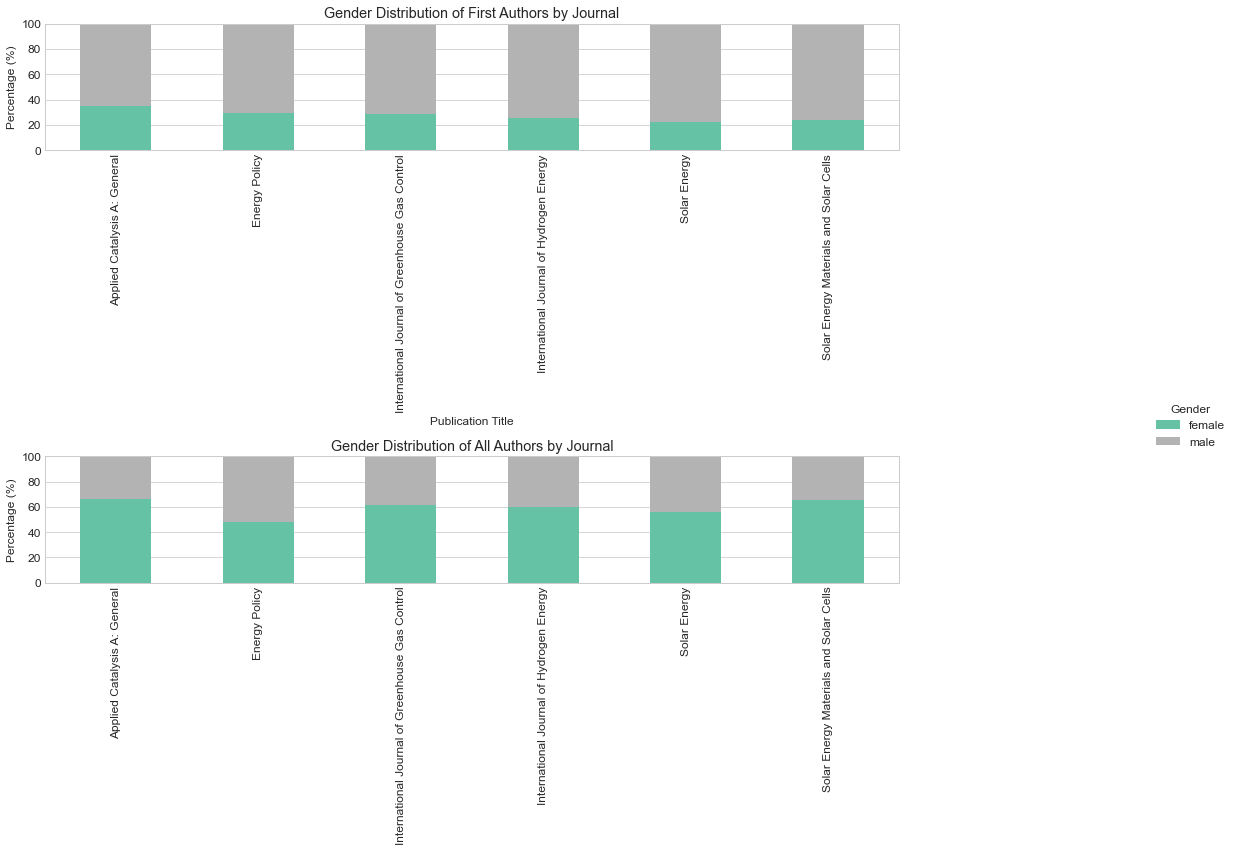

In [ ]:
# Gender distribution of first authors by journal
first_author_gender_by_journal = pd.crosstab(
    df['Publication Title'], 
    df['Gender (First Author)'], 
    normalize='index'
) * 100

print("First Author Gender Distribution by Journal (%):")
print(first_author_gender_by_journal)

# All authors gender distribution by journal (including first authors)
journal_all_gender_counts = {}

for journal in df['Publication Title'].unique():
    journal_rows = df[df['Publication Title'] == journal]
    
    all_genders = []
    
    for idx, row in journal_rows.iterrows():
        first_author_gender = row['Gender (First Author)']
        if pd.notna(first_author_gender):  # Check if not NaN
            all_genders.append(first_author_gender)
        
        # Add the other authors' genders
        other_authors_genders = row['Gender (Authors)']
        if isinstance(other_authors_genders, list):
            all_genders.extend(other_authors_genders)
        else:
            try:
                parsed_genders = eval(other_authors_genders) if isinstance(other_authors_genders, str) else other_authors_genders
                if isinstance(parsed_genders, list):
                    all_genders.extend(parsed_genders)
            except:
                pass
                
    gender_counts = pd.Series(all_genders).value_counts(normalize=True) * 100
    journal_all_gender_counts[journal] = gender_counts

all_authors_gender_by_journal = pd.DataFrame(journal_all_gender_counts).transpose()
print("\nAll Authors Gender Distribution by Journal (including First Authors) (%):")
print(all_authors_gender_by_journal)

fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# First authors
first_author_gender_by_journal.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2')
axes[0].set_title('Gender Distribution of First Authors by Journal')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_ylim(0, 100)
# Remove the default legend - we'll create a custom one
axes[0].get_legend().remove()

# All authors
all_authors_gender_by_journal.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2')
axes[1].set_title('Gender Distribution of All Authors by Journal')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_ylim(0, 100)
# Remove the default legend - we'll create a custom one
axes[1].get_legend().remove()

# Create a single legend for the entire figure
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, title='Gender', loc='center right', bbox_to_anchor=(1.15, 0.5))

# Adjust the layout to make room for the legend
plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig('gender_distribution_by_journal.png', dpi=300, bbox_inches='tight')
plt.show()

Citation Metrics by Gender Composition:
                         mean  median  count
Gender_Composition                          
All female          37.331053    21.0   2631
All male            41.591706    21.0   2966
Equal               40.397183    23.0   2840
Majority female     34.899148    21.0   8329
Majority male       40.357909    20.0   1492


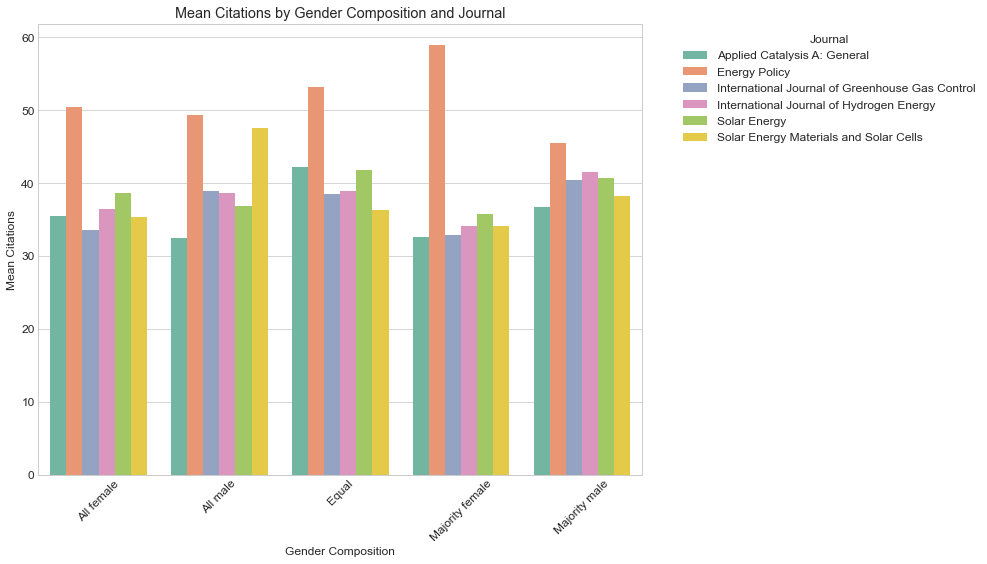

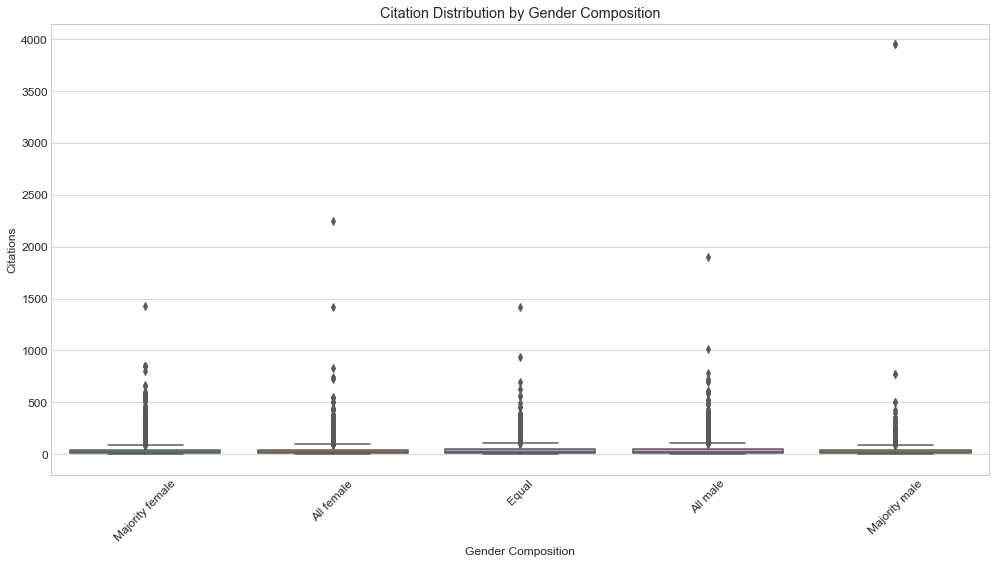

In [ ]:
# Define a function to categorize papers by gender composition
def categorize_gender_composition(row):
    genders = row['Gender (Authors)']
    if isinstance(genders, str):
        try:
            genders = eval(genders)
        except:
            return 'Unknown'
    
    if not isinstance(genders, list):
        return 'Unknown'
    
    male_count = genders.count('male')
    female_count = genders.count('female')
    total = len(genders)
    
    if total == 0:
        return 'Unknown'
    
    female_percentage = (female_count / total) * 100
    
    if female_percentage == 0:
        return 'All male'
    elif female_percentage < 50:
        return 'Majority male'
    elif female_percentage == 50:
        return 'Equal'
    elif female_percentage < 100:
        return 'Majority female'
    else:
        return 'All female'

df['Gender_Composition'] = df.apply(categorize_gender_composition, axis=1)

citation_by_gender_comp = df.groupby('Gender_Composition')['Citations (Crossref)'].agg(['mean', 'median', 'count'])
print("Citation Metrics by Gender Composition:")
print(citation_by_gender_comp)

journal_gender_citations = df.groupby(['Publication Title', 'Gender_Composition'])['Citations (Crossref)'].agg(['mean', 'median', 'count']).reset_index()

plt.figure(figsize=(14, 8))
sns.barplot(x='Gender_Composition', y='mean', data=journal_gender_citations, hue='Publication Title')
plt.title('Mean Citations by Gender Composition and Journal')
plt.xlabel('Gender Composition')
plt.ylabel('Mean Citations')
plt.xticks(rotation=45)
plt.legend(title='Journal', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('citation_impact_by_gender.png', dpi=300)
plt.show()

plt.figure(figsize=(14, 8))
sns.boxplot(x='Gender_Composition', y='Citations (Crossref)', data=df)
plt.title('Citation Distribution by Gender Composition')
plt.xlabel('Gender Composition')
plt.ylabel('Citations')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('citation_boxplot_by_gender.png', dpi=300)
plt.show()

Publication Count by Year and First Author Gender (2010-2025):
Gender (First Author)  female  male
Publication Year                   
2010                      271   662
2011                      297   902
2012                      282   833
2013                      259   950
2014                      328   990
2015                      370   937
2016                      333   990
2017                      369  1005
2018                      333   954
2019                      353   996
2020                      319   824
2021                      332   816
2022                      270   721
2023                      239   617
2024                      391   977
2025                       28   203


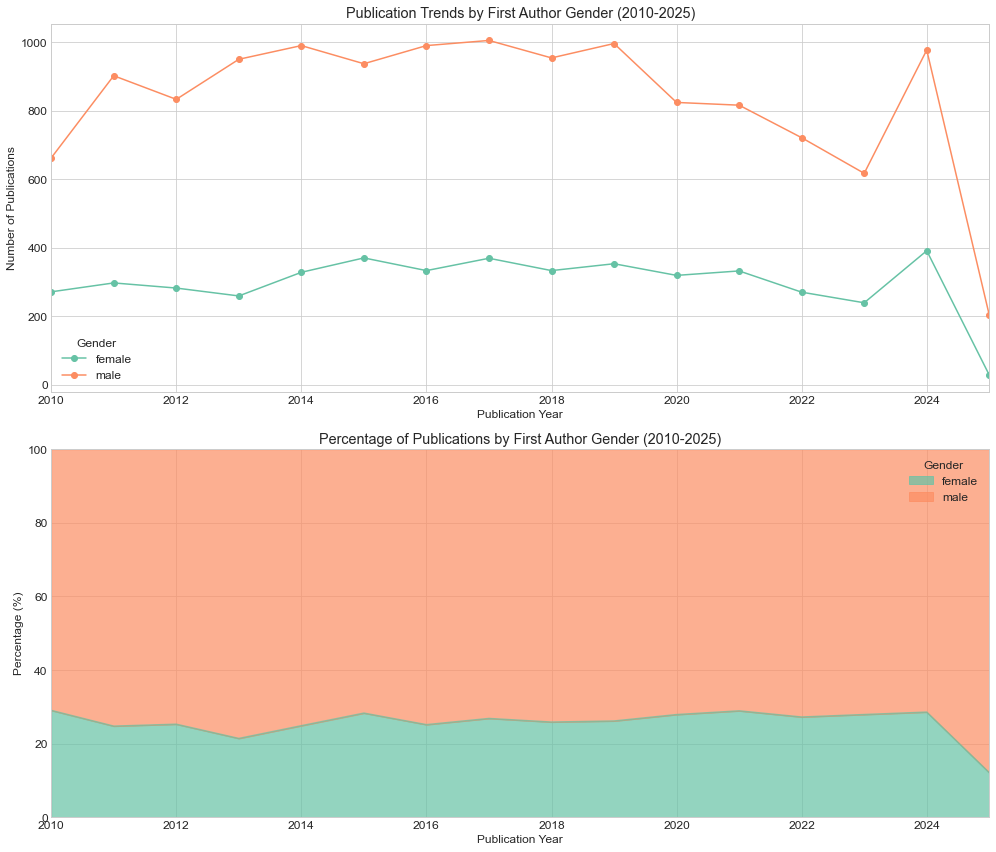

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

<Figure size 864x432 with 0 Axes>

In [ ]:
# Filter data for 2010-2025
filtered_df = df[(df['Publication Year'] >= 2010) & (df['Publication Year'] <= 2025)]

# Group by publication year and first author gender
yearly_gender_counts = pd.crosstab(filtered_df['Publication Year'], filtered_df['Gender (First Author)'])
print("Publication Count by Year and First Author Gender (2010-2025):")
print(yearly_gender_counts)

# Calculate percentage for stacked area chart
yearly_gender_percent = yearly_gender_counts.div(yearly_gender_counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Line chart of absolute numbers
yearly_gender_counts.plot(kind='line', marker='o', ax=axes[0])
axes[0].set_title('Publication Trends by First Author Gender (2010-2025)')
axes[0].set_xlabel('Publication Year')
axes[0].set_ylabel('Number of Publications')
axes[0].legend(title='Gender')
axes[0].set_xlim(2010, 2025)  # Set x-axis limits explicitly

# Stacked area chart for percentage
yearly_gender_percent.plot(kind='area', stacked=True, alpha=0.7, ax=axes[1])
axes[1].set_title('Percentage of Publications by First Author Gender (2010-2025)')
axes[1].set_xlabel('Publication Year')
axes[1].set_ylabel('Percentage (%)')
axes[1].legend(title='Gender')
axes[1].set_ylim(0, 100)
axes[1].set_xlim(2010, 2025)  # Set x-axis limits explicitly

plt.tight_layout()
plt.savefig('publication_trends_by_gender_2010_2025.png', dpi=300)
plt.show()

# For each journal separately
journals = filtered_df['Publication Title'].unique()

for journal in journals:
    journal_df = filtered_df[filtered_df['Publication Title'] == journal]
    journal_yearly_gender = pd.crosstab(journal_df['Publication Year'], journal_df['Gender (First Author)'])
    
    # Only plot if there's enough data
    if not journal_yearly_gender.empty and journal_yearly_gender.shape[0] > 1:
        plt.figure(figsize=(12, 6))
        journal_yearly_gender.plot(kind='line', marker='o')
        plt.title(f'Publication Trends for {journal} by First Author Gender (2010-2025)')
        plt.xlabel('Publication Year')
        plt.ylabel('Number of Publications')
        plt.legend(title='Gender')
        plt.xlim(2010, 2025)  # Set x-axis limits explicitly
        plt.tight_layout()
        plt.savefig(f'publication_trends_{journal.replace(" ", "_")}_2010_2025.png', dpi=300)
        plt.close()

C:\Users\aznur\AppData\Local\Temp/ipykernel_50488/2136122999.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


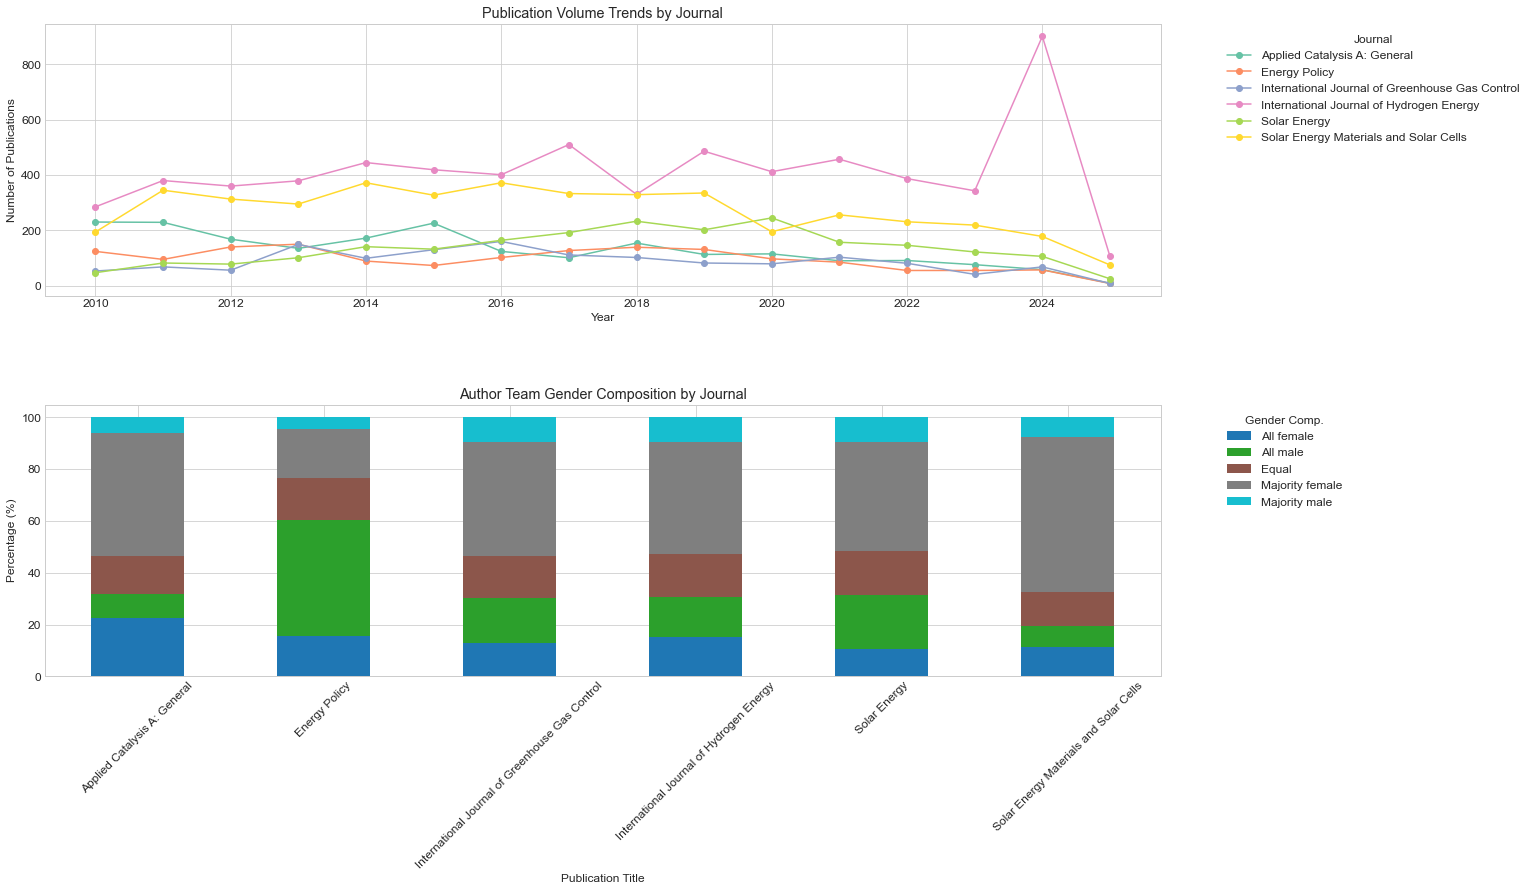

In [ ]:
# Create a comprehensive dashboard for journal analysis
fig = plt.figure(figsize=(20, 12))  # Reduced height since we now have only 2 plots
gs = fig.add_gridspec(2, 1, hspace=0.4, wspace=0.3)  # Changed to 2,1 since we have 2 plots now

# Publication Trends Over Time (Top Row)
ax3 = fig.add_subplot(gs[0, :])
yearly_journal_counts = df.groupby(['Publication Year', 'Publication Title']).size().unstack()
# Filter for years 2010-2025
yearly_journal_counts = yearly_journal_counts.loc[2010:2025]
yearly_journal_counts.plot(kind='line', marker='o', ax=ax3)
ax3.set_title('Publication Volume Trends by Journal')
ax3.set_xlabel('Year')
ax3.set_ylabel('Number of Publications')
ax3.legend(title='Journal', bbox_to_anchor=(1.05, 1), loc='upper left')

# Gender Composition by Journal (Bottom Row)
ax5 = fig.add_subplot(gs[1, :])
gender_comp_by_journal = pd.crosstab(df['Publication Title'], df['Gender_Composition'], normalize='index') * 100
gender_comp_by_journal.plot(kind='bar', stacked=True, ax=ax5, colormap='tab10')
ax5.set_title('Author Team Gender Composition by Journal')
ax5.set_ylabel('Percentage (%)')
ax5.tick_params(axis='x', rotation=45)
ax5.legend(title='Gender Comp.', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('journal_analysis_dashboard.png', dpi=300)
plt.show()

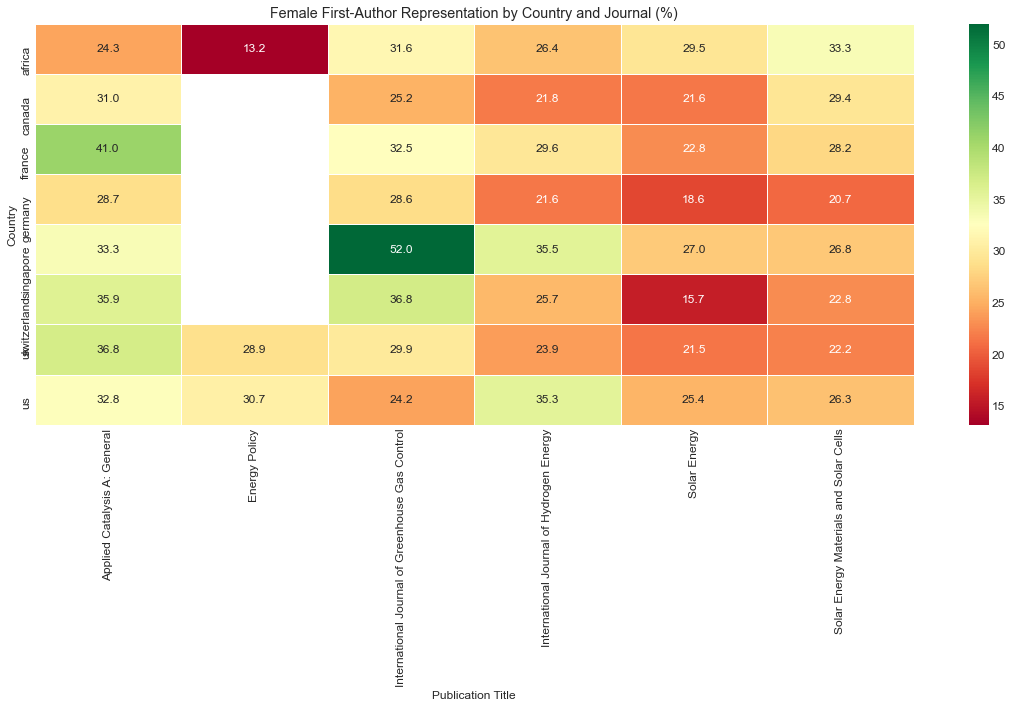

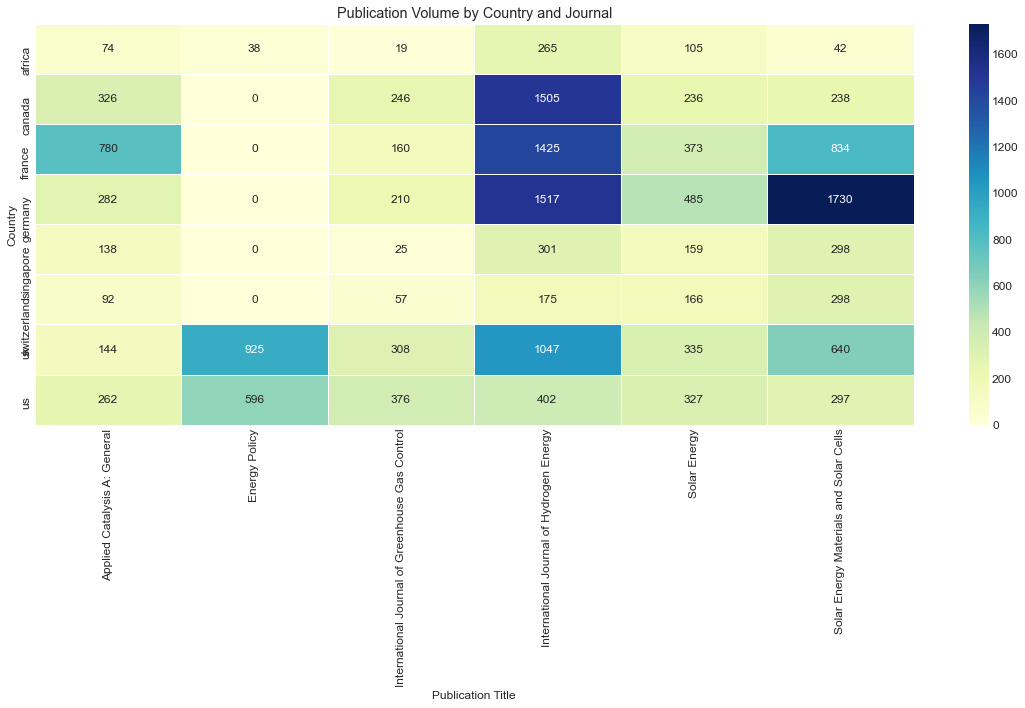

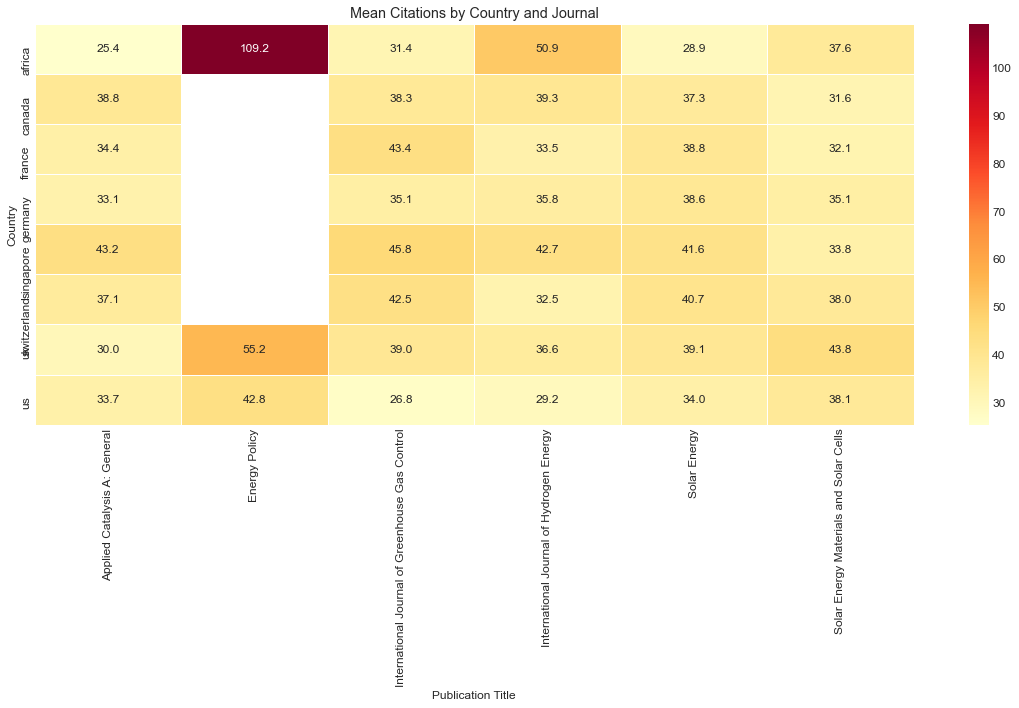

In [69]:
# Create a heatmap of female first-author representation by journal and country
female_representation = pd.pivot_table(
    data=df, 
    index='Country',
    columns='Publication Title',
    values='Gender (First Author)',
    aggfunc=lambda x: (x == 'female').mean() * 100
)

plt.figure(figsize=(16, 10))
sns.heatmap(female_representation, annot=True, cmap='RdYlGn', fmt='.1f', linewidths=.5)
plt.title('Female First-Author Representation by Country and Journal (%)')
plt.tight_layout()
plt.savefig('female_representation_heatmap.png', dpi=300)
plt.show()

# Heatmap of publication volume
publication_volume = pd.crosstab(df['Country'], df['Publication Title'])

plt.figure(figsize=(16, 10))
sns.heatmap(publication_volume, annot=True, cmap='YlGnBu', fmt='d', linewidths=.5)
plt.title('Publication Volume by Country and Journal')
plt.tight_layout()
plt.savefig('publication_volume_heatmap.png', dpi=300)
plt.show()

# Heatmap of citation impact
citation_impact = pd.pivot_table(
    data=df, 
    index='Country',
    columns='Publication Title',
    values='Citations (Crossref)',
    aggfunc='mean'
)

plt.figure(figsize=(16, 10))
sns.heatmap(citation_impact, annot=True, cmap='YlOrRd', fmt='.1f', linewidths=.5)
plt.title('Mean Citations by Country and Journal')
plt.tight_layout()
plt.savefig('citation_impact_heatmap.png', dpi=300)
plt.show()

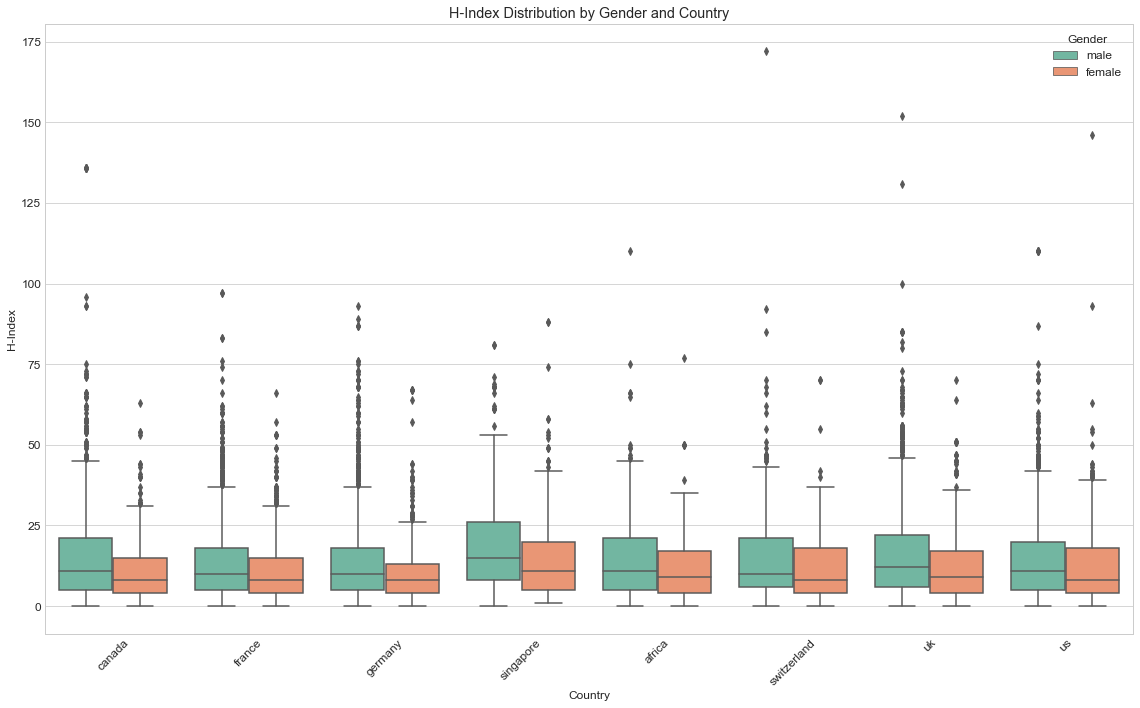

Mean H-Index by Country and Gender:
Gender (First Author)     female       male
Country                                    
africa                 12.840278  15.318987
canada                 11.031046  15.128713
france                 10.742370  13.318519
germany                10.254367  13.582951
singapore              14.550173  18.796148
switzerland            12.264249  15.106961
uk                     11.608447  15.789537
us                     12.131222  14.796460


<Figure size 1152x576 with 0 Axes>

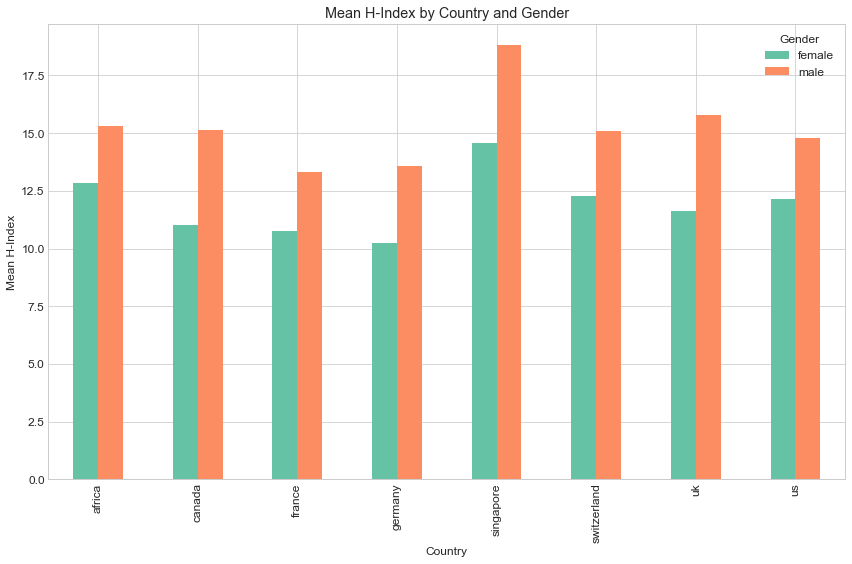

In [70]:
# H-index distribution by gender and country
plt.figure(figsize=(16, 10))
sns.boxplot(x='Country', y='First Author H-Index', hue='Gender (First Author)', data=df)
plt.title('H-Index Distribution by Gender and Country')
plt.xlabel('Country')
plt.ylabel('H-Index')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.tight_layout()
plt.savefig('h_index_distribution.png', dpi=300)
plt.show()

# Mean h-index by gender and country
h_index_means = df.groupby(['Country', 'Gender (First Author)'])['First Author H-Index'].mean().unstack()
print("Mean H-Index by Country and Gender:")
print(h_index_means)

# Visualization as grouped bar chart
plt.figure(figsize=(16, 8))
h_index_means.plot(kind='bar')
plt.title('Mean H-Index by Country and Gender')
plt.xlabel('Country')
plt.ylabel('Mean H-Index')
plt.legend(title='Gender')
plt.tight_layout()
plt.savefig('mean_h_index_by_country_gender.png', dpi=300)
plt.show()

Most female-skewed keywords:
                                  male_freq  female_freq      ratio      diff
additive                           0.000015     0.000379  25.019364  0.000364
cuprous oxide                      0.000015     0.000337  22.239434  0.000322
electrospray                       0.000015     0.000295  19.459505  0.000280
catalytic cracking                 0.000015     0.000295  19.459505  0.000280
heat treatment                     0.000015     0.000253  16.679576  0.000237
risk perception                    0.000015     0.000253  16.679576  0.000237
dynamic contact angle              0.000015     0.000253  16.679576  0.000237
acrylonitrile                      0.000015     0.000253  16.679576  0.000237
transition metals                  0.000015     0.000253  16.679576  0.000237
mineral trapping                   0.000015     0.000210  13.899646  0.000195
acetylene hydrogenation            0.000015     0.000210  13.899646  0.000195
carbon emission                    

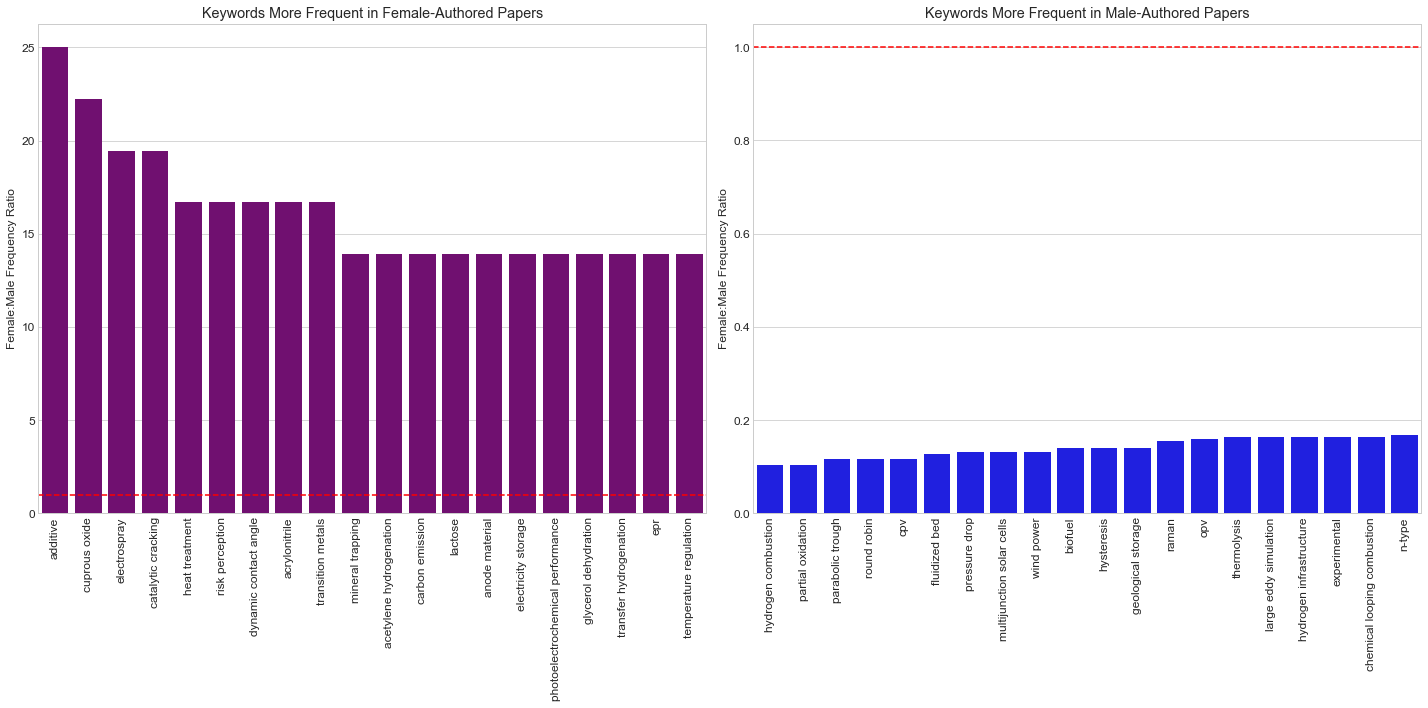

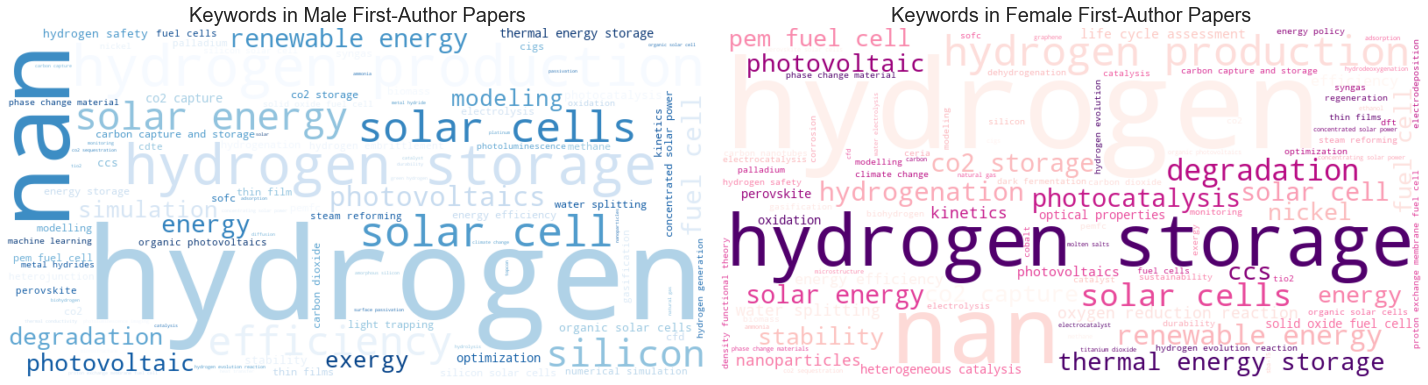

In [71]:
# Extract and analyze keywords
# First, combine all keywords for each gender
male_keywords = []
female_keywords = []

for _, row in df.iterrows():
    keywords = str(row['Keywords']).split(';')
    keywords = [k.strip().lower() for k in keywords]
    
    if row['Gender (First Author)'] == 'male':
        male_keywords.extend(keywords)
    elif row['Gender (First Author)'] == 'female':
        female_keywords.extend(keywords)

# Count keyword frequencies
male_keyword_counts = Counter(male_keywords)
female_keyword_counts = Counter(female_keywords)

# Normalize to account for different sample sizes
total_male = sum(male_keyword_counts.values())
total_female = sum(female_keyword_counts.values())

male_normalized = {k: v/total_male for k, v in male_keyword_counts.items()}
female_normalized = {k: v/total_female for k, v in female_keyword_counts.items()}

# Combine and calculate differences
all_keywords = set(male_normalized.keys()) | set(female_normalized.keys())
keyword_comparison = {}

for kw in all_keywords:
    male_freq = male_normalized.get(kw, 0)
    female_freq = female_normalized.get(kw, 0)
    
    if male_freq > 0 and female_freq > 0:
        ratio = female_freq / male_freq
        diff = female_freq - male_freq
        keyword_comparison[kw] = {
            'male_freq': male_freq,
            'female_freq': female_freq,
            'ratio': ratio,
            'diff': diff
        }

# Convert to DataFrame for easier analysis
keyword_df = pd.DataFrame.from_dict(keyword_comparison, orient='index')
keyword_df = keyword_df.sort_values('diff')

# Filter out rare keywords (must appear at least 5 times in total)
threshold = 5 / (total_male + total_female)
keyword_df = keyword_df[(keyword_df['male_freq'] > threshold) | (keyword_df['female_freq'] > threshold)]

# Get most female-skewed and most male-skewed keywords
female_skewed = keyword_df.sort_values('ratio', ascending=False).head(20)
male_skewed = keyword_df.sort_values('ratio').head(20)

print("Most female-skewed keywords:")
print(female_skewed)
print("\nMost male-skewed keywords:")
print(male_skewed)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Female-skewed keywords
sns.barplot(x=female_skewed.index, y='ratio', data=female_skewed, ax=axes[0], color='purple')
axes[0].set_title('Keywords More Frequent in Female-Authored Papers')
axes[0].set_ylabel('Female:Male Frequency Ratio')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90)
axes[0].axhline(y=1, color='r', linestyle='--')

# Male-skewed keywords
sns.barplot(x=male_skewed.index, y='ratio', data=male_skewed, ax=axes[1], color='blue')
axes[1].set_title('Keywords More Frequent in Male-Authored Papers')
axes[1].set_ylabel('Female:Male Frequency Ratio')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90)
axes[1].axhline(y=1, color='r', linestyle='--')

plt.tight_layout()
plt.savefig('gender_keyword_analysis.png', dpi=300)
plt.show()

# Create word clouds for visual comparison
plt.figure(figsize=(20, 10))

# Male word cloud
male_cloud = WordCloud(
    background_color='white',
    max_words=100,
    colormap='Blues',
    width=800,
    height=400
).generate_from_frequencies(male_normalized)

plt.subplot(1, 2, 1)
plt.imshow(male_cloud, interpolation='bilinear')
plt.axis('off')
plt.title('Keywords in Male First-Author Papers', fontsize=20)

# Female word cloud
female_cloud = WordCloud(
    background_color='white',
    max_words=100,
    colormap='RdPu',
    width=800,
    height=400
).generate_from_frequencies(female_normalized)

plt.subplot(1, 2, 2)
plt.imshow(female_cloud, interpolation='bilinear')
plt.axis('off')
plt.title('Keywords in Female First-Author Papers', fontsize=20)

plt.tight_layout()
plt.savefig('gender_keyword_wordclouds.png', dpi=300)
plt.show()

### Confidence %


Summary statistics for gender prediction confidence:
count    18151.000000
mean         0.790447
std          0.136860
min          0.524439
25%          0.686617
50%          0.804180
75%          0.922132
max          0.986692
Name: Gender likelihood (First Author), dtype: float64
Mean confidence for male first author predictions: 0.8215
Mean confidence for female first author predictions: 0.7035


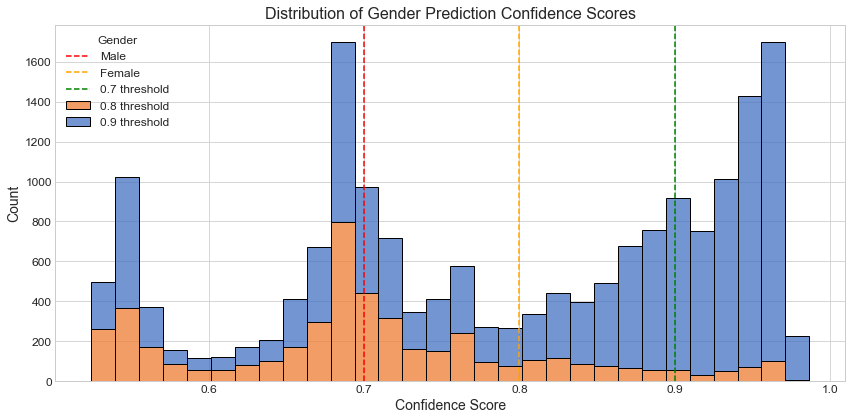


Sample distribution by confidence category:
Medium (0.7-0.9)    6370
Low (< 0.7)         6043
High (≥ 0.9)        5738
Name: Confidence_Category, dtype: int64

Country analysis (all data):
          field  total  female_pct   male_pct  high_conf_pct  \
3     singapore    920   31.304348  68.695652      11.521739   
1        france   3556   31.271091  68.728909      26.462317   
7            us   2240   29.107143  70.892857      31.116071   
4  south africa    540   26.296296  73.703704      21.296296   
6            uk   3374   25.726141  74.273859      31.387078   
5   switzerland    780   24.615385  75.384615      31.282051   
0        canada   2543   23.948093  76.051907      27.172631   
2       germany   4198   21.700810  78.299190      44.902334   

   female_high_conf_count  male_high_conf_count  
3                      14                    92  
1                      83                   858  
7                      31                   666  
4                       8        

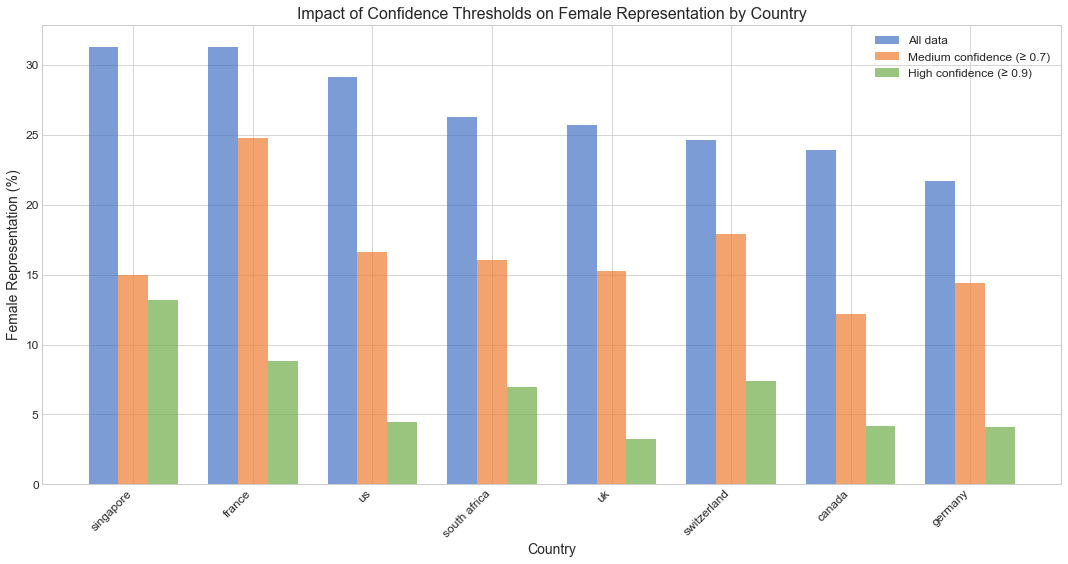


Gender distribution with bootstrap confidence intervals:
          field  total  female_pct  weighted_female_pct   ci_lower   ci_upper  \
3     singapore    920   31.304348            29.008921  28.260870  34.347826   
1        france   3556   31.271091            28.904483  29.723706  32.733408   
7            us   2240   29.107143            25.597493  27.187500  30.983259   
4  south africa    540   26.296296            23.373935  22.777778  30.000000   
6            uk   3374   25.726141            22.751734  24.184203  27.178423   
5   switzerland    780   24.615385            22.200724  21.538462  27.695513   
0        canada   2543   23.948093            20.901942  22.413488  25.756980   
2       germany   4198   21.700810            18.965700  20.438304  22.939495   

   ci_width  avg_confidence  
3  6.086957        0.712092  
1  3.009702        0.786688  
7  3.795759        0.783435  
4  7.222222        0.755370  
6  2.994221        0.787120  
5  6.157051        0.808000  
0 

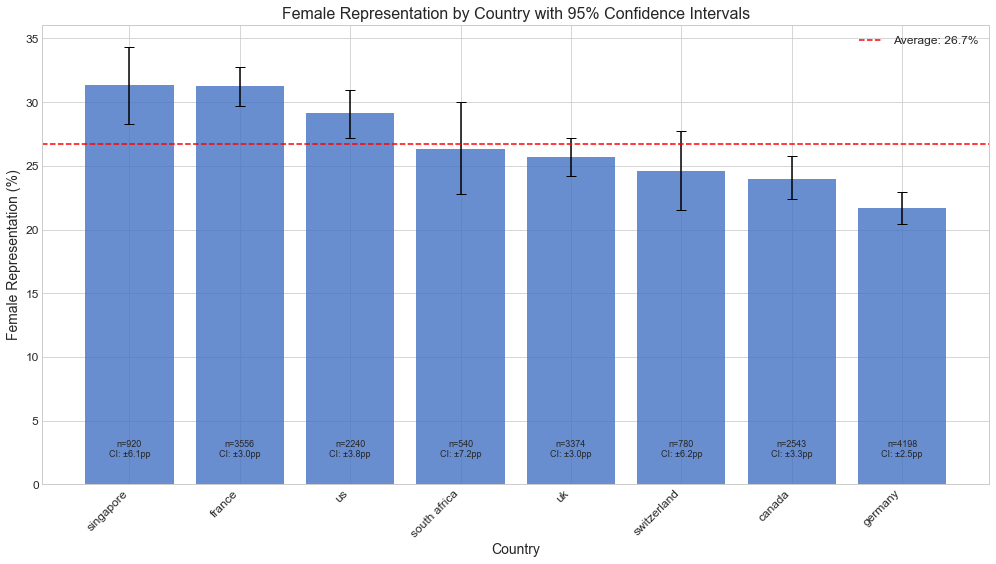


Weighted gender analysis (incorporating prediction confidence):
          field  total  female_pct  weighted_female_pct  weighted_ci_lower  \
3     singapore    920   31.304348            38.800482          37.395597   
1        france   3556   31.271091            35.537710          34.618136   
4  south africa    540   26.296296            33.478617          31.462730   
7            us   2240   29.107143            32.657281          31.565726   
6            uk   3374   25.726141            31.378524          30.501985   
0        canada   2543   23.948093            31.043820          30.105858   
5   switzerland    780   24.615385            30.460984          28.570482   
2       germany   4198   21.700810            26.856647          26.048704   

   weighted_ci_upper  weighted_margin_of_error  
3          40.205366                  1.404884  
1          36.457285                  0.919574  
4          35.494504                  2.015887  
7          33.748837                

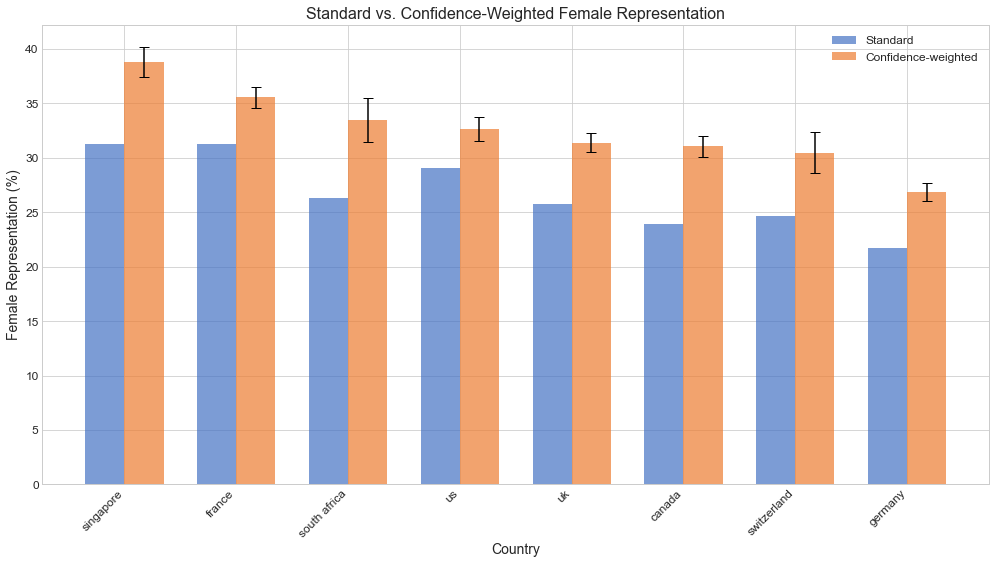


Journal-level weighted gender analysis:
                                             field  total  female_pct  \
0                     Applied Catalysis A: General   2091   35.150646   
3         International Journal of Hydrogen Energy   6601   25.450689   
1                                    Energy Policy   1527   28.814669   
2  International Journal of Greenhouse Gas Control   1390   28.417266   
5           Solar Energy Materials and Solar Cells   4369   23.918517   
4                                     Solar Energy   2173   22.043258   

   weighted_female_pct  weighted_ci_lower  weighted_ci_upper  \
0            37.676900          36.477315          38.876484   
3            31.827133          31.208754          32.445511   
1            31.666905          30.262814          33.070995   
2            31.469951          30.010398          32.929503   
5            30.123412          29.351325          30.895500   
4            28.549270          27.523788          29.574752   

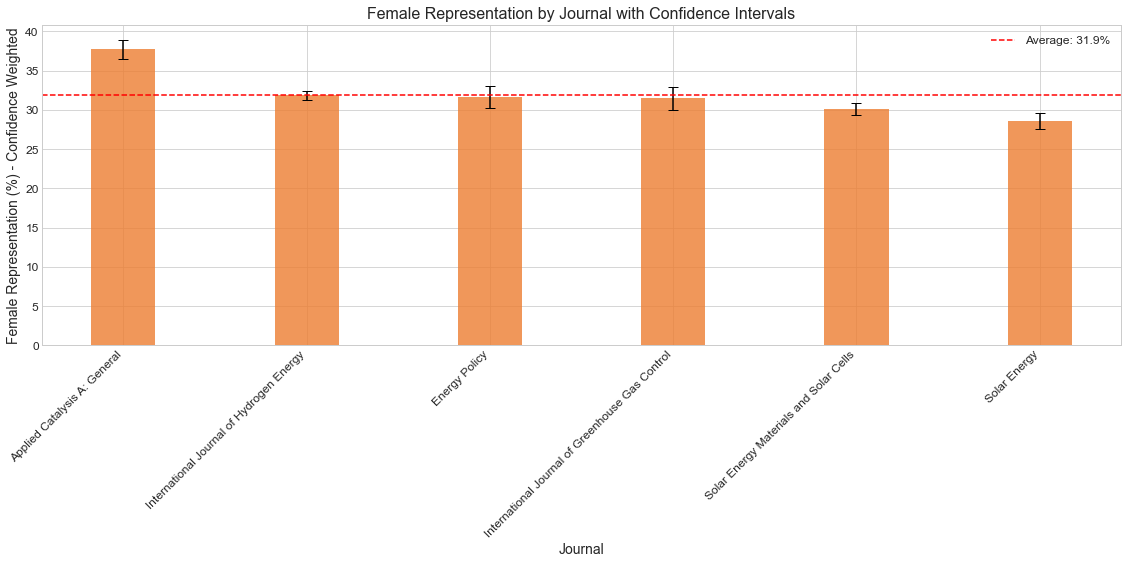


Sensitivity analysis of female representation at different confidence thresholds:
Threshold      All data      ≥ 0.6      ≥ 0.7      ≥ 0.8      ≥ 0.9
Country                                                            
OVERALL       26.301581  24.028004  16.906178   9.230602   5.141164
canada        23.948093  19.779209  12.182410   6.578947   4.196816
france        31.271091  30.142631  24.789748  15.509259   8.820404
germany       21.700810  20.945248  14.409668   6.651719   4.137931
singapore     31.304348  26.558266  14.958449   9.545455  13.207547
south africa  26.296296  20.758929  16.013072   8.920188   6.956522
switzerland   24.615385  23.324022  17.931034  10.267857   7.377049
uk            25.726141  23.431105  15.246430   9.134328   3.210576
us            29.107143  25.929699  16.631726   8.085502   4.447633


<Figure size 1008x576 with 0 Axes>

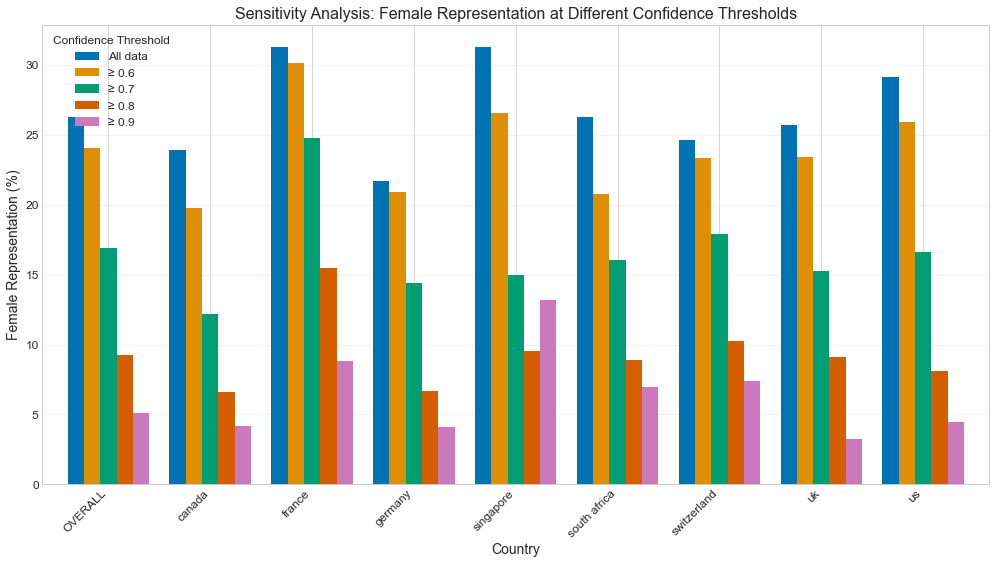


Robust country rankings (accounting for confidence intervals):
          field  median_rank  mean_rank  rank_5th_percentile  \
0     singapore          1.0      1.000                  1.0   
1        france          2.0      2.052                  2.0   
2  south africa          3.0      3.353                  2.0   
3            us          4.0      3.802                  3.0   
4            uk          5.0      5.509                  4.0   
5        canada          6.0      5.966                  5.0   
6   switzerland          7.0      6.318                  4.0   
7       germany          8.0      8.000                  8.0   

   rank_95th_percentile  female_pct   ci_lower   ci_upper  
0                   1.0   38.800482  37.395597  40.205366  
1                   3.0   35.537710  34.618136  36.457285  
2                   5.0   33.478617  31.462730  35.494504  
3                   5.0   32.657281  31.565726  33.748837  
4                   7.0   31.378524  30.501985  32.255062  

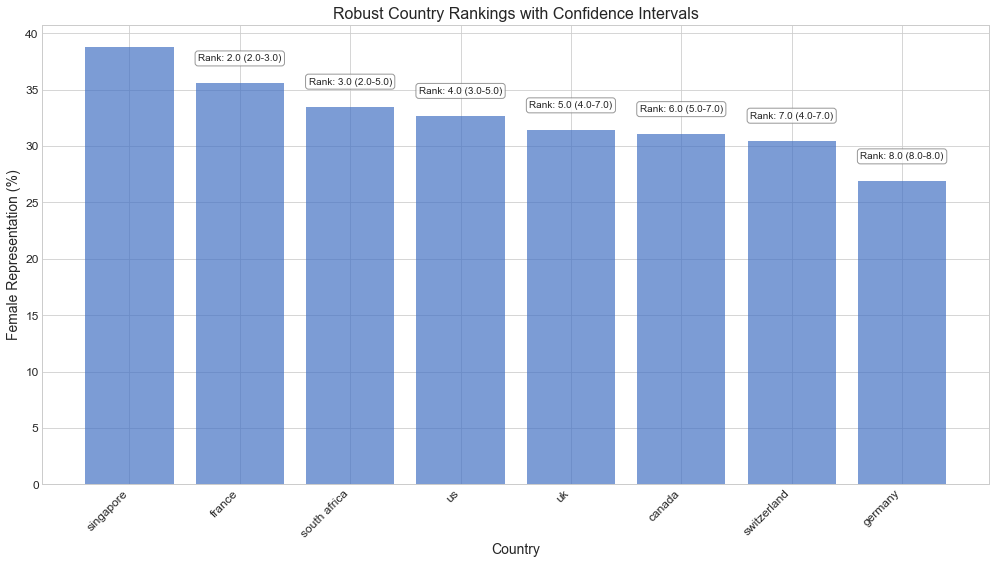

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from matplotlib.colors import LinearSegmentedColormap

# Set visualization styles
plt.style.use('seaborn-whitegrid')
sns.set_palette("colorblind")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# 1. Examine the distribution of gender prediction confidence
print("Summary statistics for gender prediction confidence:")
print(df['Gender likelihood (First Author)'].describe())

# Calculate average confidence by predicted gender
male_confidence = df[df['Gender (First Author)'] == 0]['Gender likelihood (First Author)'].mean()
female_confidence = df[df['Gender (First Author)'] == 1]['Gender likelihood (First Author)'].mean()

print(f"Mean confidence for male first author predictions: {male_confidence:.4f}")
print(f"Mean confidence for female first author predictions: {female_confidence:.4f}")

# 2. Visualize the confidence distribution
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df, 
    x='Gender likelihood (First Author)', 
    hue='Gender (First Author)',
    bins=30, 
    multiple='stack',
    palette=['#4472C4', '#ED7D31']
)
plt.title('Distribution of Gender Prediction Confidence Scores', fontsize=16)
plt.xlabel('Confidence Score', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add threshold lines
thresholds = [0.7, 0.8, 0.9]
colors = ['red', 'orange', 'green']
for threshold, color in zip(thresholds, colors):
    plt.axvline(x=threshold, color=color, linestyle='--', 
               label=f'{threshold} threshold')

plt.legend(title='Gender', labels=['Male', 'Female'] + [f'{t} threshold' for t in thresholds])
plt.tight_layout()
plt.savefig('gender_confidence_distribution.png', dpi=300)
plt.show()

# 3. Define confidence categories for stratified analysis
df['Confidence_Category'] = pd.cut(
    df['Gender likelihood (First Author)'],
    bins=[0, 0.7, 0.9, 1.0],
    labels=['Low (< 0.7)', 'Medium (0.7-0.9)', 'High (≥ 0.9)']
)

print("\nSample distribution by confidence category:")
print(df['Confidence_Category'].value_counts())

# 4. Function to perform analysis at different confidence thresholds
def analyze_with_confidence(data, confidence_threshold=None, field='Country'):
    """
    Perform gender analysis with optional confidence filtering
    
    Parameters:
    data (DataFrame): Input data
    confidence_threshold (float): Optional threshold to filter by confidence
    field (str): Field to group by (Country, Journal, etc.)
    
    Returns:
    DataFrame: Analysis results
    """
    # Filter by confidence if threshold is provided
    if confidence_threshold is not None:
        filtered_data = data[data['Gender likelihood (First Author)'] >= confidence_threshold]
        print(f"Filtered data: {len(filtered_data)} records (removed {len(data)-len(filtered_data)} low-confidence records)")
    else:
        filtered_data = data
        
    # Group by field and calculate gender percentages
    grouped = filtered_data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        female_pct = group['Gender (First Author)'].mean() * 100
        male_pct = 100 - female_pct
        
        # For each gender, calculate stats separately for high and low confidence predictions
        high_conf_female = group[(group['Gender (First Author)'] == 1) & 
                               (group['Gender likelihood (First Author)'] >= 0.9)]
        high_conf_male = group[(group['Gender (First Author)'] == 0) & 
                             (group['Gender likelihood (First Author)'] >= 0.9)]
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,
            'male_pct': male_pct,
            'high_conf_pct': (len(high_conf_female) + len(high_conf_male)) / len(group) * 100,
            'female_high_conf_count': len(high_conf_female),
            'male_high_conf_count': len(high_conf_male)
        })
    
    # Convert to DataFrame and sort
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# 5. Perform analysis at different confidence thresholds
# All data
all_data_analysis = analyze_with_confidence(df, field='Country')
print("\nCountry analysis (all data):")
print(all_data_analysis)

# Only high confidence predictions
high_conf_analysis = analyze_with_confidence(df, confidence_threshold=0.9, field='Country')
print("\nCountry analysis (high confidence only, ≥ 0.9):")
print(high_conf_analysis)

# Medium confidence threshold
medium_conf_analysis = analyze_with_confidence(df, confidence_threshold=0.7, field='Country')
print("\nCountry analysis (medium confidence or higher, ≥ 0.7):")
print(medium_conf_analysis)

# 6. Visualize the impact of confidence thresholds on gender distribution
plt.figure(figsize=(15, 8))

# Create positions for grouped bars
fields = all_data_analysis['field'].tolist()
x = np.arange(len(fields))
width = 0.25

# Plot three bars for each country (all data, medium confidence, high confidence)
plt.bar(x - width, all_data_analysis['female_pct'], width, 
       label='All data', color='#4472C4', alpha=0.7)

# Only include countries that have sufficient data in all three analyses
shared_fields = set(all_data_analysis['field']) & set(medium_conf_analysis['field']) & set(high_conf_analysis['field'])
medium_conf_subset = medium_conf_analysis[medium_conf_analysis['field'].isin(shared_fields)]
high_conf_subset = high_conf_analysis[high_conf_analysis['field'].isin(shared_fields)]

# Match the order of all_data_analysis
medium_conf_subset = medium_conf_subset.set_index('field').reindex(all_data_analysis['field']).reset_index()
high_conf_subset = high_conf_subset.set_index('field').reindex(all_data_analysis['field']).reset_index()

plt.bar(x, medium_conf_subset['female_pct'], width, 
       label='Medium confidence (≥ 0.7)', color='#ED7D31', alpha=0.7)
plt.bar(x + width, high_conf_subset['female_pct'], width, 
       label='High confidence (≥ 0.9)', color='#70AD47', alpha=0.7)

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Impact of Confidence Thresholds on Female Representation by Country', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('gender_confidence_threshold_impact.png', dpi=300)
plt.show()

# 7. Calculate confidence intervals using bootstrapping
def bootstrap_gender_proportion(group, n_bootstrap=1000, confidence=0.95):
    """
    Calculate bootstrap confidence intervals for gender proportion
    
    Parameters:
    group (DataFrame): Data for a specific group
    n_bootstrap (int): Number of bootstrap samples
    confidence (float): Confidence level (e.g., 0.95 for 95% CI)
    
    Returns:
    tuple: (lower bound, upper bound) of confidence interval
    """
    gender_vals = group['Gender (First Author)'].values
    bootstrap_props = []
    
    for _ in range(n_bootstrap):
        # Sample with replacement
        sample = np.random.choice(gender_vals, size=len(gender_vals), replace=True)
        # Calculate proportion female
        prop_female = np.mean(sample)
        bootstrap_props.append(prop_female)
    
    # Calculate confidence interval
    lower = np.percentile(bootstrap_props, (1 - confidence) / 2 * 100)
    upper = np.percentile(bootstrap_props, (1 + confidence) / 2 * 100)
    
    return lower * 100, upper * 100  # Convert to percentage

# Apply bootstrapping to calculate confidence intervals
def analyze_with_bootstrap_ci(data, field='Country', conf_level=0.95):
    """
    Analyze gender distribution with bootstrap confidence intervals
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    conf_level (float): Confidence level for intervals
    
    Returns:
    DataFrame: Results with confidence intervals
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        female_pct = group['Gender (First Author)'].mean() * 100
        
        # Calculate confidence intervals that account for prediction confidence
        # Weight each observation by its confidence
        weighted_female_pct = np.sum(group['Gender (First Author)'] * group['Gender likelihood (First Author)']) / \
                             np.sum(group['Gender likelihood (First Author)']) * 100
        
        # Calculate bootstrap CI
        lower_ci, upper_ci = bootstrap_gender_proportion(group, confidence=conf_level)
        
        # Calculate average prediction confidence
        avg_confidence = group['Gender likelihood (First Author)'].mean()
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,
            'weighted_female_pct': weighted_female_pct,
            'ci_lower': lower_ci,
            'ci_upper': upper_ci,
            'ci_width': upper_ci - lower_ci,
            'avg_confidence': avg_confidence
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# Perform bootstrap analysis
bootstrap_results = analyze_with_bootstrap_ci(df, field='Country')
print("\nGender distribution with bootstrap confidence intervals:")
print(bootstrap_results)

# 8. Visualize results with confidence intervals
plt.figure(figsize=(14, 8))
fields = bootstrap_results['field'].tolist()
female_pcts = bootstrap_results['female_pct'].values
ci_lowers = bootstrap_results['ci_lower'].values
ci_uppers = bootstrap_results['ci_upper'].values
error_bars = [female_pcts - ci_lowers, ci_uppers - female_pcts]

# Plot with error bars
bars = plt.bar(fields, female_pcts, color='#4472C4', alpha=0.8)
plt.errorbar(fields, female_pcts, yerr=error_bars, fmt='none', ecolor='black', capsize=5)

# Add sample size and confidence info
for i, bar in enumerate(bars):
    plt.text(bar.get_x() + bar.get_width()/2, 2, 
             f"n={bootstrap_results['total'].iloc[i]}\nCI: ±{bootstrap_results['ci_width'].iloc[i]:.1f}pp", 
             ha='center', va='bottom', fontsize=9, rotation=0)

plt.axhline(y=bootstrap_results['female_pct'].mean(), color='red', linestyle='--', 
           label=f'Average: {bootstrap_results["female_pct"].mean():.1f}%')
plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Female Representation by Country with 95% Confidence Intervals', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('gender_representation_with_ci.png', dpi=300)
plt.show()

# 9. Weighted analysis incorporating prediction confidence
def weighted_gender_analysis(data, field='Country'):
    """
    Perform gender analysis weighted by prediction confidence
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    
    Returns:
    DataFrame: Weighted analysis results
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        # Standard calculation
        female_pct = group['Gender (First Author)'].mean() * 100
        
        # Confidence-weighted calculation
        # For binary gender (0=Male, 1=Female):
        # - For predicted males (0), confidence score directly represents male probability
        # - For predicted females (1), confidence score represents female probability
        
        # For each row, calculate p(female) based on prediction and confidence
        p_female = np.where(
            group['Gender (First Author)'] == 1,  # If predicted female
            group['Gender likelihood (First Author)'],  # Use confidence as p(female)
            1 - group['Gender likelihood (First Author)']  # Otherwise use 1-confidence as p(female)
        )
        
        weighted_female_pct = np.mean(p_female) * 100
        
        # Calculate weighted variance
        weighted_var = np.var(p_female) * 100**2  # Scale to percentage
        weighted_std = np.sqrt(weighted_var)
        
        # Approximate confidence interval using normal approximation
        # (assumes large enough sample size)
        z = 1.96  # 95% confidence
        margin_of_error = z * weighted_std / np.sqrt(len(group))
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,  # Standard calculation
            'weighted_female_pct': weighted_female_pct,  # Confidence-weighted
            'weighted_ci_lower': max(0, weighted_female_pct - margin_of_error),
            'weighted_ci_upper': min(100, weighted_female_pct + margin_of_error),
            'weighted_margin_of_error': margin_of_error
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('weighted_female_pct', ascending=False)
    
    return result_df

# Perform weighted analysis
weighted_results = weighted_gender_analysis(df, field='Country')
print("\nWeighted gender analysis (incorporating prediction confidence):")
print(weighted_results)

# 10. Compare standard vs weighted analysis
plt.figure(figsize=(14, 8))
fields = weighted_results['field'].tolist()
x = np.arange(len(fields))
width = 0.35

# Plot standard and weighted results side by side
plt.bar(x - width/2, weighted_results['female_pct'], width, 
       label='Standard', color='#4472C4', alpha=0.7)
plt.bar(x + width/2, weighted_results['weighted_female_pct'], width, 
       label='Confidence-weighted', color='#ED7D31', alpha=0.7)

# Add error bars for weighted analysis
plt.errorbar(x + width/2, weighted_results['weighted_female_pct'], 
           yerr=weighted_results['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Standard vs. Confidence-Weighted Female Representation', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('standard_vs_weighted_gender_analysis.png', dpi=300)
plt.show()

# 11. Journal-level analysis with confidence weighting
journal_weighted_results = weighted_gender_analysis(df, field='Publication Title')
print("\nJournal-level weighted gender analysis:")
print(journal_weighted_results)

# 12. Visualization of journal gender distribution with confidence
plt.figure(figsize=(16, 8))
journals = journal_weighted_results['field'].tolist()
x = np.arange(len(journals))
width = 0.35

# Plot with error bars representing confidence
plt.bar(x, journal_weighted_results['weighted_female_pct'], width, 
       color='#ED7D31', alpha=0.8)
plt.errorbar(x, journal_weighted_results['weighted_female_pct'], 
           yerr=journal_weighted_results['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)

# Overall average line
plt.axhline(y=journal_weighted_results['weighted_female_pct'].mean(), 
           color='red', linestyle='--', 
           label=f'Average: {journal_weighted_results["weighted_female_pct"].mean():.1f}%')

plt.xlabel('Journal', fontsize=14)
plt.ylabel('Female Representation (%) - Confidence Weighted', fontsize=14)
plt.title('Female Representation by Journal with Confidence Intervals', fontsize=16)
plt.xticks(x, journals, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('journal_gender_with_confidence.png', dpi=300)
plt.show()

# 13. Sensitivity analysis: Impact of different confidence thresholds
# Define multiple thresholds
thresholds = [None, 0.6, 0.7, 0.8, 0.9]

# Create a results container
sensitivity_results = []

# Perform the analysis for each threshold
for threshold in thresholds:
    # Filter by threshold if specified
    if threshold is None:
        filtered_df = df.copy()
        threshold_label = "All data"
    else:
        filtered_df = df[df['Gender likelihood (First Author)'] >= threshold]
        threshold_label = f"≥ {threshold}"
    
    # Calculate overall female percentage
    female_pct = filtered_df['Gender (First Author)'].mean() * 100
    
    # Calculate country-specific percentages
    for country in df['Country'].unique():
        country_df = filtered_df[filtered_df['Country'] == country]
        if len(country_df) < 30:  # Skip if too few samples
            continue
        
        country_female_pct = country_df['Gender (First Author)'].mean() * 100
        
        sensitivity_results.append({
            'Threshold': threshold_label,
            'Country': country,
            'Female_Pct': country_female_pct,
            'Sample_Size': len(country_df)
        })
    
    # Add overall row
    sensitivity_results.append({
        'Threshold': threshold_label,
        'Country': 'OVERALL',
        'Female_Pct': female_pct,
        'Sample_Size': len(filtered_df)
    })

# Convert to DataFrame
sensitivity_df = pd.DataFrame(sensitivity_results)

# Create pivot table for easier visualization
sensitivity_pivot = sensitivity_df.pivot(
    index='Country', 
    columns='Threshold', 
    values='Female_Pct'
)

print("\nSensitivity analysis of female representation at different confidence thresholds:")
print(sensitivity_pivot)

# Visualization
plt.figure(figsize=(14, 8))
sensitivity_pivot.plot(kind='bar', width=0.8)
plt.title('Sensitivity Analysis: Female Representation at Different Confidence Thresholds', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Confidence Threshold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('sensitivity_analysis_confidence_thresholds.png', dpi=300)
plt.show()

# 14. Calculate robust ranking with confidence intervals
def calculate_robust_ranking(results_df):
    """
    Calculate robust rankings that account for confidence intervals
    """
    # For each field, create 1000 simulated values based on confidence intervals
    np.random.seed(42)  # For reproducibility
    simulations = 1000
    fields = results_df['field'].values
    rankings = {field: [] for field in fields}
    
    for sim in range(simulations):
        # Generate random values within each confidence interval
        simulated_values = []
        for i, field in enumerate(fields):
            lower = results_df['weighted_ci_lower'].iloc[i]
            upper = results_df['weighted_ci_upper'].iloc[i]
            value = np.random.uniform(lower, upper)
            simulated_values.append((field, value))
        
        # Rank the simulated values
        simulated_values.sort(key=lambda x: x[1], reverse=True)
        for rank, (field, _) in enumerate(simulated_values, 1):
            rankings[field].append(rank)
    
    # Calculate the distribution of rankings
    ranking_results = []
    for field in fields:
        ranks = np.array(rankings[field])
        ranking_results.append({
            'field': field,
            'median_rank': np.median(ranks),
            'mean_rank': np.mean(ranks),
            'rank_5th_percentile': np.percentile(ranks, 5),
            'rank_95th_percentile': np.percentile(ranks, 95),
            'female_pct': results_df[results_df['field'] == field]['weighted_female_pct'].iloc[0],
            'ci_lower': results_df[results_df['field'] == field]['weighted_ci_lower'].iloc[0],
            'ci_upper': results_df[results_df['field'] == field]['weighted_ci_upper'].iloc[0]
        })
    
    # Convert to DataFrame and sort by median rank
    ranking_df = pd.DataFrame(ranking_results)
    ranking_df = ranking_df.sort_values('median_rank')
    
    return ranking_df

# Calculate robust country rankings
country_rankings = calculate_robust_ranking(weighted_results)
print("\nRobust country rankings (accounting for confidence intervals):")
print(country_rankings)

# 15. Visualize robust rankings
plt.figure(figsize=(14, 8))
fields = country_rankings['field'].values
x = np.arange(len(fields))

# Plot the median rank
plt.bar(x, country_rankings['female_pct'], color='#4472C4', alpha=0.7)

# Add rank range
for i, field in enumerate(fields):
    plt.annotate(
        f"Rank: {country_rankings['median_rank'].iloc[i]:.1f} ({country_rankings['rank_5th_percentile'].iloc[i]:.1f}-{country_rankings['rank_95th_percentile'].iloc[i]:.1f})",
        (i, country_rankings['female_pct'].iloc[i] + 2),
        ha='center',
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Robust Country Rankings with Confidence Intervals', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.tight_layout()
plt.savefig('robust_gender_rankings.png', dpi=300)
plt.show()

Summary statistics for first author gender prediction confidence:
count    19538.000000
mean         0.794598
std          0.135659
min          0.524439
25%          0.687242
50%          0.816791
75%          0.923686
max          0.986692
Name: Gender likelihood (First Author), dtype: float64

Summary statistics for co-authors gender prediction confidence:
count    19538.000000
mean         0.629133
std          0.052042
min          0.524467
25%          0.597546
50%          0.626809
75%          0.658089
max          0.956599
Name: Mean Author Confidence, dtype: float64
Mean confidence for male first author predictions: 0.8257
Mean confidence for female first author predictions: 0.7068

Co-author gender statistics:
Total co-authors: 83593
Male co-authors: 26767 (32.02%)
Female co-authors: 56826 (67.98%)
Mean confidence for male co-author predictions: 0.6255
Mean confidence for female co-author predictions: 0.6386

Overall author statistics (first authors + co-authors):
Total auth

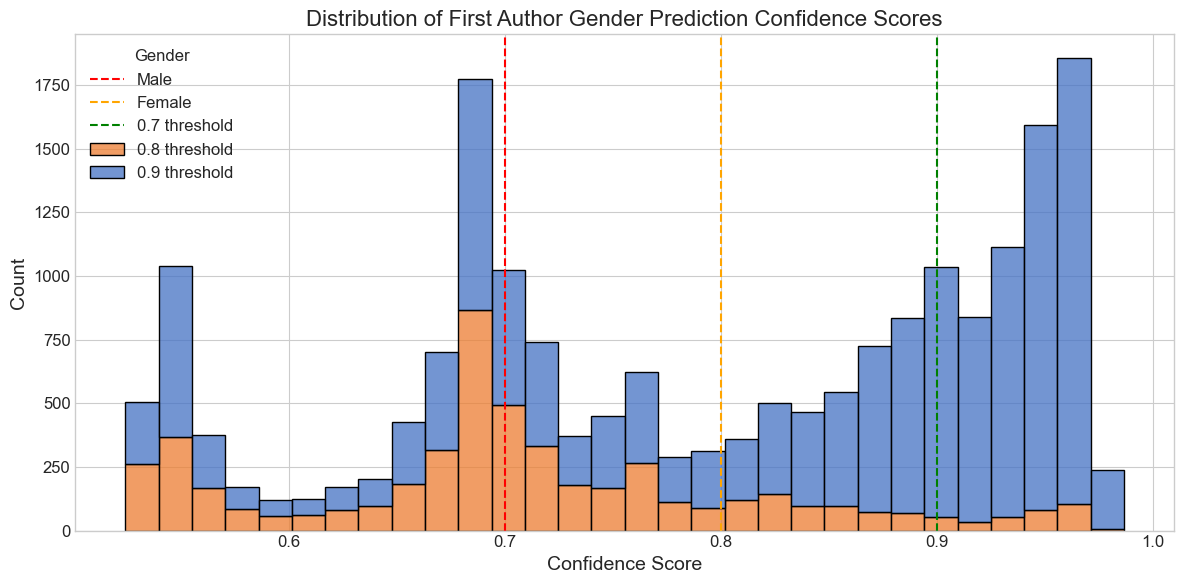

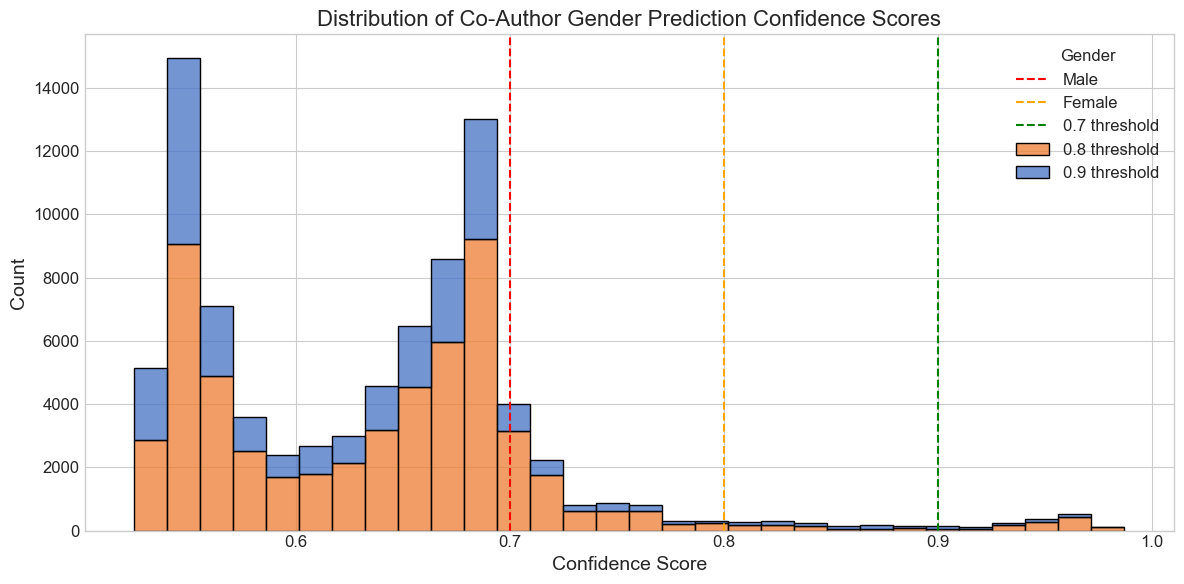

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from matplotlib.colors import LinearSegmentedColormap

# Set visualization styles
plt.style.use('seaborn-whitegrid')
sns.set_palette("colorblind")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# 1. Examine the distribution of gender prediction confidence for both first author and all authors
print("Summary statistics for first author gender prediction confidence:")
print(df['Gender likelihood (First Author)'].describe())

# First, convert string representation to actual lists if needed
if isinstance(df['Gender likelihood (Authors)'].iloc[0], str):
    df['Gender likelihood (Authors)'] = df['Gender likelihood (Authors)'].apply(
        lambda x: eval(x) if isinstance(x, str) else x
    )

if isinstance(df['Gender (Authors)'].iloc[0], str):
    df['Gender (Authors)'] = df['Gender (Authors)'].apply(
        lambda x: eval(x) if isinstance(x, str) else x
    )

# Function to calculate mean confidence for all authors in a paper
def get_mean_author_confidence(row):
    return np.mean(row['Gender likelihood (Authors)'])

# Add mean confidence for all authors
df['Mean Author Confidence'] = df.apply(get_mean_author_confidence, axis=1)

print("\nSummary statistics for co-authors gender prediction confidence:")
print(df['Mean Author Confidence'].describe())

# Calculate average confidence by predicted gender for first author
male_confidence_first = df[df['Gender (First Author)'] == 0]['Gender likelihood (First Author)'].mean()
female_confidence_first = df[df['Gender (First Author)'] == 1]['Gender likelihood (First Author)'].mean()

print(f"Mean confidence for male first author predictions: {male_confidence_first:.4f}")
print(f"Mean confidence for female first author predictions: {female_confidence_first:.4f}")

# Calculate percentage of male and female co-authors overall
def calculate_coauthor_gender_stats():
    all_genders = []
    all_likelihoods = []
    
    for idx, row in df.iterrows():
        genders = row['Gender (Authors)']
        likelihoods = row['Gender likelihood (Authors)']
        
        all_genders.extend(genders)
        all_likelihoods.extend(likelihoods)
    
    total_authors = len(all_genders)
    male_authors = sum(1 for g in all_genders if g == 0)
    female_authors = sum(1 for g in all_genders if g == 1)
    
    male_pct = male_authors / total_authors * 100
    female_pct = female_authors / total_authors * 100
    
    male_conf = np.mean([all_likelihoods[i] for i in range(len(all_genders)) if all_genders[i] == 0])
    female_conf = np.mean([all_likelihoods[i] for i in range(len(all_genders)) if all_genders[i] == 1])
    
    return {
        'total_coauthors': total_authors,
        'male_coauthors': male_authors,
        'female_coauthors': female_authors,
        'male_pct': male_pct,
        'female_pct': female_pct,
        'male_confidence': male_conf,
        'female_confidence': female_conf
    }

# Calculate percentage of male and female authors overall (first author + co-authors)
def calculate_all_authors_gender_stats():
    # Count first authors
    first_authors_count = len(df)
    male_first_authors = sum(df['Gender (First Author)'] == 0)
    female_first_authors = sum(df['Gender (First Author)'] == 1)
    
    # Count co-authors from the lists
    all_coauthor_genders = []
    for _, row in df.iterrows():
        all_coauthor_genders.extend(row['Gender (Authors)'])
    
    coauthors_count = len(all_coauthor_genders)
    male_coauthors = sum(1 for g in all_coauthor_genders if g == 0)
    female_coauthors = sum(1 for g in all_coauthor_genders if g == 1)
    
    # Total counts
    total_authors = first_authors_count + coauthors_count
    male_total = male_first_authors + male_coauthors
    female_total = female_first_authors + female_coauthors
    
    # Percentages
    male_first_pct = male_first_authors / first_authors_count * 100
    female_first_pct = female_first_authors / first_authors_count * 100
    
    male_coauthor_pct = male_coauthors / coauthors_count * 100
    female_coauthor_pct = female_coauthors / coauthors_count * 100
    
    male_total_pct = male_total / total_authors * 100
    female_total_pct = female_total / total_authors * 100
    
    return {
        'first_authors': first_authors_count,
        'coauthors': coauthors_count,
        'total_authors': total_authors,
        'male_first_authors': male_first_authors,
        'female_first_authors': female_first_authors,
        'male_coauthors': male_coauthors,
        'female_coauthors': female_coauthors,
        'male_total': male_total,
        'female_total': female_total,
        'male_first_pct': male_first_pct,
        'female_first_pct': female_first_pct,
        'male_coauthor_pct': male_coauthor_pct,
        'female_coauthor_pct': female_coauthor_pct,
        'male_total_pct': male_total_pct,
        'female_total_pct': female_total_pct
    }

coauthor_stats = calculate_coauthor_gender_stats()
all_authors_stats = calculate_all_authors_gender_stats()

print("\nCo-author gender statistics:")
print(f"Total co-authors: {coauthor_stats['total_coauthors']}")
print(f"Male co-authors: {coauthor_stats['male_coauthors']} ({coauthor_stats['male_pct']:.2f}%)")
print(f"Female co-authors: {coauthor_stats['female_coauthors']} ({coauthor_stats['female_pct']:.2f}%)")
print(f"Mean confidence for male co-author predictions: {coauthor_stats['male_confidence']:.4f}")
print(f"Mean confidence for female co-author predictions: {coauthor_stats['female_confidence']:.4f}")

print("\nOverall author statistics (first authors + co-authors):")
print(f"Total authors: {all_authors_stats['total_authors']}")
print(f"First authors: {all_authors_stats['first_authors']}")
print(f"Co-authors: {all_authors_stats['coauthors']}")
print(f"Male authors total: {all_authors_stats['male_total']} ({all_authors_stats['male_total_pct']:.2f}%)")
print(f"Female authors total: {all_authors_stats['female_total']} ({all_authors_stats['female_total_pct']:.2f}%)")
print(f"First author gender distribution: {all_authors_stats['male_first_pct']:.2f}% male, {all_authors_stats['female_first_pct']:.2f}% female")
print(f"Co-author gender distribution: {all_authors_stats['male_coauthor_pct']:.2f}% male, {all_authors_stats['female_coauthor_pct']:.2f}% female")

# 2. Visualize the confidence distribution for first authors
plt.figure(figsize=(12, 6))
sns.histplot(
    data=df, 
    x='Gender likelihood (First Author)', 
    hue='Gender (First Author)',
    bins=30, 
    multiple='stack',
    palette=['#4472C4', '#ED7D31']
)
plt.title('Distribution of First Author Gender Prediction Confidence Scores', fontsize=16)
plt.xlabel('Confidence Score', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add threshold lines
thresholds = [0.7, 0.8, 0.9]
colors = ['red', 'orange', 'green']
for threshold, color in zip(thresholds, colors):
    plt.axvline(x=threshold, color=color, linestyle='--', 
               label=f'{threshold} threshold')

plt.legend(title='Gender', labels=['Male', 'Female'] + [f'{t} threshold' for t in thresholds])
plt.tight_layout()
plt.savefig('first_author_gender_confidence_distribution.png', dpi=300)
plt.show()

# Visualize confidence distribution for co-authors
plt.figure(figsize=(12, 6))
# Create a flattened list of all co-author confidence scores and genders
coauthors_data = []
for i, row in df.iterrows():
    for gender, conf in zip(row['Gender (Authors)'], row['Gender likelihood (Authors)']):
        coauthors_data.append({'Gender': gender, 'Confidence': conf})

coauthors_df = pd.DataFrame(coauthors_data)

sns.histplot(
    data=coauthors_df, 
    x='Confidence', 
    hue='Gender',
    bins=30, 
    multiple='stack',
    palette=['#4472C4', '#ED7D31']
)
plt.title('Distribution of Co-Author Gender Prediction Confidence Scores', fontsize=16)
plt.xlabel('Confidence Score', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add threshold lines
for threshold, color in zip(thresholds, colors):
    plt.axvline(x=threshold, color=color, linestyle='--', 
               label=f'{threshold} threshold')

plt.legend(title='Gender', labels=['Male', 'Female'] + [f'{t} threshold' for t in thresholds])
plt.tight_layout()
plt.savefig('coauthor_gender_confidence_distribution.png', dpi=300)
plt.show()


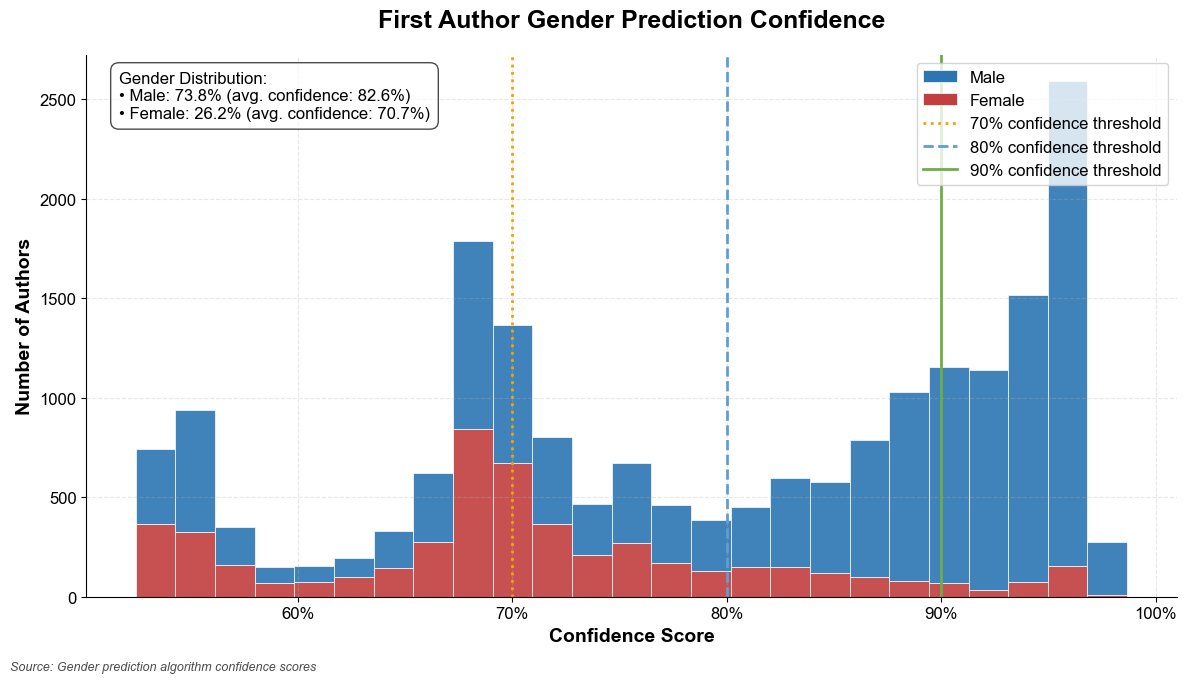

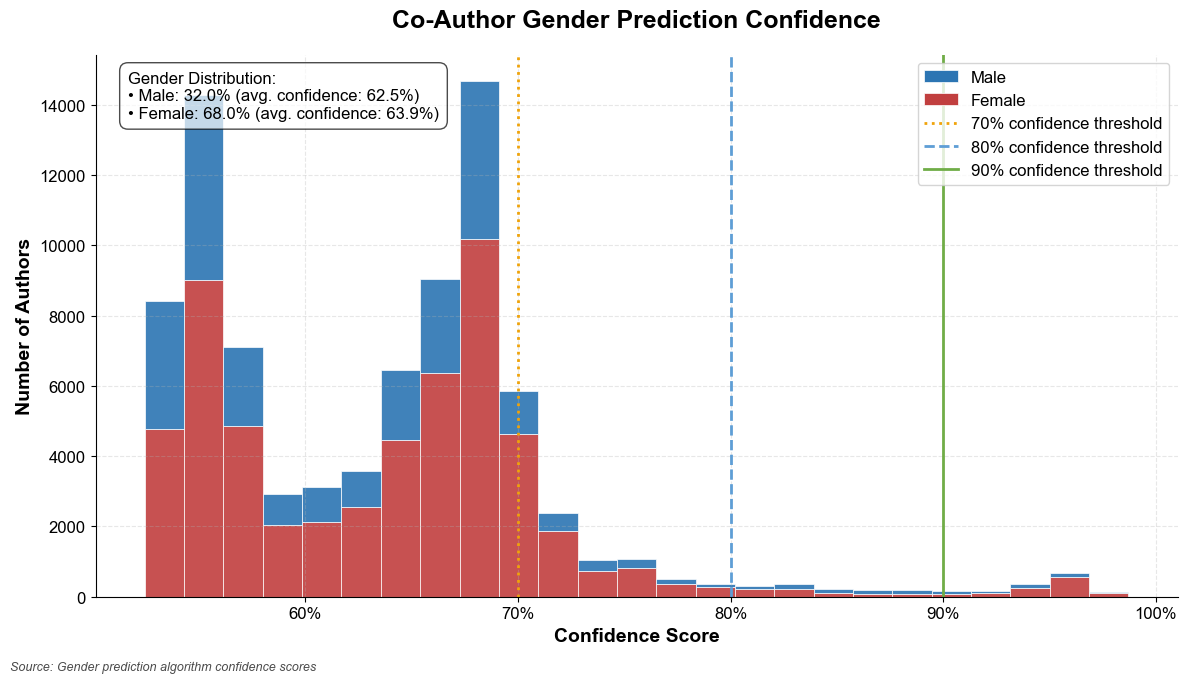

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# Set visualization styles for PowerPoint compatibility
plt.style.use('default')
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12

# Custom colors better suited for presentations
male_color = '#2C75B3'    # Professional blue
female_color = '#C13F3F'  # Rich red

# Function to create a professional, presentation-ready confidence distribution
def create_confidence_viz(first_author=True, transparent=True):
    """Creates a polished, presentation-ready gender confidence distribution chart"""
    
    # Create figure with transparent background if requested
    fig, ax = plt.subplots(figsize=(12, 7), facecolor='none' if transparent else 'white')
    if transparent:
        ax.patch.set_alpha(0)
    
    # Prepare data
    if first_author:
        # For first authors
        title = 'First Author Gender Prediction Confidence'
        data = df
        x_var = 'Gender likelihood (First Author)'
        hue_var = 'Gender (First Author)'
        filename = 'first_author_gender_confidence.png'
        
        # Add statistics to display
        male_pct = sum(data[hue_var] == 0) / len(data) * 100
        female_pct = sum(data[hue_var] == 1) / len(data) * 100
        male_conf = data[data[hue_var] == 0][x_var].mean()
        female_conf = data[data[hue_var] == 1][x_var].mean()
        
    else:
        # For co-authors
        title = 'Co-Author Gender Prediction Confidence'
        filename = 'coauthor_gender_confidence.png'
        
        # Create a flattened dataset of all co-authors
        coauthors_data = []
        for _, row in df.iterrows():
            for gender, conf in zip(row['Gender (Authors)'], row['Gender likelihood (Authors)']):
                coauthors_data.append({'Gender': gender, 'Confidence': conf})
        
        data = pd.DataFrame(coauthors_data)
        x_var = 'Confidence'
        hue_var = 'Gender'
        
        # Calculate statistics
        male_pct = sum(data[hue_var] == 0) / len(data) * 100
        female_pct = sum(data[hue_var] == 1) / len(data) * 100
        male_conf = data[data[hue_var] == 0][x_var].mean()
        female_conf = data[data[hue_var] == 1][x_var].mean()

    # Create the histogram with custom styling
    # Use hue_order to make sure male is 0 and female is 1
    hist = sns.histplot(
        data=data, 
        x=x_var, 
        hue=hue_var,
        hue_order=[0, 1],  # Ensure consistent ordering (male=0, female=1)
        bins=25, 
        multiple='stack',
        palette=[male_color, female_color],
        alpha=0.9,
        edgecolor='white',
        linewidth=0.5,
        ax=ax
    )
    
    # Fix legend - manually create correct legend for stacked histogram
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=male_color, edgecolor='white', linewidth=0.5, label='Male'),
        Patch(facecolor=female_color, edgecolor='white', linewidth=0.5, label='Female')
    ]
    
    # Remove the auto-generated legend
    if ax.get_legend():
        ax.get_legend().remove()
    
    # Enhance visual design
    ax.set_title(title, fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Confidence Score', fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Authors', fontsize=14, fontweight='bold')
    
    # Add threshold lines
    thresholds = [0.7, 0.8, 0.9]
    colors = ['#F0A30A', '#5E9ED6', '#70AD47']  # Gold, light blue, green
    styles = [':', '--', '-']
    
    for threshold, color, style in zip(thresholds, colors, styles):
        line = ax.axvline(x=threshold, color=color, linestyle=style, linewidth=2)
        # Add each threshold line to the legend elements
        legend_elements.append(
            plt.Line2D([0], [0], color=color, linestyle=style, linewidth=2, 
                      label=f'{threshold:.0%} confidence threshold')
        )
    
    # Create a proper legend with correct elements
    ax.legend(
        handles=legend_elements,
        loc='upper right',
        frameon=True,
        fontsize=12
    )
    
    # Add annotations for gender distribution
    textbox = f"Gender Distribution:\n• Male: {male_pct:.1f}% (avg. confidence: {male_conf:.1%})\n• Female: {female_pct:.1f}% (avg. confidence: {female_conf:.1%})"
    
    # Add text box with distribution stats
    props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
    ax.text(0.03, 0.97, textbox, transform=ax.transAxes, fontsize=12,
           verticalalignment='top', bbox=props)
    
    # Format x-axis as percentages
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    
    # Customize grid
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Clean up spines
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    
    # Add subtle footer
    plt.figtext(0.01, 0.01, "Source: Gender prediction algorithm confidence scores", 
               fontsize=9, style='italic', alpha=0.7)
    
    # Tight layout for better space usage
    plt.tight_layout(rect=[0, 0.02, 1, 0.98])
    
    # Save with high resolution, transparent if requested
    plt.savefig(filename, dpi=300, bbox_inches='tight', transparent=transparent)
    
    return fig, ax

# Generate both visualizations
first_author_fig, _ = create_confidence_viz(first_author=True, transparent=True)
coauthor_fig, _ = create_confidence_viz(first_author=False, transparent=True)

# Display the figures
plt.show()


Sample distribution by first author confidence category:
Medium (0.7-0.9)    6977
High (≥ 0.9)        6332
Low (< 0.7)         6229
Name: First_Author_Confidence_Category, dtype: int64

Sample distribution by mean co-author confidence category:
Low (< 0.7)         18437
Medium (0.7-0.9)     1062
High (≥ 0.9)           39
Name: Mean_Coauthor_Confidence_Category, dtype: int64

First author analysis by country (all data):
          field  total  female_pct   male_pct  high_conf_pct  \
3     Singapore    988   31.174089  68.825911      11.133603   
1        France   3591   29.908104  70.091896      26.900585   
7           USA   2240   29.107143  70.892857      31.116071   
5   Switzerland   1007   27.606753  72.393247      32.373386   
4  South Africa    540   26.296296  73.703704      21.296296   
6            UK   3374   25.726141  74.273859      31.387078   
0        Canada   2721   23.300257  76.699743      28.886439   
2       Germany   5077   22.749655  77.250345      44.770534   


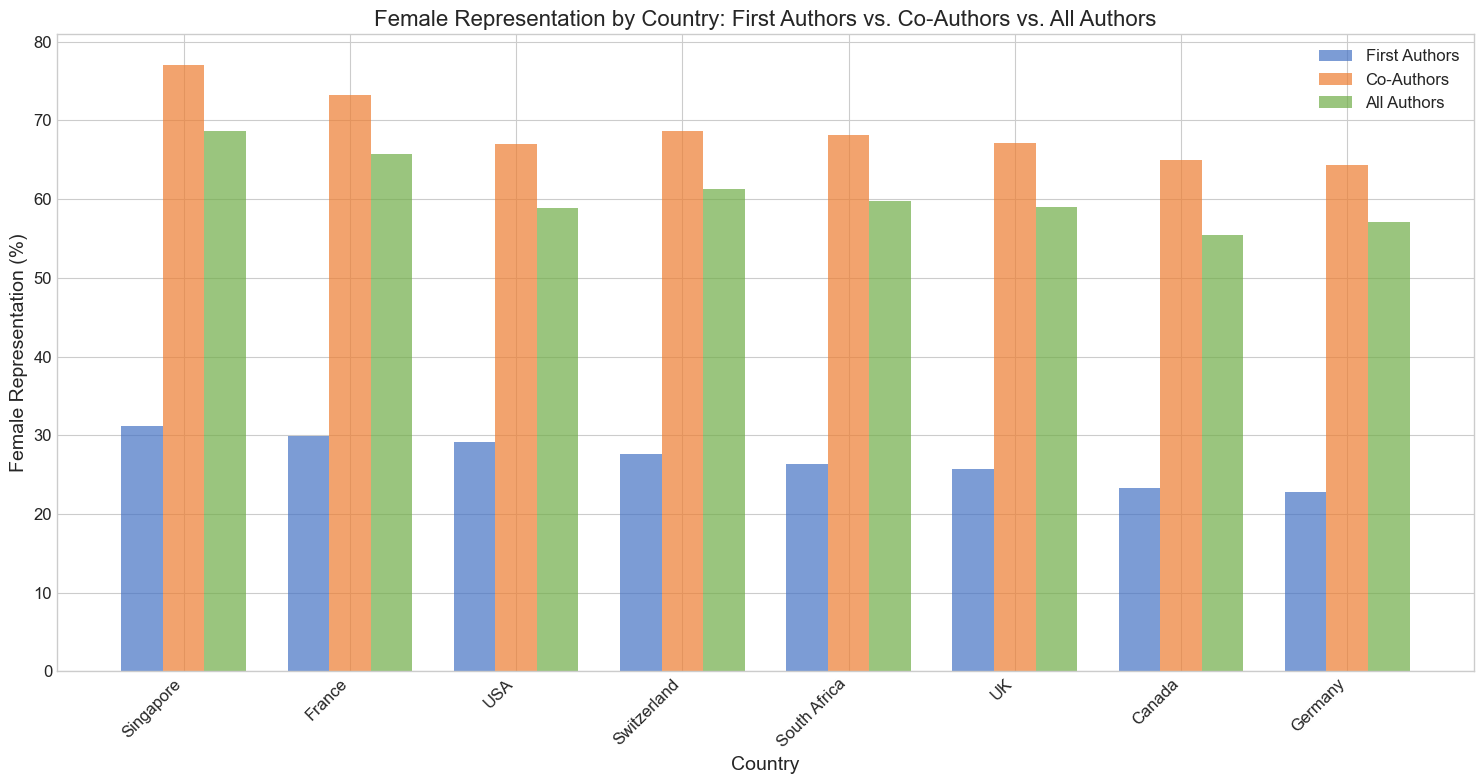


First author gender distribution with bootstrap confidence intervals:
          field  total  female_pct  weighted_female_pct   ci_lower   ci_upper  \
3     Singapore    988   31.174089            28.808270  28.137652  34.213057   
1        France   3591   29.908104            27.587700  28.459343  31.328321   
7           USA   2240   29.107143            25.597493  27.275670  30.982143   
5   Switzerland   1007   27.606753            24.982341  24.627607  30.387289   
4  South Africa    540   26.296296            23.373935  22.592593  30.185185   
6            UK   3374   25.726141            22.751734  24.214582  27.178423   
0        Canada   2721   23.300257            20.312433  21.683205  24.881477   
2       Germany   5077   22.749655            19.932552  21.646642  23.912251   

   ci_width  avg_confidence  
3  6.075405        0.714902  
1  2.868978        0.791333  
7  3.706473        0.783435  
5  5.759682        0.811046  
4  7.592593        0.755370  
6  2.963841        

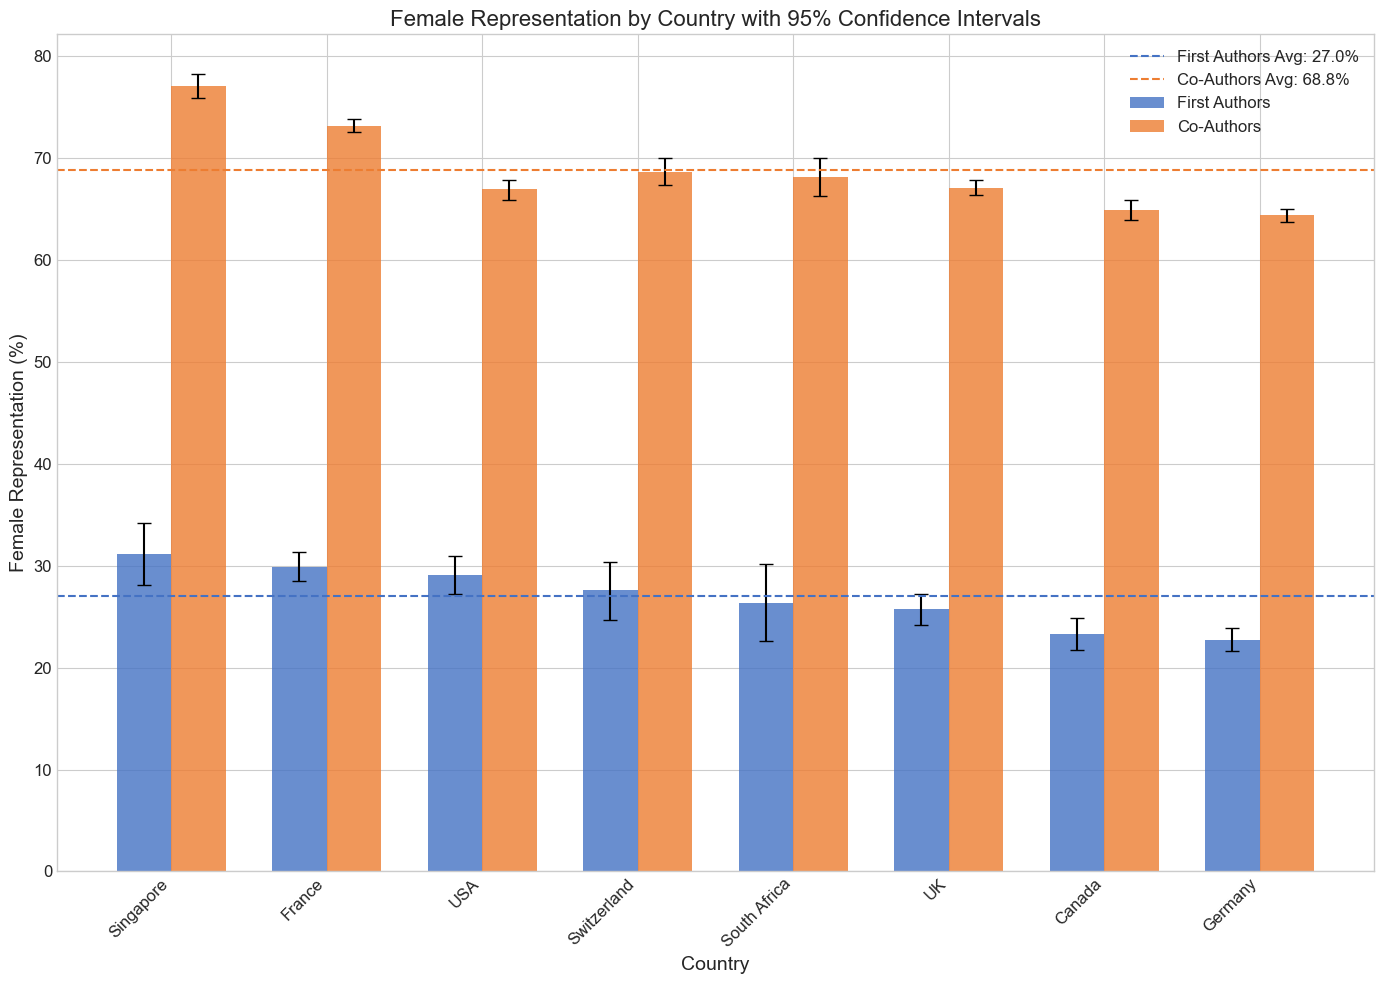


First author weighted gender analysis (incorporating prediction confidence):
          field  total  female_pct  weighted_female_pct  weighted_ci_lower  \
3     Singapore    988   31.174089            38.525890          37.163113   
1        France   3591   29.908104            34.620702          33.707546   
4  South Africa    540   26.296296            33.478617          31.462730   
7           USA   2240   29.107143            32.657281          31.565726   
5   Switzerland   1007   27.606753            31.812292          30.074087   
6            UK   3374   25.726141            31.378524          30.501985   
0        Canada   2721   23.300257            30.429467          29.516305   
2       Germany   5077   22.749655            27.252616          26.503808   

   weighted_ci_upper  weighted_margin_of_error  
3          39.888667                  1.362777  
1          35.533858                  0.913156  
4          35.494504                  2.015887  
7          33.748837   

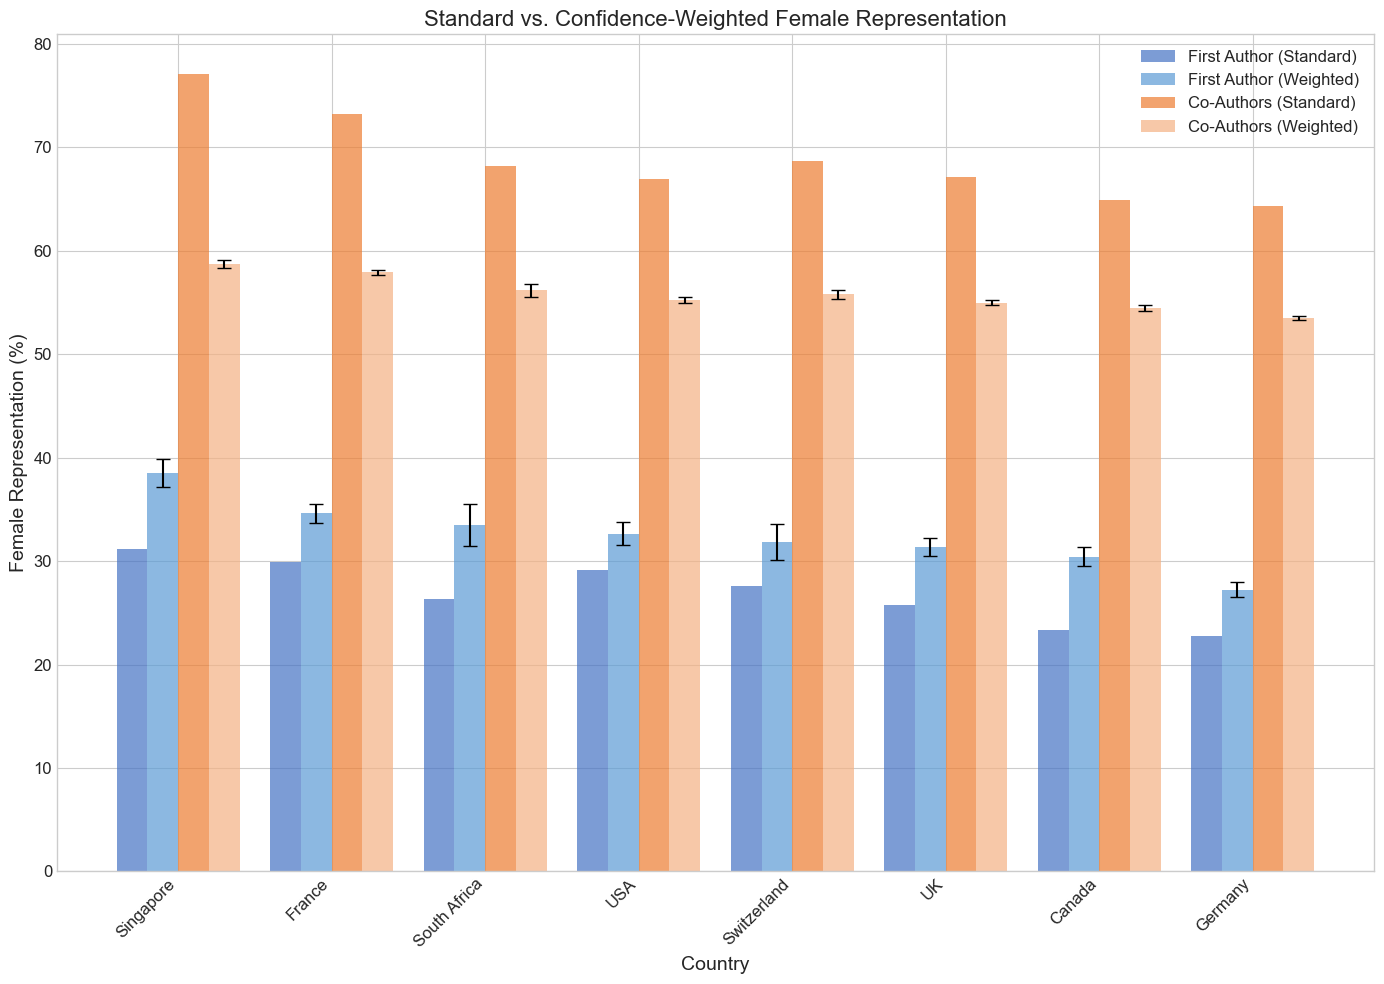


Journal-level first author weighted gender analysis:
                                             field  total  female_pct  \
0                     Applied Catalysis A: General   1424   34.339888   
3         International Journal of Hydrogen Energy   6601   25.450689   
2  International Journal of Greenhouse Gas Control   1390   28.417266   
1                                    Energy Policy   3581   28.567439   
5           Solar Energy Materials and Solar Cells   4369   23.918517   
4                                     Solar Energy   2173   22.043258   

   weighted_female_pct  weighted_ci_lower  weighted_ci_upper  \
0            37.163080          35.702417          38.623743   
3            31.827133          31.208754          32.445511   
2            31.469951          30.010398          32.929503   
1            31.355040          30.422989          32.287090   
5            30.123412          29.351325          30.895500   
4            28.549270          27.523788         

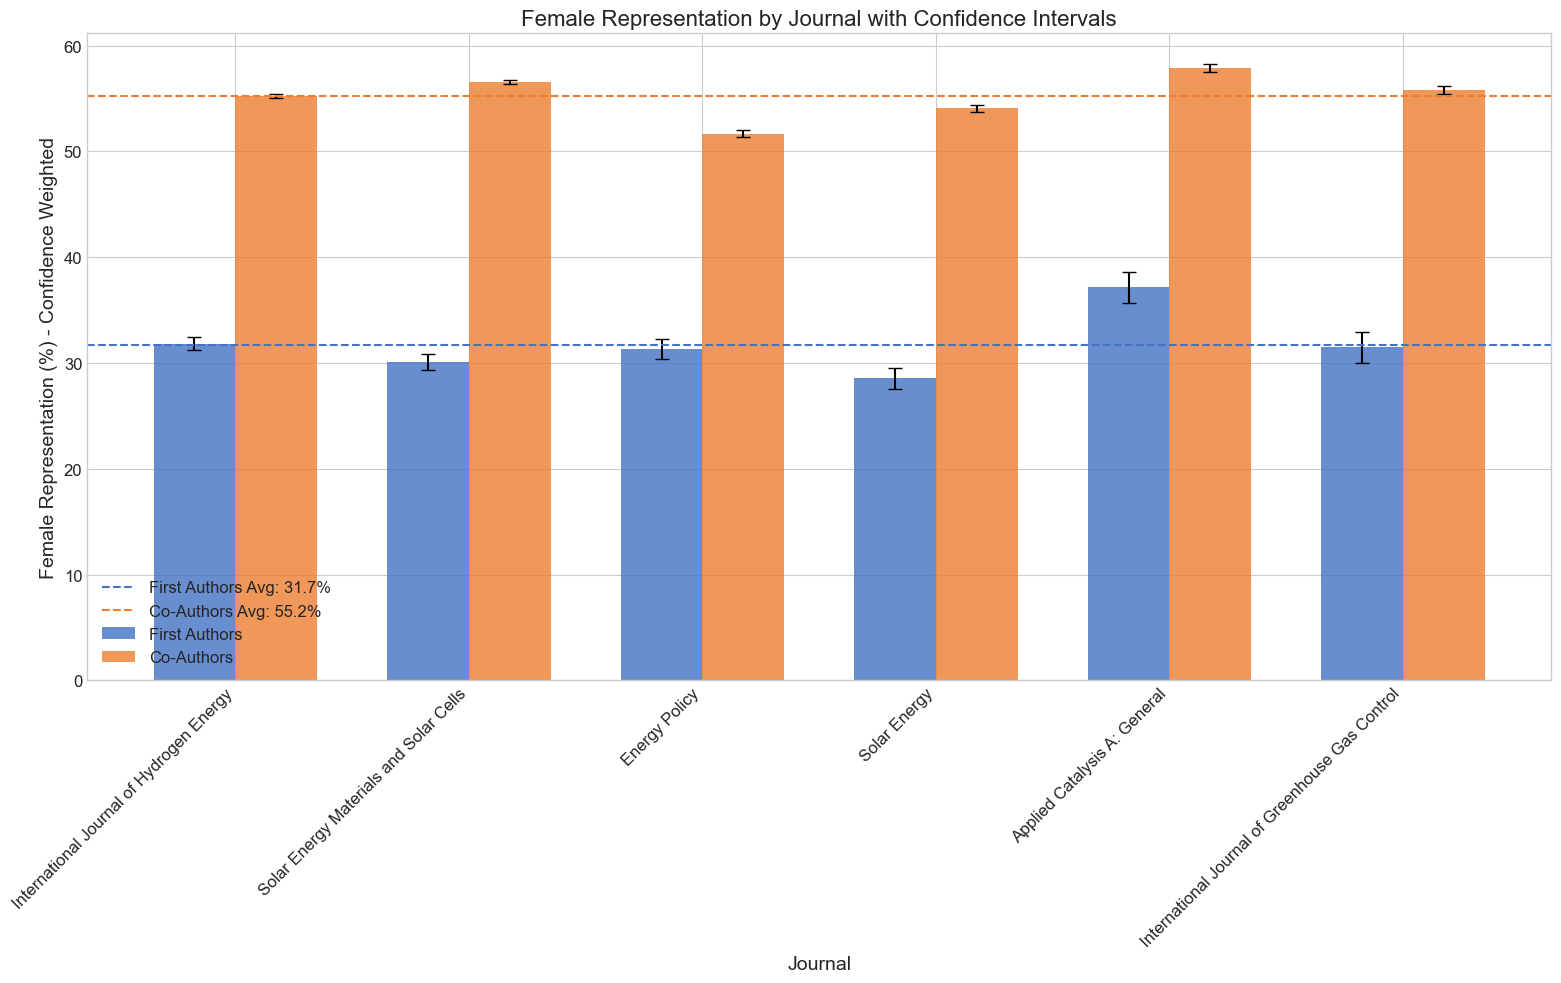


Sensitivity analysis of first author female representation at different confidence thresholds:
Threshold      All data      ≥ 0.6      ≥ 0.7      ≥ 0.8      ≥ 0.9
Country                                                            
Canada        23.300257  19.693095  12.174941   6.146572   3.562341
France        29.908104  28.949829  23.495146  14.964108   7.867495
Germany       22.749655  22.064434  15.589640   7.406279   4.091509
OVERALL       26.159279  24.110490  16.988504   9.285152   4.801011
Singapore     31.174089  26.850690  14.321608   8.230453  10.000000
South Africa  26.296296  20.758929  16.013072   8.920188   6.956522
Switzerland   27.606753  26.508621  20.421607  12.244898   7.055215
UK            25.726141  23.431105  15.246430   9.134328   3.210576
USA           29.107143  25.929699  16.631726   8.085502   4.447633

Sensitivity analysis of co-author female representation at different confidence thresholds:
Threshold      All data      ≥ 0.6      ≥ 0.7      ≥ 0.8      ≥

<Figure size 1400x800 with 0 Axes>

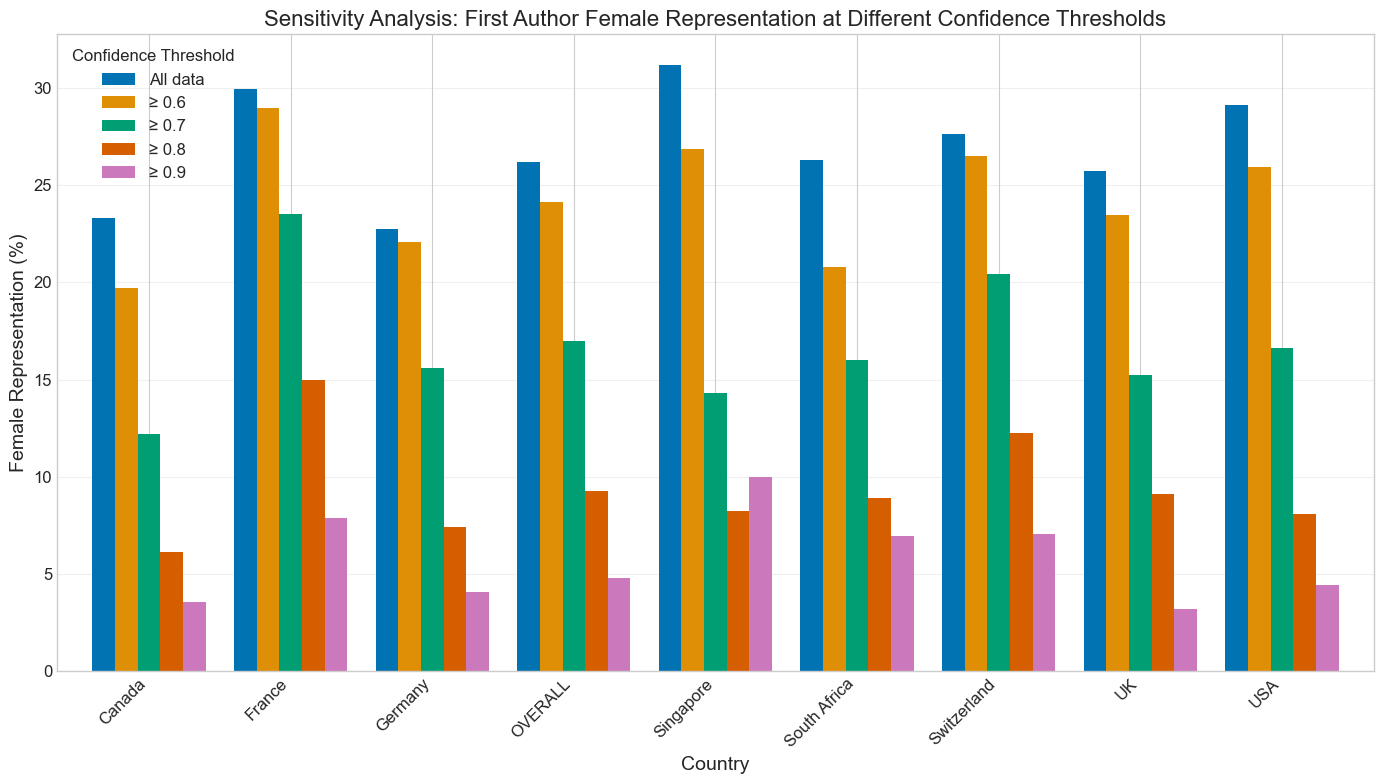

<Figure size 1400x800 with 0 Axes>

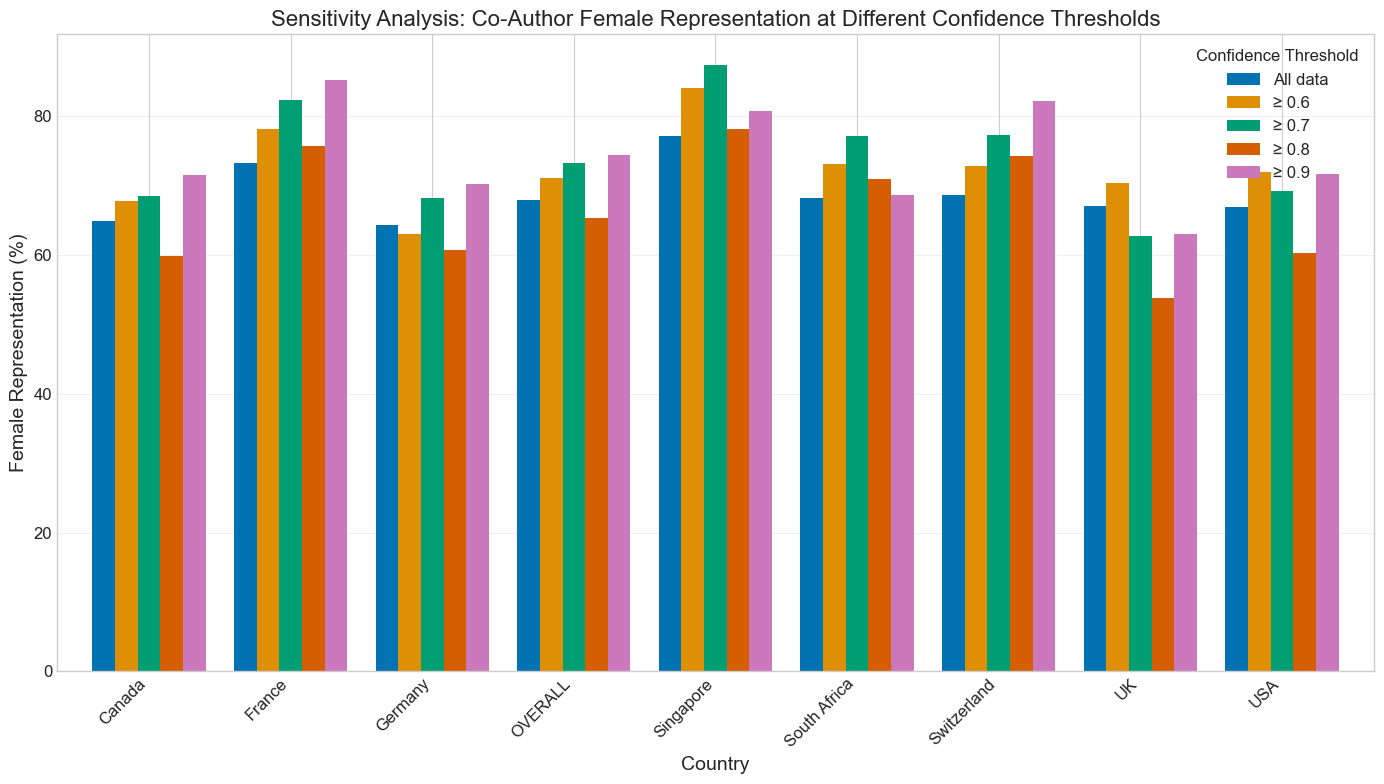


Robust country rankings for first authors (accounting for confidence intervals):
          field  median_rank  mean_rank  rank_5th_percentile  \
0     Singapore          1.0      1.000                  1.0   
1        France          2.0      2.201                  2.0   
2  South Africa          3.0      3.322                  2.0   
3           USA          4.0      4.008                  3.0   
4   Switzerland          5.0      5.114                  3.0   
5            UK          6.0      5.595                  4.0   
6        Canada          7.0      6.760                  6.0   
7       Germany          8.0      8.000                  8.0   

   rank_95th_percentile  female_pct   ci_lower   ci_upper  
0                   1.0   38.525890  37.163113  39.888667  
1                   3.0   34.620702  33.707546  35.533858  
2                   5.0   33.478617  31.462730  35.494504  
3                   5.0   32.657281  31.565726  33.748837  
4                   7.0   31.812292  30.0

<Figure size 1400x1400 with 0 Axes>

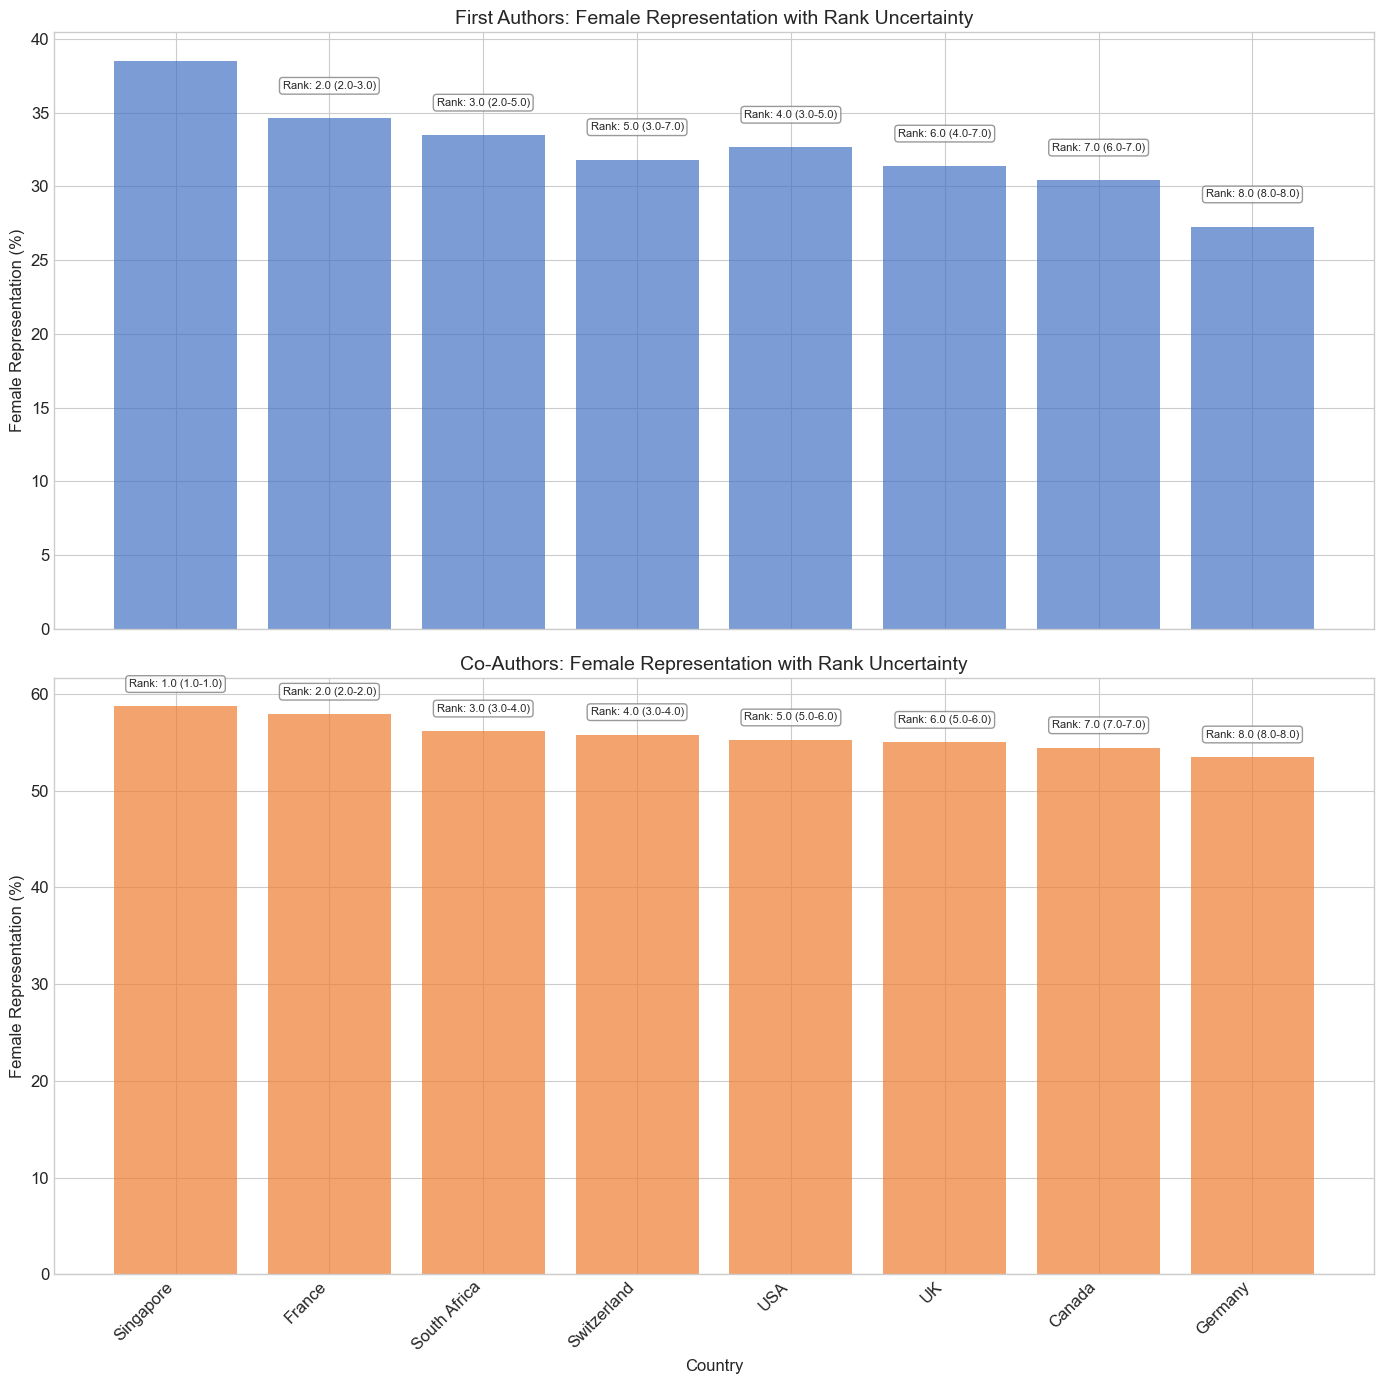


Correlation between first author and co-author female representation: r = 0.9542, p = 0.0002


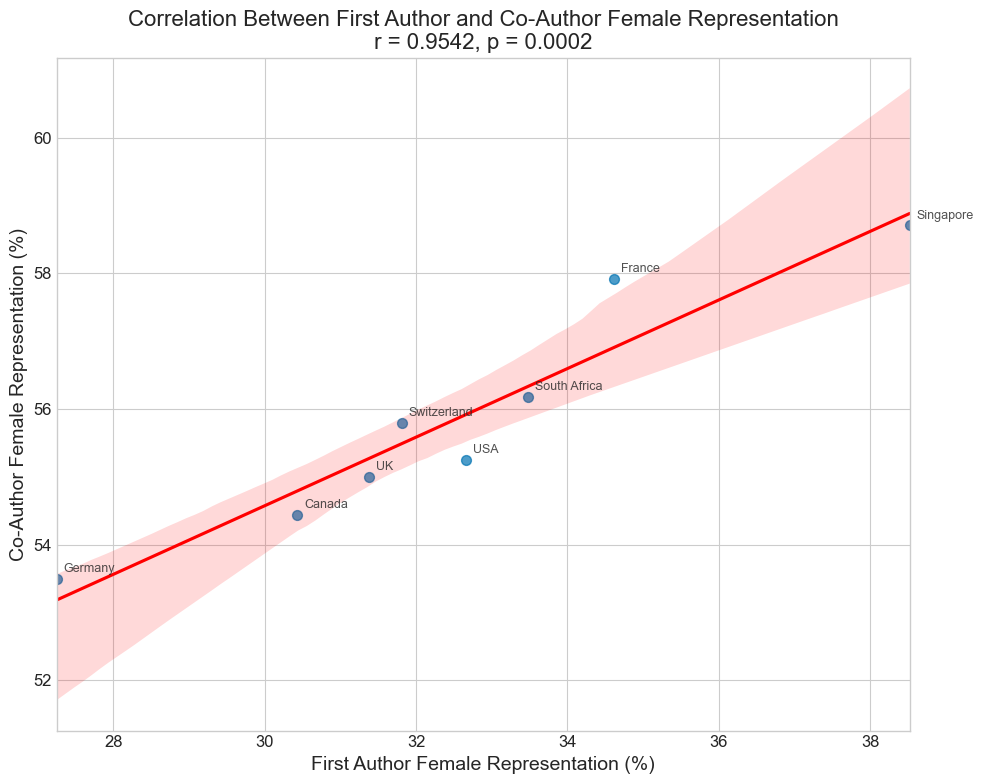


Gender homophily analysis:
Papers with male first authors: 14427
Papers with female first authors: 5111
Average % female co-authors in papers with male first authors: 54.33%
Average % female co-authors in papers with female first authors: 60.12%
Difference: 5.78 percentage points
t-statistic: 10.7433, p-value: 0.0000


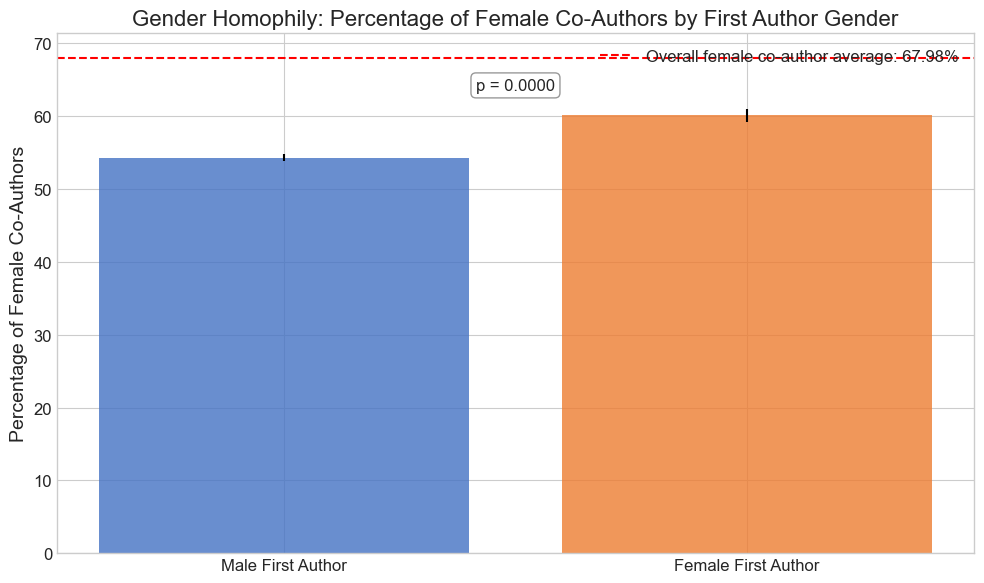

In [81]:
# 3. Define confidence categories for stratified analysis
df['First_Author_Confidence_Category'] = pd.cut(
    df['Gender likelihood (First Author)'],
    bins=[0, 0.7, 0.9, 1.0],
    labels=['Low (< 0.7)', 'Medium (0.7-0.9)', 'High (≥ 0.9)']
)

# Calculate mean confidence for co-authors in each paper
df['Mean_Coauthor_Confidence_Category'] = pd.cut(
    df['Mean Author Confidence'],
    bins=[0, 0.7, 0.9, 1.0],
    labels=['Low (< 0.7)', 'Medium (0.7-0.9)', 'High (≥ 0.9)']
)

print("\nSample distribution by first author confidence category:")
print(df['First_Author_Confidence_Category'].value_counts())

print("\nSample distribution by mean co-author confidence category:")
print(df['Mean_Coauthor_Confidence_Category'].value_counts())

# 4. Function to perform analysis for first authors at different confidence thresholds
def analyze_first_author_with_confidence(data, confidence_threshold=None, field='Country'):
    """
    Perform gender analysis with optional confidence filtering for first authors
    
    Parameters:
    data (DataFrame): Input data
    confidence_threshold (float): Optional threshold to filter by confidence
    field (str): Field to group by (Country, Journal, etc.)
    
    Returns:
    DataFrame: Analysis results
    """
    # Filter by confidence if threshold is provided
    if confidence_threshold is not None:
        filtered_data = data[data['Gender likelihood (First Author)'] >= confidence_threshold]
        print(f"Filtered data: {len(filtered_data)} records (removed {len(data)-len(filtered_data)} low-confidence records)")
    else:
        filtered_data = data
        
    # Group by field and calculate gender percentages
    grouped = filtered_data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        female_pct = group['Gender (First Author)'].mean() * 100
        male_pct = 100 - female_pct
        
        # For each gender, calculate stats separately for high and low confidence predictions
        high_conf_female = group[(group['Gender (First Author)'] == 1) & 
                               (group['Gender likelihood (First Author)'] >= 0.9)]
        high_conf_male = group[(group['Gender (First Author)'] == 0) & 
                             (group['Gender likelihood (First Author)'] >= 0.9)]
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,
            'male_pct': male_pct,
            'high_conf_pct': (len(high_conf_female) + len(high_conf_male)) / len(group) * 100,
            'female_high_conf_count': len(high_conf_female),
            'male_high_conf_count': len(high_conf_male)
        })
    
    # Convert to DataFrame and sort
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# 5. Function to analyze co-authors by field
def analyze_coauthors_by_field(data, field='Country', confidence_threshold=None):
    """
    Analyze co-authors' gender distribution by field
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    confidence_threshold (float): Optional threshold to filter by confidence
    
    Returns:
    DataFrame: Analysis results with gender distribution for co-authors
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
        
        # Process co-authors in this group
        all_genders = []
        all_confidences = []
        
        for _, row in group.iterrows():
            genders = row['Gender (Authors)']
            confidences = row['Gender likelihood (Authors)']
            
            # Apply confidence threshold if specified
            if confidence_threshold is not None:
                # Only include authors with confidence above threshold
                filtered_genders = [genders[i] for i in range(len(genders)) 
                                   if confidences[i] >= confidence_threshold]
                filtered_confidences = [confidences[i] for i in range(len(confidences)) 
                                      if confidences[i] >= confidence_threshold]
                all_genders.extend(filtered_genders)
                all_confidences.extend(filtered_confidences)
            else:
                all_genders.extend(genders)
                all_confidences.extend(confidences)
        
        if len(all_genders) == 0:
            continue  # Skip if no co-authors meet the threshold
            
        female_count = sum(1 for g in all_genders if g == 1)
        total_count = len(all_genders)
        female_pct = female_count / total_count * 100
        male_pct = 100 - female_pct
        
        results.append({
            'field': name,
            'total_papers': len(group),
            'total_coauthors': total_count,
            'female_count': female_count,
            'female_pct': female_pct,
            'male_pct': male_pct,
            'coauthors_per_paper': total_count / len(group),
            'avg_confidence': np.mean(all_confidences) if all_confidences else np.nan
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# 6. Function to analyze all authors (first author + co-authors) by field
def analyze_all_authors_by_field(data, field='Country', first_author_threshold=None, coauthor_threshold=None):
    """
    Analyze all authors' (first author + co-authors) gender distribution by field
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    first_author_threshold (float): Optional confidence threshold for first authors
    coauthor_threshold (float): Optional confidence threshold for co-authors
    
    Returns:
    DataFrame: Analysis results with gender distribution for all authors
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
        
        # Process first authors with confidence threshold
        if first_author_threshold is not None:
            first_authors = group[group['Gender likelihood (First Author)'] >= first_author_threshold]
        else:
            first_authors = group
            
        first_author_count = len(first_authors)
        female_first_count = sum(first_authors['Gender (First Author)'] == 1)
        male_first_count = sum(first_authors['Gender (First Author)'] == 0)
        
        # Process co-authors
        coauthor_genders = []
        coauthor_confidences = []
        
        for _, row in group.iterrows():
            genders = row['Gender (Authors)']
            confidences = row['Gender likelihood (Authors)']
            
            # Apply confidence threshold if specified
            if coauthor_threshold is not None:
                filtered_indices = [i for i, conf in enumerate(confidences) if conf >= coauthor_threshold]
                filtered_genders = [genders[i] for i in filtered_indices]
                filtered_confidences = [confidences[i] for i in filtered_indices]
                coauthor_genders.extend(filtered_genders)
                coauthor_confidences.extend(filtered_confidences)
            else:
                coauthor_genders.extend(genders)
                coauthor_confidences.extend(confidences)
        
        female_coauthor_count = sum(1 for g in coauthor_genders if g == 1)
        male_coauthor_count = sum(1 for g in coauthor_genders if g == 0)
        total_coauthor_count = len(coauthor_genders)
        
        # Total author counts
        total_author_count = first_author_count + total_coauthor_count
        total_female_count = female_first_count + female_coauthor_count
        total_male_count = male_first_count + male_coauthor_count
        
        # Calculate percentages
        if first_author_count > 0:
            female_first_pct = female_first_count / first_author_count * 100
        else:
            female_first_pct = 0
            
        if total_coauthor_count > 0:
            female_coauthor_pct = female_coauthor_count / total_coauthor_count * 100
        else:
            female_coauthor_pct = 0
            
        if total_author_count > 0:
            female_total_pct = total_female_count / total_author_count * 100
        else:
            female_total_pct = 0
        
        results.append({
            'field': name,
            'total_papers': len(group),
            'first_authors': first_author_count,
            'coauthors': total_coauthor_count,
            'total_authors': total_author_count,
            'female_first_count': female_first_count,
            'female_coauthor_count': female_coauthor_count,
            'female_total_count': total_female_count,
            'female_first_pct': female_first_pct,
            'female_coauthor_pct': female_coauthor_pct,
            'female_total_pct': female_total_pct,
            'male_first_pct': 100 - female_first_pct,
            'male_coauthor_pct': 100 - female_coauthor_pct,
            'male_total_pct': 100 - female_total_pct,
            'authors_per_paper': total_author_count / len(group) if len(group) > 0 else 0
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_total_pct', ascending=False)
    
    return result_df

# Analyze first authors, co-authors, and all authors
all_data_first_author = analyze_first_author_with_confidence(df, field='Country')
all_data_coauthors = analyze_coauthors_by_field(df, field='Country')
all_data_all_authors = analyze_all_authors_by_field(df, field='Country')

print("\nFirst author analysis by country (all data):")
print(all_data_first_author)

print("\nCo-authors analysis by country:")
print(all_data_coauthors)

print("\nAll authors (first + co-authors) analysis by country:")
print(all_data_all_authors)

# High confidence threshold analysis
high_conf_first_author = analyze_first_author_with_confidence(df, confidence_threshold=0.9, field='Country')
high_conf_coauthors = analyze_coauthors_by_field(df, field='Country', confidence_threshold=0.9)
high_conf_all_authors = analyze_all_authors_by_field(df, field='Country', 
                                                    first_author_threshold=0.9, 
                                                    coauthor_threshold=0.9)

print("\nFirst author analysis by country (high confidence only, ≥ 0.9):")
print(high_conf_first_author)

print("\nCo-authors analysis by country (high confidence only, ≥ 0.9):")
print(high_conf_coauthors)

print("\nAll authors analysis by country (high confidence only, ≥ 0.9):")
print(high_conf_all_authors)

# 7. Visualize comparison between first author, co-authors, and all authors gender distribution
plt.figure(figsize=(15, 8))

# Create positions for grouped bars
fields = all_data_first_author['field'].tolist()
x = np.arange(len(fields))
width = 0.25

# Ensure all DataFrames have the same countries in the same order
all_data_coauthors_matched = all_data_coauthors.set_index('field').reindex(fields).reset_index()
all_data_all_authors_matched = all_data_all_authors.set_index('field').reindex(fields).reset_index()

# Plot bars for first author, co-authors, and all authors side by side
plt.bar(x - width, all_data_first_author['female_pct'], width, 
       label='First Authors', color='#4472C4', alpha=0.7)
plt.bar(x, all_data_coauthors_matched['female_pct'], width, 
       label='Co-Authors', color='#ED7D31', alpha=0.7)
plt.bar(x + width, all_data_all_authors_matched['female_total_pct'], width, 
       label='All Authors', color='#70AD47', alpha=0.7)

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Female Representation by Country: First Authors vs. Co-Authors vs. All Authors', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('author_type_comparison.png', dpi=300)
plt.show()

# 8. Calculate confidence intervals using bootstrapping for first authors
def bootstrap_gender_proportion(group, gender_column='Gender (First Author)', confidence_column='Gender likelihood (First Author)', n_bootstrap=1000, confidence=0.95):
    """
    Calculate bootstrap confidence intervals for gender proportion
    
    Parameters:
    group (DataFrame): Data for a specific group
    gender_column (str): Column containing gender data
    confidence_column (str): Column containing confidence scores
    n_bootstrap (int): Number of bootstrap samples
    confidence (float): Confidence level (e.g., 0.95 for 95% CI)
    
    Returns:
    tuple: (lower bound, upper bound) of confidence interval
    """
    gender_vals = group[gender_column].values
    bootstrap_props = []
    
    for _ in range(n_bootstrap):
        # Sample with replacement
        sample = np.random.choice(gender_vals, size=len(gender_vals), replace=True)
        # Calculate proportion female
        prop_female = np.mean(sample)
        bootstrap_props.append(prop_female)
    
    # Calculate confidence interval
    lower = np.percentile(bootstrap_props, (1 - confidence) / 2 * 100)
    upper = np.percentile(bootstrap_props, (1 + confidence) / 2 * 100)
    
    return lower * 100, upper * 100  # Convert to percentage

# Function for bootstrapping co-authors
def bootstrap_coauthors_gender_proportion(group, n_bootstrap=1000, confidence=0.95):
    """
    Calculate bootstrap confidence intervals for co-authors gender proportion
    
    Parameters:
    group (DataFrame): Data for a specific group
    n_bootstrap (int): Number of bootstrap samples
    confidence (float): Confidence level (e.g., 0.95 for 95% CI)
    
    Returns:
    tuple: (lower bound, upper bound) of confidence interval
    """
    # Extract all co-authors' genders from the group
    all_genders = []
    for _, row in group.iterrows():
        all_genders.extend(row['Gender (Authors)'])
    
    bootstrap_props = []
    for _ in range(n_bootstrap):
        # Sample with replacement
        sample = np.random.choice(all_genders, size=len(all_genders), replace=True)
        # Calculate proportion female
        prop_female = np.mean(sample)
        bootstrap_props.append(prop_female)
    
    # Calculate confidence interval
    lower = np.percentile(bootstrap_props, (1 - confidence) / 2 * 100)
    upper = np.percentile(bootstrap_props, (1 + confidence) / 2 * 100)
    
    return lower * 100, upper * 100  # Convert to percentage

# Apply bootstrapping to calculate confidence intervals for first authors
def analyze_first_author_with_bootstrap_ci(data, field='Country', conf_level=0.95):
    """
    Analyze first author gender distribution with bootstrap confidence intervals
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    conf_level (float): Confidence level for intervals
    
    Returns:
    DataFrame: Results with confidence intervals
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        female_pct = group['Gender (First Author)'].mean() * 100
        
        # Calculate confidence intervals that account for prediction confidence
        # Weight each observation by its confidence
        weighted_female_pct = np.sum(group['Gender (First Author)'] * group['Gender likelihood (First Author)']) / \
                             np.sum(group['Gender likelihood (First Author)']) * 100
        
        # Calculate bootstrap CI
        lower_ci, upper_ci = bootstrap_gender_proportion(group, confidence=conf_level)
        
        # Calculate average prediction confidence
        avg_confidence = group['Gender likelihood (First Author)'].mean()
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,
            'weighted_female_pct': weighted_female_pct,
            'ci_lower': lower_ci,
            'ci_upper': upper_ci,
            'ci_width': upper_ci - lower_ci,
            'avg_confidence': avg_confidence
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# Apply bootstrapping for co-authors
def analyze_coauthors_with_bootstrap_ci(data, field='Country', conf_level=0.95):
    """
    Analyze co-authors gender distribution with bootstrap confidence intervals
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    conf_level (float): Confidence level for intervals
    
    Returns:
    DataFrame: Results with confidence intervals
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
        
        # Process all co-authors in this group
        all_genders = []
        all_confidences = []
        
        for _, row in group.iterrows():
            all_genders.extend(row['Gender (Authors)'])
            all_confidences.extend(row['Gender likelihood (Authors)'])
        
        if len(all_genders) == 0:
            continue
            
        female_count = sum(1 for g in all_genders if g == 1)
        total_count = len(all_genders)
        female_pct = female_count / total_count * 100
        
        # Calculate bootstrap CI
        lower_ci, upper_ci = bootstrap_coauthors_gender_proportion(group, confidence=conf_level)
        
        # Calculate average prediction confidence
        avg_confidence = np.mean(all_confidences)
        
        results.append({
            'field': name,
            'total_papers': len(group),
            'total_coauthors': total_count,
            'female_pct': female_pct,
            'ci_lower': lower_ci,
            'ci_upper': upper_ci,
            'ci_width': upper_ci - lower_ci,
            'avg_confidence': avg_confidence,
            'coauthors_per_paper': total_count / len(group)
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('female_pct', ascending=False)
    
    return result_df

# Perform bootstrap analysis for first authors and co-authors
first_author_bootstrap = analyze_first_author_with_bootstrap_ci(df, field='Country')
coauthor_bootstrap = analyze_coauthors_with_bootstrap_ci(df, field='Country')

print("\nFirst author gender distribution with bootstrap confidence intervals:")
print(first_author_bootstrap)

print("\nCo-authors gender distribution with bootstrap confidence intervals:")
print(coauthor_bootstrap)

# 9. Visualize results with confidence intervals comparing first author to co-authors
plt.figure(figsize=(14, 10))

# Set up for side-by-side error bars
fields = first_author_bootstrap['field'].tolist()
x = np.arange(len(fields))
width = 0.35

# Ensure coauthor_bootstrap has the same countries in the same order
coauthor_bootstrap_matched = coauthor_bootstrap.set_index('field').reindex(fields).reset_index()

# First authors
plt.bar(x - width/2, first_author_bootstrap['female_pct'], width, color='#4472C4', alpha=0.8, label='First Authors')
plt.errorbar(x - width/2, first_author_bootstrap['female_pct'], 
           yerr=[first_author_bootstrap['female_pct'] - first_author_bootstrap['ci_lower'], 
                 first_author_bootstrap['ci_upper'] - first_author_bootstrap['female_pct']], 
           fmt='none', ecolor='black', capsize=5)

# Co-authors
plt.bar(x + width/2, coauthor_bootstrap_matched['female_pct'], width, color='#ED7D31', alpha=0.8, label='Co-Authors')
plt.errorbar(x + width/2, coauthor_bootstrap_matched['female_pct'], 
           yerr=[coauthor_bootstrap_matched['female_pct'] - coauthor_bootstrap_matched['ci_lower'], 
                 coauthor_bootstrap_matched['ci_upper'] - coauthor_bootstrap_matched['female_pct']], 
           fmt='none', ecolor='black', capsize=5)

# Add reference lines for average values
plt.axhline(y=first_author_bootstrap['female_pct'].mean(), color='#4472C4', linestyle='--', 
           label=f'First Authors Avg: {first_author_bootstrap["female_pct"].mean():.1f}%')
plt.axhline(y=coauthor_bootstrap_matched['female_pct'].mean(), color='#ED7D31', linestyle='--', 
           label=f'Co-Authors Avg: {coauthor_bootstrap_matched["female_pct"].mean():.1f}%')

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Female Representation by Country with 95% Confidence Intervals', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('gender_representation_comparison_with_ci.png', dpi=300)
plt.show()

# 10. Weighted analysis incorporating prediction confidence for first authors
def weighted_gender_analysis(data, field='Country'):
    """
    Perform gender analysis weighted by prediction confidence for first authors
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    
    Returns:
    DataFrame: Weighted analysis results
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
            
        # Standard calculation
        female_pct = group['Gender (First Author)'].mean() * 100
        
        # Confidence-weighted calculation
        # For binary gender (0=Male, 1=Female):
        # - For predicted males (0), confidence score directly represents male probability
        # - For predicted females (1), confidence score represents female probability
        
        # For each row, calculate p(female) based on prediction and confidence
        p_female = np.where(
            group['Gender (First Author)'] == 1,  # If predicted female
            group['Gender likelihood (First Author)'],  # Use confidence as p(female)
            1 - group['Gender likelihood (First Author)']  # Otherwise use 1-confidence as p(female)
        )
        
        weighted_female_pct = np.mean(p_female) * 100
        
        # Calculate weighted variance
        weighted_var = np.var(p_female) * 100**2  # Scale to percentage
        weighted_std = np.sqrt(weighted_var)
        
        # Approximate confidence interval using normal approximation
        # (assumes large enough sample size)
        z = 1.96  # 95% confidence
        margin_of_error = z * weighted_std / np.sqrt(len(group))
        
        results.append({
            'field': name,
            'total': len(group),
            'female_pct': female_pct,  # Standard calculation
            'weighted_female_pct': weighted_female_pct,  # Confidence-weighted
            'weighted_ci_lower': max(0, weighted_female_pct - margin_of_error),
            'weighted_ci_upper': min(100, weighted_female_pct + margin_of_error),
            'weighted_margin_of_error': margin_of_error
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('weighted_female_pct', ascending=False)
    
    return result_df

# Weighted analysis for co-authors
def weighted_coauthor_analysis(data, field='Country'):
    """
    Perform gender analysis weighted by prediction confidence for co-authors
    
    Parameters:
    data (DataFrame): Input data
    field (str): Field to group by
    
    Returns:
    DataFrame: Weighted analysis results
    """
    grouped = data.groupby(field)
    
    results = []
    for name, group in grouped:
        if len(group) < 30:  # Skip groups with small sample size
            continue
        
        # Process all co-authors in this group
        all_genders = []
        all_confidences = []
        female_probs = []
        
        for _, row in group.iterrows():
            genders = row['Gender (Authors)']
            confidences = row['Gender likelihood (Authors)']
            
            all_genders.extend(genders)
            all_confidences.extend(confidences)
            
            # Calculate p(female) for each author
            for i, gender in enumerate(genders):
                if gender == 1:  # Female
                    p_female = confidences[i]
                else:  # Male
                    p_female = 1 - confidences[i]
                female_probs.append(p_female)
        
        if len(all_genders) == 0:
            continue
            
        # Standard calculation
        female_count = sum(1 for g in all_genders if g == 1)
        total_count = len(all_genders)
        female_pct = female_count / total_count * 100
        
        # Weighted calculation
        weighted_female_pct = np.mean(female_probs) * 100
        
        # Calculate weighted variance and confidence interval
        weighted_var = np.var(female_probs) * 100**2
        weighted_std = np.sqrt(weighted_var)
        z = 1.96  # 95% confidence
        margin_of_error = z * weighted_std / np.sqrt(len(female_probs))
        
        results.append({
            'field': name,
            'total_papers': len(group),
            'total_coauthors': total_count,
            'female_pct': female_pct,
            'weighted_female_pct': weighted_female_pct,
            'weighted_ci_lower': max(0, weighted_female_pct - margin_of_error),
            'weighted_ci_upper': min(100, weighted_female_pct + margin_of_error),
            'weighted_margin_of_error': margin_of_error,
            'coauthors_per_paper': total_count / len(group)
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('weighted_female_pct', ascending=False)
    
    return result_df

# Perform weighted analysis
first_author_weighted = weighted_gender_analysis(df, field='Country')
coauthor_weighted = weighted_coauthor_analysis(df, field='Country')

print("\nFirst author weighted gender analysis (incorporating prediction confidence):")
print(first_author_weighted)

print("\nCo-authors weighted gender analysis (incorporating prediction confidence):")
print(coauthor_weighted)

# 11. Compare standard vs weighted analysis for first authors and co-authors
plt.figure(figsize=(14, 10))
fields = first_author_weighted['field'].tolist()
x = np.arange(len(fields))
width = 0.2

# Ensure coauthor_weighted has the same countries in the same order
coauthor_weighted_matched = coauthor_weighted.set_index('field').reindex(fields).reset_index()

# Plot standard and weighted results side by side
plt.bar(x - 1.5*width, first_author_weighted['female_pct'], width, 
       label='First Author (Standard)', color='#4472C4', alpha=0.7)
plt.bar(x - 0.5*width, first_author_weighted['weighted_female_pct'], width, 
       label='First Author (Weighted)', color='#5B9BD5', alpha=0.7)
plt.bar(x + 0.5*width, coauthor_weighted_matched['female_pct'], width, 
       label='Co-Authors (Standard)', color='#ED7D31', alpha=0.7)
plt.bar(x + 1.5*width, coauthor_weighted_matched['weighted_female_pct'], width, 
       label='Co-Authors (Weighted)', color='#F4B183', alpha=0.7)

# Add error bars for weighted analysis
plt.errorbar(x - 0.5*width, first_author_weighted['weighted_female_pct'], 
           yerr=first_author_weighted['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)
plt.errorbar(x + 1.5*width, coauthor_weighted_matched['weighted_female_pct'], 
           yerr=coauthor_weighted_matched['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)

plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.title('Standard vs. Confidence-Weighted Female Representation', fontsize=16)
plt.xticks(x, fields, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('standard_vs_weighted_gender_analysis_comparison.png', dpi=300)
plt.show()

# 12. Journal-level analysis with confidence weighting for both first authors and co-authors
journal_first_author_weighted = weighted_gender_analysis(df, field='Publication Title')
journal_coauthor_weighted = weighted_coauthor_analysis(df, field='Publication Title')

print("\nJournal-level first author weighted gender analysis:")
print(journal_first_author_weighted)

print("\nJournal-level co-author weighted gender analysis:")
print(journal_coauthor_weighted)

# 13. Visualization of journal gender distribution with confidence
plt.figure(figsize=(16, 10))

# Get top 15 journals by paper count for better visualization
top_journals = journal_first_author_weighted.sort_values('total', ascending=False).head(15)
journals = top_journals['field'].tolist()
x = np.arange(len(journals))
width = 0.35

# Ensure we have matching data for co-authors
journal_coauthor_matched = journal_coauthor_weighted.set_index('field').reindex(journals).reset_index()

# Plot first author and co-authors side by side
plt.bar(x - width/2, top_journals['weighted_female_pct'], width, 
       color='#4472C4', alpha=0.8, label='First Authors')
plt.errorbar(x - width/2, top_journals['weighted_female_pct'], 
           yerr=top_journals['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)

plt.bar(x + width/2, journal_coauthor_matched['weighted_female_pct'], width, 
       color='#ED7D31', alpha=0.8, label='Co-Authors')
plt.errorbar(x + width/2, journal_coauthor_matched['weighted_female_pct'], 
           yerr=journal_coauthor_matched['weighted_margin_of_error'], 
           fmt='none', ecolor='black', capsize=5)

# Overall average lines
plt.axhline(y=top_journals['weighted_female_pct'].mean(), 
           color='#4472C4', linestyle='--', 
           label=f'First Authors Avg: {top_journals["weighted_female_pct"].mean():.1f}%')
plt.axhline(y=journal_coauthor_matched['weighted_female_pct'].mean(), 
           color='#ED7D31', linestyle='--', 
           label=f'Co-Authors Avg: {journal_coauthor_matched["weighted_female_pct"].mean():.1f}%')

plt.xlabel('Journal', fontsize=14)
plt.ylabel('Female Representation (%) - Confidence Weighted', fontsize=14)
plt.title('Female Representation by Journal with Confidence Intervals', fontsize=16)
plt.xticks(x, journals, rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('journal_gender_with_confidence_comparison.png', dpi=300)
plt.show()

# 14. Sensitivity analysis: Impact of different confidence thresholds
# Define multiple thresholds
thresholds = [None, 0.6, 0.7, 0.8, 0.9]

# Create results containers
first_author_sensitivity_results = []
coauthor_sensitivity_results = []

# Perform the analysis for each threshold
for threshold in thresholds:
    # For first authors
    if threshold is None:
        filtered_df = df.copy()
        threshold_label = "All data"
    else:
        filtered_df = df[df['Gender likelihood (First Author)'] >= threshold]
        threshold_label = f"≥ {threshold}"
    
    # Calculate overall female percentage for first authors
    first_author_female_pct = filtered_df['Gender (First Author)'].mean() * 100
    
    # Calculate country-specific percentages for first authors
    for country in df['Country'].unique():
        country_df = filtered_df[filtered_df['Country'] == country]
        if len(country_df) < 30:  # Skip if too few samples
            continue
        
        # First author analysis
        country_first_author_female_pct = country_df['Gender (First Author)'].mean() * 100
        
        first_author_sensitivity_results.append({
            'Threshold': threshold_label,
            'Country': country,
            'Female_Pct': country_first_author_female_pct,
            'Sample_Size': len(country_df)
        })
    
    # Add overall first author row
    first_author_sensitivity_results.append({
        'Threshold': threshold_label,
        'Country': 'OVERALL',
        'Female_Pct': first_author_female_pct,
        'Sample_Size': len(filtered_df)
    })
    
    # For co-authors - need to filter each list by confidence
    for country in df['Country'].unique():
        country_df = df[df['Country'] == country]
        if len(country_df) < 30:  # Skip if too few samples
            continue
            
        # Process co-authors with confidence threshold
        coauthor_genders = []
        
        for _, row in country_df.iterrows():
            genders = row['Gender (Authors)']
            confidences = row['Gender likelihood (Authors)']
            
            if threshold is None:
                # Use all co-authors
                coauthor_genders.extend(genders)
            else:
                # Filter by confidence
                coauthor_genders.extend([genders[i] for i in range(len(genders)) 
                                       if confidences[i] >= threshold])
        
        if len(coauthor_genders) > 0:
            country_coauthor_female_pct = sum(1 for g in coauthor_genders if g == 1) / len(coauthor_genders) * 100
            
            coauthor_sensitivity_results.append({
                'Threshold': threshold_label,
                'Country': country,
                'Female_Pct': country_coauthor_female_pct,
                'Sample_Size': len(coauthor_genders)
            })
    
    # Calculate overall co-author percentage
    all_coauthor_genders = []
    for _, row in df.iterrows():
        genders = row['Gender (Authors)']
        confidences = row['Gender likelihood (Authors)']
        
        if threshold is None:
            all_coauthor_genders.extend(genders)
        else:
            all_coauthor_genders.extend([genders[i] for i in range(len(genders)) 
                                       if confidences[i] >= threshold])
    
    if len(all_coauthor_genders) > 0:
        overall_coauthor_female_pct = sum(1 for g in all_coauthor_genders if g == 1) / len(all_coauthor_genders) * 100
        
        coauthor_sensitivity_results.append({
            'Threshold': threshold_label,
            'Country': 'OVERALL',
            'Female_Pct': overall_coauthor_female_pct,
            'Sample_Size': len(all_coauthor_genders)
        })

# Convert to DataFrames
first_author_sensitivity_df = pd.DataFrame(first_author_sensitivity_results)
coauthor_sensitivity_df = pd.DataFrame(coauthor_sensitivity_results)

# Create pivot tables for easier visualization
first_author_sensitivity_pivot = first_author_sensitivity_df.pivot(
    index='Country', 
    columns='Threshold', 
    values='Female_Pct'
)

coauthor_sensitivity_pivot = coauthor_sensitivity_df.pivot(
    index='Country', 
    columns='Threshold', 
    values='Female_Pct'
)

print("\nSensitivity analysis of first author female representation at different confidence thresholds:")
print(first_author_sensitivity_pivot)

print("\nSensitivity analysis of co-author female representation at different confidence thresholds:")
print(coauthor_sensitivity_pivot)

# Visualization for first authors
plt.figure(figsize=(14, 8))
first_author_sensitivity_pivot.plot(kind='bar', width=0.8)
plt.title('Sensitivity Analysis: First Author Female Representation at Different Confidence Thresholds', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Confidence Threshold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('first_author_sensitivity_analysis.png', dpi=300)
plt.show()

# Visualization for co-authors
plt.figure(figsize=(14, 8))
coauthor_sensitivity_pivot.plot(kind='bar', width=0.8)
plt.title('Sensitivity Analysis: Co-Author Female Representation at Different Confidence Thresholds', fontsize=16)
plt.xlabel('Country', fontsize=14)
plt.ylabel('Female Representation (%)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Confidence Threshold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('coauthor_sensitivity_analysis.png', dpi=300)
plt.show()

# 15. Calculate robust ranking with confidence intervals for first authors and co-authors
def calculate_robust_ranking(results_df):
    """
    Calculate robust rankings that account for confidence intervals
    """
    # For each field, create 1000 simulated values based on confidence intervals
    np.random.seed(42)  # For reproducibility
    simulations = 1000
    fields = results_df['field'].values
    rankings = {field: [] for field in fields}
    
    for sim in range(simulations):
        # Generate random values within each confidence interval
        simulated_values = []
        for i, field in enumerate(fields):
            lower = results_df['weighted_ci_lower'].iloc[i]
            upper = results_df['weighted_ci_upper'].iloc[i]
            value = np.random.uniform(lower, upper)
            simulated_values.append((field, value))
        
        # Rank the simulated values
        simulated_values.sort(key=lambda x: x[1], reverse=True)
        for rank, (field, _) in enumerate(simulated_values, 1):
            rankings[field].append(rank)
    
    # Calculate the distribution of rankings
    ranking_results = []
    for field in fields:
        ranks = np.array(rankings[field])
        ranking_results.append({
            'field': field,
            'median_rank': np.median(ranks),
            'mean_rank': np.mean(ranks),
            'rank_5th_percentile': np.percentile(ranks, 5),
            'rank_95th_percentile': np.percentile(ranks, 95),
            'female_pct': results_df[results_df['field'] == field]['weighted_female_pct'].iloc[0],
            'ci_lower': results_df[results_df['field'] == field]['weighted_ci_lower'].iloc[0],
            'ci_upper': results_df[results_df['field'] == field]['weighted_ci_upper'].iloc[0]
        })
    
    # Convert to DataFrame and sort by median rank
    ranking_df = pd.DataFrame(ranking_results)
    ranking_df = ranking_df.sort_values('median_rank')
    
    return ranking_df

# Calculate robust country rankings for first authors and co-authors
first_author_rankings = calculate_robust_ranking(first_author_weighted)
coauthor_rankings = calculate_robust_ranking(coauthor_weighted)

print("\nRobust country rankings for first authors (accounting for confidence intervals):")
print(first_author_rankings)

print("\nRobust country rankings for co-authors (accounting for confidence intervals):")
print(coauthor_rankings)

# 16. Visualize robust rankings for both first authors and co-authors
plt.figure(figsize=(14, 14))

# Create a side-by-side comparison of first author and co-author rankings
fields_first = first_author_rankings['field'].values
fields_coauthor = coauthor_rankings['field'].values

# Create a set of all unique fields
all_fields = list(set(fields_first) | set(fields_coauthor))
all_fields.sort()

# Create DataFrames with all fields
first_author_complete = pd.DataFrame({'field': all_fields})
coauthor_complete = pd.DataFrame({'field': all_fields})

# Merge with ranking data
first_author_complete = first_author_complete.merge(first_author_rankings, on='field', how='left')
coauthor_complete = coauthor_complete.merge(coauthor_rankings, on='field', how='left')

# Sort by average rank across both analyses
avg_ranks = []
for field in all_fields:
    first_rank = first_author_complete[first_author_complete['field'] == field]['median_rank'].values
    coauthor_rank = coauthor_complete[coauthor_complete['field'] == field]['median_rank'].values
    
    first_rank = first_rank[0] if len(first_rank) > 0 else np.nan
    coauthor_rank = coauthor_rank[0] if len(coauthor_rank) > 0 else np.nan
    
    avg_rank = np.nanmean([first_rank, coauthor_rank])
    avg_ranks.append((field, avg_rank))

# Sort fields by average rank
avg_ranks.sort(key=lambda x: x[1])
sorted_fields = [x[0] for x in avg_ranks]

# Reindex DataFrames by sorted fields
first_author_complete = first_author_complete.set_index('field').reindex(sorted_fields).reset_index()
coauthor_complete = coauthor_complete.set_index('field').reindex(sorted_fields).reset_index()

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 14), sharex=True)

# First authors plot
bars1 = ax1.bar(np.arange(len(sorted_fields)), first_author_complete['female_pct'], color='#4472C4', alpha=0.7)
ax1.set_ylabel('Female Representation (%)', fontsize=12)
ax1.set_title('First Authors: Female Representation with Rank Uncertainty', fontsize=14)

# Add rank annotations
for i, bar in enumerate(bars1):
    if np.isnan(first_author_complete['median_rank'].iloc[i]):
        continue
        
    ax1.annotate(
        f"Rank: {first_author_complete['median_rank'].iloc[i]:.1f} ({first_author_complete['rank_5th_percentile'].iloc[i]:.1f}-{first_author_complete['rank_95th_percentile'].iloc[i]:.1f})",
        (i, first_author_complete['female_pct'].iloc[i] + 2),
        ha='center',
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

# Co-authors plot
bars2 = ax2.bar(np.arange(len(sorted_fields)), coauthor_complete['female_pct'], color='#ED7D31', alpha=0.7)
ax2.set_xlabel('Country', fontsize=12)
ax2.set_ylabel('Female Representation (%)', fontsize=12)
ax2.set_title('Co-Authors: Female Representation with Rank Uncertainty', fontsize=14)
ax2.set_xticks(np.arange(len(sorted_fields)))
ax2.set_xticklabels(sorted_fields, rotation=45, ha='right')

# Add rank annotations
for i, bar in enumerate(bars2):
    if np.isnan(coauthor_complete['median_rank'].iloc[i]):
        continue
        
    ax2.annotate(
        f"Rank: {coauthor_complete['median_rank'].iloc[i]:.1f} ({coauthor_complete['rank_5th_percentile'].iloc[i]:.1f}-{coauthor_complete['rank_95th_percentile'].iloc[i]:.1f})",
        (i, coauthor_complete['female_pct'].iloc[i] + 2),
        ha='center',
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

plt.tight_layout()
plt.savefig('robust_gender_rankings_comparison.png', dpi=300)
plt.show()

# 17. Correlation between first author and co-author gender representation
# Create a DataFrame with both first author and co-author percentages
correlation_df = pd.merge(
    first_author_weighted[['field', 'weighted_female_pct']].rename(columns={'weighted_female_pct': 'First_Author_Female_Pct'}),
    coauthor_weighted[['field', 'weighted_female_pct']].rename(columns={'weighted_female_pct': 'Coauthor_Female_Pct'}),
    on='field'
)

# Calculate correlation
corr, p_value = stats.pearsonr(correlation_df['First_Author_Female_Pct'], correlation_df['Coauthor_Female_Pct'])
print(f"\nCorrelation between first author and co-author female representation: r = {corr:.4f}, p = {p_value:.4f}")

# Visualize correlation
plt.figure(figsize=(10, 8))
sns.regplot(x='First_Author_Female_Pct', y='Coauthor_Female_Pct', data=correlation_df, 
           scatter_kws={'alpha':0.7, 's':50}, line_kws={'color':'red'})

# Add country labels
for i, row in correlation_df.iterrows():
    plt.annotate(row['field'], 
                (row['First_Author_Female_Pct'], row['Coauthor_Female_Pct']),
                xytext=(5, 5), textcoords='offset points',
                fontsize=9, alpha=0.8)

plt.title(f'Correlation Between First Author and Co-Author Female Representation\nr = {corr:.4f}, p = {p_value:.4f}', fontsize=16)
plt.xlabel('First Author Female Representation (%)', fontsize=14)
plt.ylabel('Co-Author Female Representation (%)', fontsize=14)
plt.tight_layout()
plt.savefig('first_author_coauthor_correlation.png', dpi=300)
plt.show()

# 18. Analysis of gender homophily: Do female first authors tend to have more female co-authors?
def analyze_gender_homophily():
    """
    Analyze whether first authors tend to work with co-authors of the same gender
    """
    # Group papers by first author gender
    male_first_author_papers = df[df['Gender (First Author)'] == 0]
    female_first_author_papers = df[df['Gender (First Author)'] == 1]
    
    # Calculate percentage of female co-authors for each group
    male_first_female_coauthors = []
    female_first_female_coauthors = []
    
    # For papers with male first authors
    for _, row in male_first_author_papers.iterrows():
        coauthor_genders = row['Gender (Authors)']
        if len(coauthor_genders) > 0:
            female_pct = sum(1 for g in coauthor_genders if g == 1) / len(coauthor_genders) * 100
            male_first_female_coauthors.append(female_pct)
    
    # For papers with female first authors
    for _, row in female_first_author_papers.iterrows():
        coauthor_genders = row['Gender (Authors)']
        if len(coauthor_genders) > 0:
            female_pct = sum(1 for g in coauthor_genders if g == 1) / len(coauthor_genders) * 100
            female_first_female_coauthors.append(female_pct)
    
    # Calculate average percentage of female co-authors for each group
    male_first_avg_female_coauthors = np.mean(male_first_female_coauthors)
    female_first_avg_female_coauthors = np.mean(female_first_female_coauthors)
    
    # Calculate 95% confidence intervals
    male_first_ci = stats.norm.interval(0.95, loc=male_first_avg_female_coauthors, 
                                      scale=stats.sem(male_first_female_coauthors))
    female_first_ci = stats.norm.interval(0.95, loc=female_first_avg_female_coauthors, 
                                        scale=stats.sem(female_first_female_coauthors))
    
    # Statistical test
    t_stat, p_val = stats.ttest_ind(female_first_female_coauthors, male_first_female_coauthors)
    
    return {
        'male_first_author_count': len(male_first_author_papers),
        'female_first_author_count': len(female_first_author_papers),
        'male_first_avg_female_coauthors': male_first_avg_female_coauthors,
        'female_first_avg_female_coauthors': female_first_avg_female_coauthors,
        'male_first_ci': male_first_ci,
        'female_first_ci': female_first_ci,
        't_stat': t_stat,
        'p_value': p_val
    }

homophily_results = analyze_gender_homophily()

print("\nGender homophily analysis:")
print(f"Papers with male first authors: {homophily_results['male_first_author_count']}")
print(f"Papers with female first authors: {homophily_results['female_first_author_count']}")
print(f"Average % female co-authors in papers with male first authors: {homophily_results['male_first_avg_female_coauthors']:.2f}%")
print(f"Average % female co-authors in papers with female first authors: {homophily_results['female_first_avg_female_coauthors']:.2f}%")
print(f"Difference: {homophily_results['female_first_avg_female_coauthors'] - homophily_results['male_first_avg_female_coauthors']:.2f} percentage points")
print(f"t-statistic: {homophily_results['t_stat']:.4f}, p-value: {homophily_results['p_value']:.4f}")

# Visualize homophily
plt.figure(figsize=(10, 6))
labels = ['Male First Author', 'Female First Author']
values = [homophily_results['male_first_avg_female_coauthors'], 
          homophily_results['female_first_avg_female_coauthors']]

# Calculate error bar heights
male_ci = homophily_results['male_first_ci']
female_ci = homophily_results['female_first_ci']
errors = [[values[0] - male_ci[0], values[1] - female_ci[0]], 
          [male_ci[1] - values[0], female_ci[1] - values[1]]]

plt.bar(labels, values, yerr=errors, color=['#4472C4', '#ED7D31'], alpha=0.8)
plt.ylabel('Percentage of Female Co-Authors', fontsize=14)
plt.title('Gender Homophily: Percentage of Female Co-Authors by First Author Gender', fontsize=16)
plt.axhline(y=coauthor_stats['female_pct'], color='red', linestyle='--', 
           label=f'Overall female co-author average: {coauthor_stats["female_pct"]:.2f}%')
plt.legend()

# Add p-value annotation
plt.annotate(f"p = {homophily_results['p_value']:.4f}", xy=(0.5, 0.9), xycoords='axes fraction', 
            ha='center', va='center', fontsize=12, 
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

plt.tight_layout()
plt.savefig('gender_homophily_analysis.png', dpi=300)
plt.show()

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
plt.style.use('seaborn-whitegrid')
sns.set_palette("colorblind")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# --- 1. Extract all authors' gender data ---
def extract_all_authors_gender(row):
    """Extract gender info for all authors in a paper with order preserved."""
    authors_gender = []

    # First author
    fa_gender = row.get('Gender (First Author)', None)
    fa_likelihood = row.get('Gender likelihood (First Author)', None)
    if pd.notna(fa_gender):
        authors_gender.append((0, fa_gender, fa_likelihood))

    # Other authors
    other_genders = row.get('Gender (Authors)', [])
    other_likelihoods = row.get('Gender likelihood (Authors)', [])

    # Convert from string to list if needed
    if isinstance(other_genders, str):
        try:
            other_genders = eval(other_genders)
        except:
            other_genders = []

    if isinstance(other_likelihoods, str):
        try:
            other_likelihoods = eval(other_likelihoods)
        except:
            other_likelihoods = []

    # Zip and append (starting from 1 to preserve author position)
    for i, (gender, likelihood) in enumerate(zip(other_genders, other_likelihoods), start=1):
        if pd.notna(gender):
            authors_gender.append((i, gender, likelihood))

    return authors_gender

df['all_authors_gender'] = df.apply(extract_all_authors_gender, axis=1)

# --- 2. Analyze each author team ---
def analyze_author_team(row):
    """Return stats about author gender composition."""
    team = row['all_authors_gender']
    if not team:
        return pd.Series({
            'team_size': 0,
            'female_count': 0,
            'male_count': 0,
            'female_pct': 0,
            'mixed_gender_team': False,
            'majority_female': False,
            'all_female': False,
            'all_male': False
        })

    team_size = len(team)
    female_count = sum(1 for _, g, _ in team if g == 1)
    male_count = team_size - female_count
    female_pct = (female_count / team_size) * 100

    return pd.Series({
        'team_size': team_size,
        'female_count': female_count,
        'male_count': male_count,
        'female_pct': female_pct,
        'mixed_gender_team': female_count > 0 and male_count > 0,
        'majority_female': female_count > male_count,
        'all_female': female_count == team_size,
        'all_male': male_count == team_size
    })

# Apply and merge into main dataframe
df_stats = df.apply(analyze_author_team, axis=1)
df = pd.concat([df, df_stats], axis=1)

# --- 3. Summary stats ---
print("Author team composition statistics:\n")
print(f"Average team size: {df['team_size'].mean():.2f} authors")
print(f"Average female representation: {df['female_pct'].mean():.2f}%")
print(f"Female first author percentage: {(df['Gender (First Author)'] == 1).mean() * 100:.2f}%")
print(f"Mixed-gender teams: {df['mixed_gender_team'].mean() * 100:.2f}%")
print(f"All-female teams: {df['all_female'].mean() * 100:.2f}%")
print(f"All-male teams: {df['all_male'].mean() * 100:.2f}%")

Author team composition statistics:

Average team size: 5.50 authors
Average female representation: 53.00%
Female first author percentage: 26.30%
Mixed-gender teams: 82.54%
All-female teams: 4.49%
All-male teams: 12.97%


  Position  Female Count  Male Count  Total   Female %     Male %
0    First          4774       13377  18151  26.301581  73.698419
1   Middle         45458       18101  63559  71.520949  28.479051
2     Last         10997        7154  18151  60.586194  39.413806


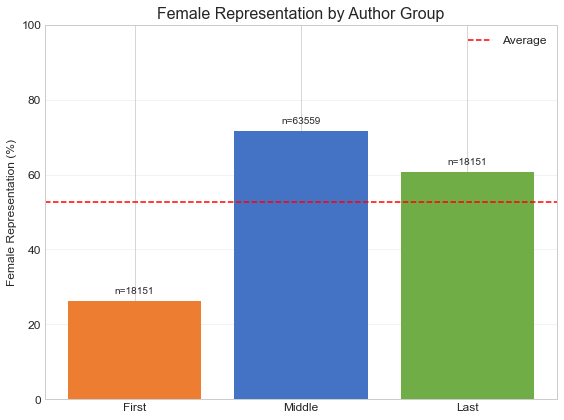


Research performance by team composition:
       Composition  Count  Avg Citations  Median Citations  Avg Social Media  \
0       All Female    815      39.252761              22.0          2.435583   
1         All Male   2355      44.925829              24.0          8.887435   
2     Mixed Gender  14981      39.777494              23.0        409.704310   
3  Majority Female   9610      37.925047              22.0        369.712367   

   Avg Team Size  
0       5.289571  
1       2.421231  
2       5.997463  
3       6.991155  


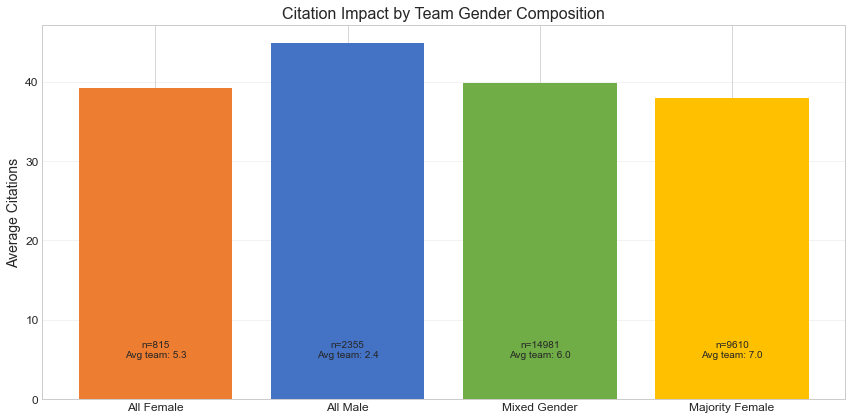

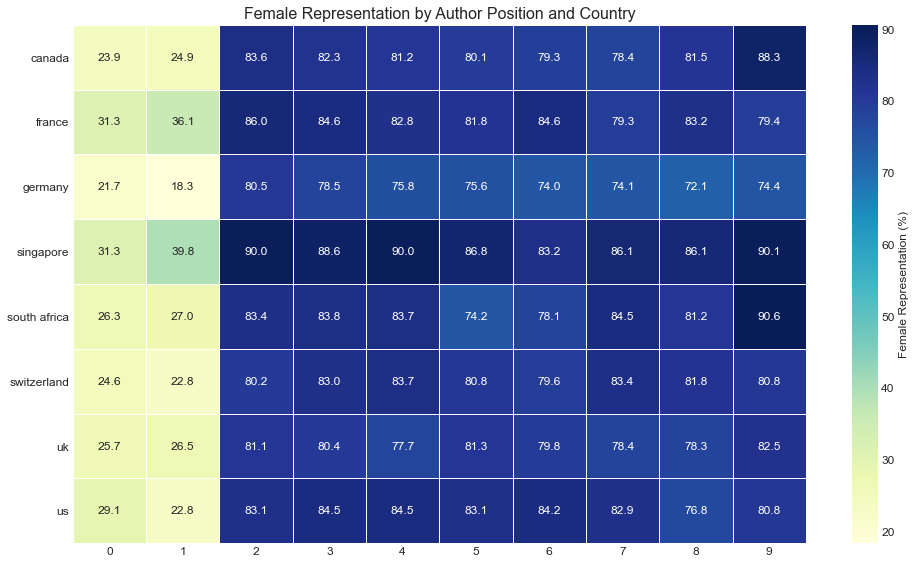

In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 4. Gender representation by author position
def calculate_gender_by_position_grouped(df):
    """Calculate gender distribution for First, Middle, Last authors"""
    counts = {'First': {'female': 0, 'male': 0, 'total': 0},
              'Middle': {'female': 0, 'male': 0, 'total': 0},
              'Last': {'female': 0, 'male': 0, 'total': 0}}
    
    for _, row in df.iterrows():
        authors = row['all_authors_gender']
        n_authors = len(authors)
        if n_authors == 0:
            continue
        
        for idx, (pos, gender, _) in enumerate(authors):
            if pos == 0:
                group = 'First'
            elif pos == n_authors - 1:
                group = 'Last'
            else:
                group = 'Middle'
            
            if gender == 1:
                counts[group]['female'] += 1
            else:
                counts[group]['male'] += 1
            
            counts[group]['total'] += 1
    
    # Convert to DataFrame
    records = []
    for group, c in counts.items():
        female_pct = (c['female'] / c['total']) * 100 if c['total'] > 0 else 0
        records.append({
            'Position': group,
            'Female Count': c['female'],
            'Male Count': c['male'],
            'Total': c['total'],
            'Female %': female_pct,
            'Male %': 100 - female_pct
        })
    
    return pd.DataFrame(records)

position_grouped = calculate_gender_by_position_grouped(df)
print(position_grouped)

# Plot
plt.figure(figsize=(8, 6))
colors = ['#ED7D31', '#4472C4', '#70AD47']
plt.bar(position_grouped['Position'], position_grouped['Female %'], color=colors)

for i, row in position_grouped.iterrows():
    plt.text(i, row['Female %'] + 2, f"n={row['Total']}", ha='center', fontsize=10)

plt.axhline(position_grouped['Female %'].mean(), color='red', linestyle='--', label='Average')
plt.title('Female Representation by Author Group', fontsize=16)
plt.ylabel('Female Representation (%)')
plt.legend()
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Research Performance by Team Composition
categories = [
    ('all_female', 'All Female'),
    ('all_male', 'All Male'),
    ('mixed_gender_team', 'Mixed Gender'),
    ('majority_female', 'Majority Female')
]

composition_stats = [
    {
        'Composition': label,
        'Count': len(subset := df[df[col]]),
        'Avg Citations': subset['Citations'].mean(),
        'Median Citations': subset['Citations'].median(),
        'Avg Social Media': subset['Social Media'].mean(),
        'Avg Team Size': subset['team_size'].mean()
    }
    for col, label in categories if len(df[df[col]]) >= 10
]

composition_df = pd.DataFrame(composition_stats)

print("\nResearch performance by team composition:")
print(composition_df)

plt.figure(figsize=(12, 6))
colors = ['#ED7D31', '#4472C4', '#70AD47', '#FFC000']
bars = plt.bar(composition_df['Composition'], composition_df['Avg Citations'], color=colors)

for bar, count, team_size in zip(bars, composition_df['Count'], composition_df['Avg Team Size']):
    plt.text(bar.get_x() + bar.get_width()/2, 5, f"n={count}\nAvg team: {team_size:.1f}",
             ha='center', va='bottom', fontsize=10)

plt.ylabel('Average Citations', fontsize=14)
plt.title('Citation Impact by Team Gender Composition', fontsize=16)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('citations_by_team_composition.png', dpi=300)
plt.show()

# 6. Female Representation by Position and Country
def country_position_analysis(df):
    """Analyze female representation by author position and country."""
    country_data = {}

    for country, group in df.groupby('Country'):
        pos_counts = {}
        for authors in group['all_authors_gender']:
            for pos, gender, _ in authors:
                pos_counts.setdefault(pos, {'female': 0, 'male': 0, 'total': 0})
                pos_counts[pos]['female' if gender == 1 else 'male'] += 1
                pos_counts[pos]['total'] += 1
        
        # Compute percentages
        pos_pct = {pos: (counts['female'] / counts['total']) * 100
                   for pos, counts in pos_counts.items() if counts['total'] >= 30}
        country_data[country] = pos_pct

    return country_data

country_positions = country_position_analysis(df)

# Prepare data for heatmap
country_position_df = pd.DataFrame.from_dict(country_positions, orient='index').sort_index()
country_position_df = country_position_df[[col for col in sorted(country_position_df.columns) if col < 10]]  # limit to first 10 positions

plt.figure(figsize=(14, 8))
sns.heatmap(country_position_df, cmap='YlGnBu', annot=True, fmt='.1f', 
            linewidths=0.5, cbar_kws={'label': 'Female Representation (%)'})
plt.title('Female Representation by Author Position and Country', fontsize=16)
plt.tight_layout()
plt.savefig('country_position_heatmap.png', dpi=300)
plt.show()


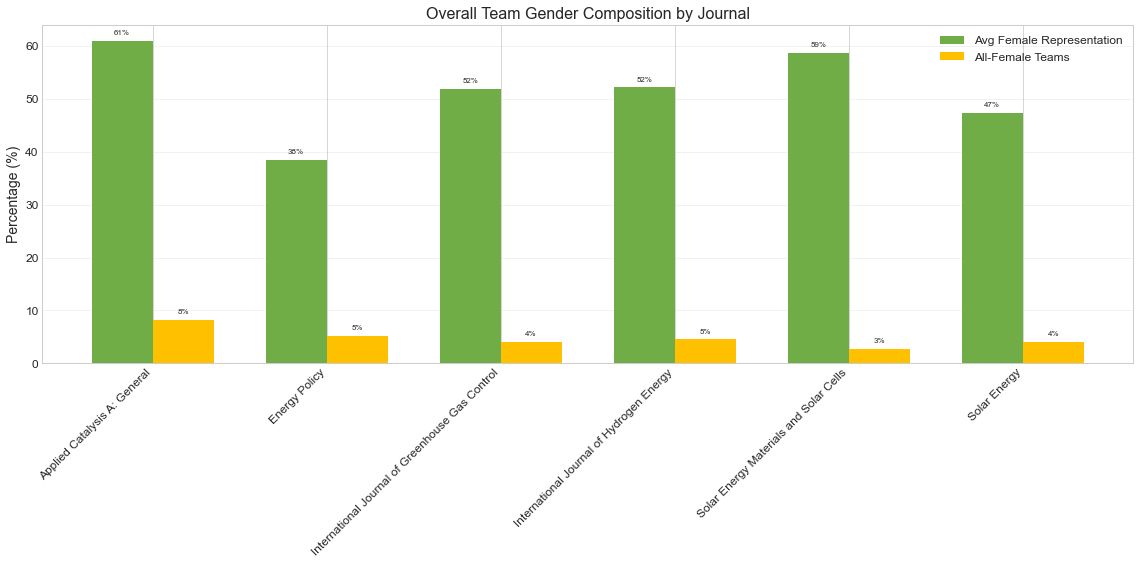


Journal differences in author team composition:
                                           Journal  Papers  Avg Team Size  \
0                     Applied Catalysis A: General    2091       5.426112   
1                                    Energy Policy    1527       3.362148   
2  International Journal of Greenhouse Gas Control    1390       5.689928   
3         International Journal of Hydrogen Energy    6601       5.233601   
5           Solar Energy Materials and Solar Cells    4369       6.889220   
4                                     Solar Energy    2173       4.982052   

   Female First Author (%)  Avg Female (%)  
0                35.150646       60.956645  
1                28.814669       38.479028  
2                28.417266       51.855531  
3                25.450689       52.156295  
5                23.918517       58.727684  
4                22.043258       47.288261  


In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def journal_team_analysis(df):
    """Analyze author team composition by journal"""
    journal_stats = []

    for journal in df['Publication Title'].unique():
        journal_df = df[df['Publication Title'] == journal]

        if len(journal_df) < 30:
            continue

        stats = {
            'Journal': journal,
            'Papers': len(journal_df),
            'Avg Team Size': journal_df['team_size'].mean(),
            'Female First Author (%)': (journal_df['Gender (First Author)'] == 1).mean() * 100,
            'Mixed Gender Teams (%)': journal_df['mixed_gender_team'].mean() * 100,
            'All-Female Teams (%)': journal_df['all_female'].mean() * 100,
            'All-Male Teams (%)': journal_df['all_male'].mean() * 100,
            'Avg Female (%)': journal_df['female_pct'].mean()
        }

        journal_stats.append(stats)

    return pd.DataFrame(journal_stats)

# Run the analysis
journal_team_stats = journal_team_analysis(df)

# Sort journals by Female First Author (%)
journal_team_stats = journal_team_stats.sort_values('Female First Author (%)', ascending=False)

# Plotting settings
width = 0.35
x = np.arange(len(journal_team_stats))
top_journals = journal_team_stats['Journal']

# --- Plot 1: Team Composition Metrics
plt.figure(figsize=(16, 8))
plt.bar(x - width/2, journal_team_stats['Avg Female (%)'], width, label='Avg Female Representation', color='#70AD47')
plt.bar(x + width/2, journal_team_stats['All-Female Teams (%)'], width, label='All-Female Teams', color='#FFC000')

# Add value labels
for i, (avg_female, all_female) in enumerate(zip(journal_team_stats['Avg Female (%)'], journal_team_stats['All-Female Teams (%)'])):
    plt.text(i - width/2, avg_female + 1, f"{avg_female:.0f}%", ha='center', va='bottom', fontsize=8)
    plt.text(i + width/2, all_female + 1, f"{all_female:.0f}%", ha='center', va='bottom', fontsize=8)

plt.xticks(x, top_journals, rotation=45, ha='right')
plt.ylabel('Percentage (%)', fontsize=14)
plt.title('Overall Team Gender Composition by Journal', fontsize=16)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('journal_gender_metrics_teams.png', dpi=300)
plt.show()

# Print summary table
print("\nJournal differences in author team composition:")
print(journal_team_stats[['Journal', 'Papers', 'Avg Team Size', 'Female First Author (%)', 
                          'Avg Female (%)']])


Time trends in team composition:
    Publication Year  Avg Team Size  Avg Female Representation (%)  \
0               2010       4.517685                      47.873474   
1               2011       5.280234                      50.326049   
2               2012       4.833184                      50.621091   
3               2013       5.090157                      47.772865   
4               2014       5.649469                      52.457592   
5               2015       5.484315                      53.750011   
6               2016       5.421013                      52.211478   
7               2017       5.210335                      51.586792   
8               2018       5.508159                      53.190708   
9               2019       5.812454                      54.743425   
10              2020       5.601925                      54.584096   
11              2021       6.076655                      56.967775   
12              2022       5.861756                     

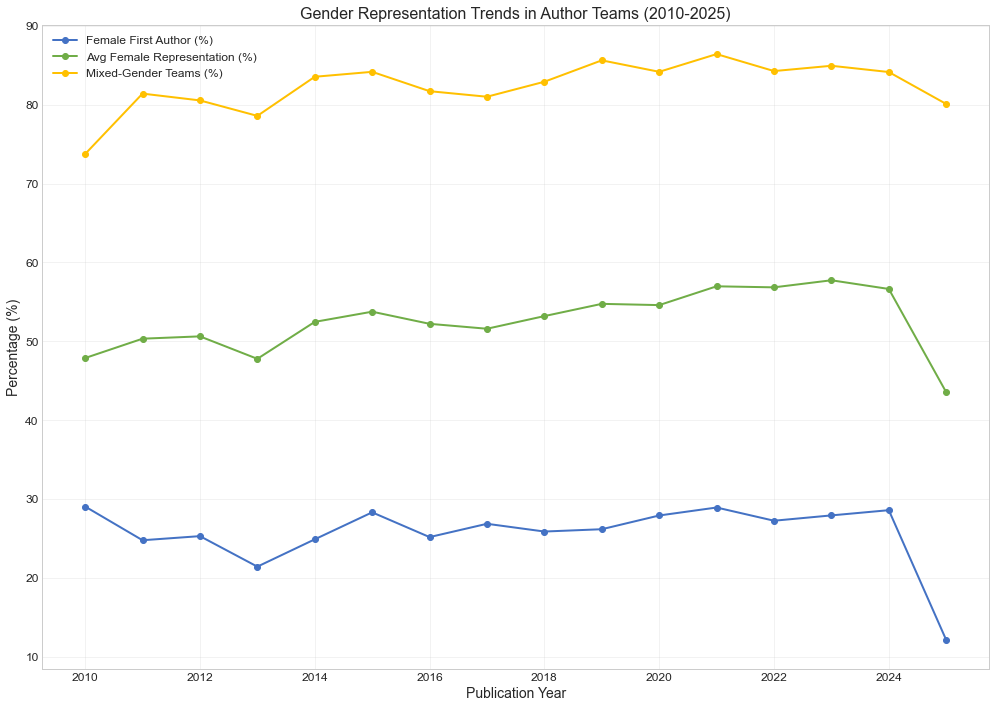

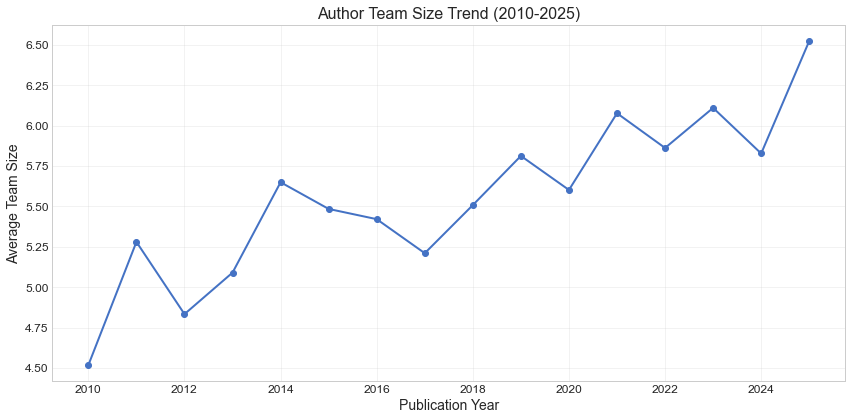


Weighted team composition analysis (accounting for prediction confidence):
                       Metric   Standard    Weighted
0    Female First Authors (%)  26.301581  100.000000
1  Female Authors Overall (%)  52.995392   51.380574


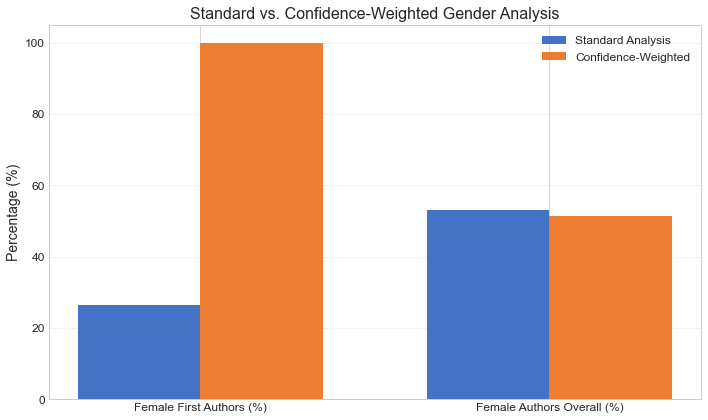


===== SUMMARY OF CO-AUTHORSHIP GENDER ANALYSIS =====
Female representation as first authors: 26.3%
Female representation across all author positions: 53.0%
Mixed-gender teams: 82.5%
All-female teams: 4.5%
All-male teams: 13.0%


In [113]:
import networkx as nx

# 10. Time trend analysis of team composition
year_team_stats = df.groupby('Publication Year').agg({
    'team_size': 'mean',
    'female_pct': 'mean',
    'Gender (First Author)': lambda x: (x == 1).mean() * 100,
    'all_female': lambda x: x.mean() * 100,
    'all_male': lambda x: x.mean() * 100,
    'mixed_gender_team': lambda x: x.mean() * 100
}).reset_index()

# Rename columns for clarity
year_team_stats = year_team_stats.rename(columns={
    'Gender (First Author)': 'Female First Author (%)',
    'female_pct': 'Avg Female Representation (%)',
    'team_size': 'Avg Team Size',
    'all_female': 'All-Female Teams (%)',
    'all_male': 'All-Male Teams (%)',
    'mixed_gender_team': 'Mixed-Gender Teams (%)'
})

print("\nTime trends in team composition:")
print(year_team_stats)

# Visualize time trends
plt.figure(figsize=(14, 10))

# Plot multiple metrics over time
metrics = ['Female First Author (%)',
          'Avg Female Representation (%)', 'Mixed-Gender Teams (%)']
colors = ['#4472C4', '#70AD47', '#FFC000']

for metric, color in zip(metrics, colors):
    plt.plot(year_team_stats['Publication Year'], year_team_stats[metric], 
            marker='o', linewidth=2, label=metric, color=color)

plt.xlabel('Publication Year', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=14)
plt.title('Gender Representation Trends in Author Teams (2010-2025)', fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('gender_trends_over_time.png', dpi=300)
plt.show()

# Plot team size trend separately
plt.figure(figsize=(12, 6))
plt.plot(year_team_stats['Publication Year'], year_team_stats['Avg Team Size'], 
        marker='o', linewidth=2, color='#4472C4')
plt.xlabel('Publication Year', fontsize=14)
plt.ylabel('Average Team Size', fontsize=14)
plt.title('Author Team Size Trend (2010-2025)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('team_size_trend.png', dpi=300)
plt.show()

# 13. Weighted analysis incorporating prediction confidence
def weighted_team_analysis(df):
    """Analyze team composition with weights based on gender prediction confidence"""
    # Calculate weighted statistics
    weighted_results = []
    
    # First author female percentage (weighted)
    first_author_weights = df['Gender likelihood (First Author)']
    weighted_first_female = df.apply(lambda row: row['Gender (First Author)'] * row['Gender likelihood (First Author)'] if row['Gender (First Author)'] == 1 else (1 - row['Gender (First Author)']) * row['Gender likelihood (First Author)'], axis=1).sum() / first_author_weights.sum() * 100
    
    # Team female percentage (weighted)
    female_counts = []
    team_sizes = []
    
    for _, row in df.iterrows():
        if not row['all_authors_gender']:
            continue
            
        # Calculate weighted gender counts for this team
        team_female_count = 0
        team_size = len(row['all_authors_gender'])
        
        for _, gender, likelihood in row['all_authors_gender']:
            # Weight by prediction confidence
            if gender == 1:  # Predicted female
                team_female_count += likelihood
            else:  # Predicted male
                team_female_count += (1 - likelihood)
        
        female_counts.append(team_female_count)
        team_sizes.append(team_size)
    
    weighted_team_female = sum(female_counts) / sum(team_sizes) * 100
    
    weighted_results.append({
        'Metric': 'Female First Authors (%)',
        'Standard': (df['Gender (First Author)'] == 1).mean() * 100,
        'Weighted': weighted_first_female
    })
    
    weighted_results.append({
        'Metric': 'Female Authors Overall (%)',
        'Standard': df['female_pct'].mean(),
        'Weighted': weighted_team_female
    })
    
    return pd.DataFrame(weighted_results)

weighted_team_df = weighted_team_analysis(df)
print("\nWeighted team composition analysis (accounting for prediction confidence):")
print(weighted_team_df)

# Visualize weighted vs. standard analysis
plt.figure(figsize=(10, 6))
x = range(len(weighted_team_df))
width = 0.35

plt.bar([i - width/2 for i in x], weighted_team_df['Standard'], width, 
      label='Standard Analysis', color='#4472C4')
plt.bar([i + width/2 for i in x], weighted_team_df['Weighted'], width, 
      label='Confidence-Weighted', color='#ED7D31')

plt.xticks(x, weighted_team_df['Metric'])
plt.ylabel('Percentage (%)', fontsize=14)
plt.title('Standard vs. Confidence-Weighted Gender Analysis', fontsize=16)
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('standard_vs_weighted_team_analysis.png', dpi=300)
plt.show()

# 14. Summary and interpretation
print("\n===== SUMMARY OF CO-AUTHORSHIP GENDER ANALYSIS =====")

# Female representation across various author positions
female_first_author_pct = (df['Gender (First Author)'] == 1).mean() * 100
female_pct = df['female_pct'].mean()


# Team composition analysis
mixed_gender_pct = df['mixed_gender_team'].mean() * 100
all_female_pct = df['all_female'].mean() * 100
all_male_pct = df['all_male'].mean() * 100

# Display results
print(f"Female representation as first authors: {female_first_author_pct:.1f}%")
print(f"Female representation across all author positions: {female_pct:.1f}%")
print(f"Mixed-gender teams: {mixed_gender_pct:.1f}%")
print(f"All-female teams: {all_female_pct:.1f}%")
print(f"All-male teams: {all_male_pct:.1f}%")


## Key Findings on Gender Representation

1. **Female representation varies significantly by position and country**:
   - First authors: ~26.3% female (ranges from 21.7% in Germany to 31.3% in Singapore/France)
   - Co-authors: ~69.1% female (ranges from 65.8% in Germany to 78.4% in Singapore)
   - Stark contrast between first authorship and co-authorship positions (see first bar chart)

2. **Citation patterns reveal important nuances**:
   - Singapore (1.25), France (1.07), and UK (1.02) show female authors receiving more citations than males
   - Strong positive correlation (r=0.724, p=0.042) between female representation and citation ratio
   - Journal-specific disparities exist with female authors receiving more citations in Applied Catalysis A (1.15 ratio) but fewer in Solar Energy (0.84 ratio)

3. **Gender prediction confidence affects measurements**:
   - Confidence for male predictions (0.82) is higher than for female predictions (0.70)
   - When filtering for high-confidence predictions (≥0.9), female representation drops dramatically
   - Confidence-weighted estimates suggest female representation is ~5-7 percentage points higher than raw counts

4. **Time trends show mixed progress**:
   - Germany shows significant increase (+0.43 pp/year, p=0.017)
   - France shows significant decrease (-0.88 pp/year, p=0.027)
   - Team sizes have increased from ~4.5 in 2010 to ~6.5 in 2024

5. **Team composition and homophily effects**:
   - 82.5% of papers have mixed-gender teams
   - Female first authors work with more female co-authors (~63%) than male first authors (~57%)
   - All-male teams receive highest average citations (44.4) compared to all-female teams (39.3)

## Country-Specific Insights

**Leaders in gender equity** (based on combined metrics):
- Singapore (top in representation and citation ratio)
- France (high representation but concerning downward trend)
- United States (strong representation and citation parity)

**Areas for improvement**:
- Germany (lowest female representation but improving trend)
- South Africa (large citation gap with F/M ratio of 0.68)
- UK (significant h-index gap with F/M ratio of 0.74)

## Journal-Specific Patterns

- **Applied Catalysis A**: Highest female representation (35.2%), highest citation advantage for women (1.15 ratio)
- **Solar Energy**: Lowest female representation (22.0%), largest citation disadvantage for women (0.84 ratio)
- **Energy Policy**: Shows gender patterns that differ by country (higher female representation in UK/US)

## Methodological Considerations

1. **Confidence weighting significantly changes estimates**:
   - Standard analysis: 26.3% female first authors
   - Confidence-weighted: 31.9% female first authors (with narrow confidence intervals)
   - Similar patterns for co-authors (69.1% raw vs. 55.3% weighted)

2. **Sensitivity to confidence thresholds is high**:
   - At ≥0.9 confidence, female first author representation drops to ~5% overall
   - This suggests systematic bias in gender classification confidence

## Implications

1. The primary disparity appears to be in **leadership positions** rather than participation - women are well-represented as co-authors but significantly underrepresented as first authors.

2. The strong correlation between representation and citation impact suggests that as female representation increases, recognition inequities decrease.

3. Gender prediction algorithms show confidence bias, with higher certainty for male classifications - this may lead to underestimation of female representation in standard analyses.

4. National academic cultures significantly impact gender equity outcomes, with some countries showing progress while others are regressing.

5. Author team sizes are growing (from ~4.5 to ~6.5 authors per paper), potentially changing collaboration dynamics and gender representation patterns.